# Charge injection on a bare ETROC2 **v2.03** die: the same measurements, an internal voltage reference, and a supply-rail axis

**Chips** `ET2p03_BARE9` and `ET2p03_BARE7` — two ETROC2 **version 2.03 bare dies, with no LGAD
bonded to either.**

"Gain" in this notebook always means the **preamp gain**: the charge-to-threshold response of
the front end, in threshold-DAC LSB per fC. **No sensor multiplication is involved in any
measurement in this folder**, here or in the hybrid notebook 02 — the charge is injected by the
chip's own internal injector directly at the preamplifier input, so a bonded LGAD contributes
its capacitance and nothing else.
**Campaign** FNAL bench, August 2024, total-ionising-dose (X-ray) test: 0, 200 and 400 MRad.
**Temperature** −23.2 to −23.9 °C, from directory names only.
**Pixels** 6: (row, col) ∈ {(0,0), (0,14), (3,0), (3,14), (12,0), (12,14)}.
**Charges** 6, 8, 10, 15 and 22 fC. **Rails** VA 0.85–1.40 V at VD 1.20 V for the threshold
scans; a separate 94-point VA × VD grid at a fixed 10 fC. **Every VA and VD number in this
notebook is a power-supply setting, not a voltage at the chip** — see the section below.

This is the third measurement notebook of the folder and the ET2.03 counterpart of
`01_bare_et2p01_tid_jan2024.ipynb`. It imports the same `qinj_common.py`, so the turn-off
estimator, the weighted gain fit, the shared-σ S-curve fit, the TOT log law and the
quantisation floor are the same functions that produced the two January-2024 results. Where
this campaign forces a departure from that path — and there is exactly one, over the turn-off
in section 5 — the departure is measured rather than asserted.

---

## What is different about ET2.03, and what is not

The two January-2024 campaigns both used **ET2.01** silicon. Between that revision and this one
the ETROC2 reference manual records two changes, and only two that touch anything measured here:

* **2.01 → 2.02** fixed the **on-chip voltage reference**, which on 2.01 read about 167 mV low,
  together with the wireless-sensor I²C ground and the eFuse clock.
* **2.02 → 2.03** added eight dummy bump pads per pixel — a bonding change, not a circuit one.

The consequence for this notebook is the first one. On ET2.01 the threshold DAC was driven from
an **external 1.0 V reference**; on ET2.03 it is driven from the **chip's own reference
generator**. So the DAC-to-millivolt scale on this revision is set by a circuit inside the chip
that is itself powered from the analog rail, and the campaign varied that rail deliberately.
Every absolute DAC number below therefore has to be read as *this chip, at this VA*, and the
threshold axis is kept as **`offset = dac − BL`** for the same reason it is in notebooks 01
and 02, only more so.

## What the register dumps prove, and what they do not

Three `ChipConfig` register read-backs survive from this campaign (BARE9 at 200 MRad, BARE7 at
0 MRad, BARE7 at the end of its 200 MRad step). They agree on every field that matters here:

* `VrefGen_PD = 0` — the field is active-high power-down, so **the internal reference generator
  was powered up**.
* `RefStrSel = 3` — the default reference-strobe selection, which is what puts the TDC
  calibration window at 3.125 ns and makes `CLK_NS` the right constant.
* `TS_PD = 0` — the on-chip temperature sensor was powered up.

**None of that proves the internal reference was *used*.** Internal versus external VRef is
board wiring; there is no register bit that reports which one is connected, so a powered
generator is a necessary and not a sufficient condition. Likewise `TS_PD = 0` says the
temperature sensor had power, not that anyone read it — and **no VTemp reading is stored
anywhere in this campaign**. Both statements are carried through to the caveats.

## The rails are power-supply settings, not chip voltages

`va_V` and `vd_V` are parsed from directory names such as `1p2VD_1p2VA`, and those names record
**what was dialled on the bench power supply**. The campaign's own logbook states the
correspondence in its first two lines, and it is staged verbatim here as
`data/bare_et2p03_tid_aug2024/info_BARE{7,9}_voltage_scan.txt`:

> `Nominal Analog 1.2V = 1.4V on power supply`
> `Nominal Digital 1.2V = 1.25V on power supply`

So the intended operating point on **both** rails was 1.2 V *at the chip*, and the difference is
the IR drop over the cables and the board: **0.20 V analog, 0.05 V digital**. Three consequences
run through everything below, and section 1 prints the mapping table.

1. **Only VA 1.40 V (supply) is nominal.** The dose-series reference used throughout this
   notebook is VA 1.20 V (supply) ≈ **1.00 V at the chip, about 0.2 V UNDER-VOLTED**. It is the
   reference because it is the only analog setting with a 0 MRad money plot, not because it is
   the right operating point. Section 6 quotes the 200 → 400 MRad step at VA 1.40 V (supply)
   beside it, which is the nominal-condition version of the same measurement.
2. **The VA scan is an under-voltage scan.** VA 0.85 → 1.40 V (supply) is ~0.65 → ~1.20 V at the
   chip: it runs from roughly half the nominal analog rail up TO nominal, and never above it.
3. **VD 1.20 V (supply) ≈ 1.15 V at the chip is itself slightly below nominal**, and the rail
   scan's failures at VD 0.90 / 0.95 V (supply) are ~0.85 / ~0.90 V at the chip.

Subtracting a constant drop is an **approximation**: the drop is I·R and this campaign logged no
rail current at all, so every at-chip number is written with a `~` and should not be read at
better than about 50 mV. The supply setting is the RAW quantity and is what every table carries.

## The DAC LSB on this revision

`qinj_common.LSB_MV = 400 mV / 2¹⁰ = 0.390625 mV` is code-verified against the `tamalero`
threshold-DAC limits (600 to 1000 mV) and is what notebooks 01 and 02 use. **It is carried
here as an assumption, not as a measurement.** The ETROC2 reference manual documents the TDC
and the register map but does not pin the threshold-DAC full scale to the reference source, and
this campaign took no reference calibration. Every millivolt number below is therefore
`DAC × 0.390625 mV` with that assumption attached, and the DAC numbers themselves are the
primary quantities. Section 13 shows directly that the DAC scale on this chip moves with the
analog rail, which is the strongest evidence available here that the assumption is a weak one.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import qinj_common as Q
from qinj_style import apply_style

apply_style(0.55)
pd.set_option("display.width", 200, "display.max_columns", 80)

LEDGER = []          # every recomputed-vs-reduction comparison lands here
RESULTS = {}         # the numbers this notebook exports to notebook 04

print("DAC LSB (assumed)    %.6f mV" % Q.LSB_MV)
print("TDC reference clock  %.3f ns   (RefStrSel = 3, from the register dump)" % Q.CLK_NS)
print("electrons per fC     %.3f" % Q.E_PER_FC)
print("operating point      threshold = BL + %d DAC" % Q.OP_OFFSET)
print("charges injected     %s fC" % Q.ET2P03_CHARGES)
print("pixels scanned       %s" % Q.ET2P03_PIXELS)

DAC LSB (assumed)    0.390625 mV
TDC reference clock  3.125 ns   (RefStrSel = 3, from the register dump)
electrons per fC     6241.509
operating point      threshold = BL + 20 DAC
charges injected     [6, 8, 10, 15, 22] fC
pixels scanned       [(0, 0), (0, 14), (3, 0), (3, 14), (12, 0), (12, 14)]


## 1. Provenance

Everything read here is under `data/bare_et2p03_tid_aug2024/`. It is the reduction of two raw
trees, neither of which is staged: `fermilab-etroc3:/home/daq/tmp/TID_August/` (6.2 GB, the
working copy) and the removable exFAT disk `X9`, tree `et2p03_qinj_data/2024-08-*`, of which
25.1 GB was copied. `data/bare_et2p03_tid_aug2024/DECODE_README.md` is the reduction's own
documentation, shipped verbatim, and `code/` holds the scripts that produced the tables —
including `decoding.py`, which is this repository's own `DecodeBinary`, copied byte for byte.
`reduce_tid.py` and `DECODE_README.md` were reissued when the per-hit CAL window of section 4.4
was added; every column the earlier reduction wrote is bit-identical in this one, and the window
only adds nine columns beside them.

| file | RAW / DERIVED | what it is |
|---|---|---|
| `tid_et2p03_points_all.feather` | RAW + DERIVED | the per-point TOA/TOT/CAL mean and standard deviation, one row per decoded point directory, 29 922 × 43 (the last nine are the CAL-windowed moments of section 4.4). **The union table** — the only one carrying the 200 and 400 MRad money plots. |
| `tid_et2p03_turnoff_all.csv` | RAW | one row per (condition, pixel, charge) discriminator binary search, 450 of them, with the whole search written out as `search_trace`. |
| `tid_et2p03_noiseonly_all.csv` | RAW | the `quietCB` noise scans, 90 of them: a dense one-DAC-step scan of the trigger-bit counter across the noise peak, taken **inside every configuration**. |
| `tid_et2p03_configs_all.csv` | RAW + DERIVED | the conditions grid, one row per run or voltage-scan sub-run. |
| `tid_et2p03_blnw.csv` | RAW | the `ET2p03_BARE9` autocalibration baseline and noise-width maps of 2024-08-03, all 256 pixels. |
| `tid_et2p03_chipconfig.csv` | RAW, decoded | the three register read-backs, 135 decoded fields plus the raw `PeriCfg0..31` bytes. |
| `tid_et2p03_points.feather` and the three other non-`_all` tables | RAW + DERIVED | the `TID_August` working copy alone, where the dosed data are the 10 fC rail scans only. Staged so that the difference between the two families is demonstrable rather than asserted. |

The two ET2.03 auxiliary tables are also staged under `data/census/` for notebook 00. They are
byte-identical; the cell below prints both md5s so that is checkable rather than claimed.

In [2]:
prov = pd.DataFrame([Q.file_row(p) for p in sorted(Q.ET2P03_DIR.iterdir()) if p.is_file()])
prov["MB"] = (prov.bytes / 1e6).round(3)
print(prov[["file", "bytes", "MB", "md5"]].to_string(index=False))
code = pd.DataFrame([Q.file_row(p) for p in sorted((Q.ET2P03_DIR / "code").iterdir()) if p.is_file()])
print("\ncode/ (the reduction scripts, shipped for provenance):")
print(code[["file", "bytes", "md5"]].to_string(index=False))
print("\nthe repository's own decoder, TestBeam/condor_at_lxplus/core/decoding.py, md5 289ef6cb7b7e48589e02d817de5060ed")
print("staged code/decoding.py                                              md5",
      code.loc[code.file == "decoding.py", "md5"].iloc[0])
for a, b in [("tid_et2p03_blnw.csv", "aux_et2p03_blnw.csv"),
             ("tid_et2p03_chipconfig.csv", "aux_et2p03_chipconfig.csv")]:
    print("%-28s %s   ==   data/census/%-28s %s"
          % (a, Q.md5(Q.ET2P03_DIR / a), b, Q.md5(Q.CENSUS_DIR / b)))

                         file   bytes    MB                              md5
             DECODE_README.md   38569 0.039 d230a08548ff4d42fc75529613aa9c82
                PROVENANCE.md   13503 0.014 2b3601b4e0a3bf81d77fea878ac1795f
  info_BARE7_voltage_scan.txt    1694 0.002 b579ec8c8eb3ba7866e46eafb745f3e3
  info_BARE9_voltage_scan.txt    1703 0.002 d79ee484fd73b8d85b6c3824c96dce71
          tid_et2p03_blnw.csv   14833 0.015 96da68fed9fef08cf920002f4bfa5023
    tid_et2p03_chipconfig.csv    3164 0.003 5aef7758fd020bddf206430880301a20
       tid_et2p03_configs.csv   24809 0.025 d857637ee4f399ffab5353dd119ad860
   tid_et2p03_configs_all.csv   29923 0.030 1fea689e9f16a8bfb9cb2858f82a3fb0
     tid_et2p03_noiseonly.csv    5411 0.005 99257c0ca258a409cf814da5a2ee80d3
 tid_et2p03_noiseonly_all.csv   43642 0.044 7da9e2675ef3b38aa343a5e64c69be41
    tid_et2p03_points.feather  610234 0.610 11832f9bef784d13102d9625180c068d
tid_et2p03_points_all.feather 4949330 4.949 c1a669ff60e88b8697ef233cf0402a21

In [3]:
print("RAILS: supply setting -> approximate voltage at the chip (constant-drop approximation)\n")
print("  analog drop %.2f V,  digital drop %.2f V\n" % (Q.VA_SUPPLY_DROP_V, Q.VD_SUPPLY_DROP_V))
print("  %-16s %-18s %s" % ("VA supply [V]", "~VA at chip [V]", "note"))
for vs, vc in Q.VA_SUPPLY_TABLE:
    note = ("NOMINAL operating point" if vs == Q.VA_NOMINAL_SUPPLY_V else
            "the dose-series reference, ~%.2f V under nominal" % (1.20 - vc) if vs == 1.20 else
            "under-voltage, ~%.2f V under nominal" % (1.20 - vc))
    print("  %-16.2f %-18s %s" % (vs, "~%.2f" % vc, note))
print("\n  %-16s %-18s %s" % ("VD supply [V]", "~VD at chip [V]", "note"))
for vs in (1.25, 1.20, 0.95, 0.90):
    note = ("NOMINAL" if vs == Q.VD_NOMINAL_SUPPLY_V else
            "what every threshold scan ran at, just below nominal" if vs == 1.20 else
            "rail-scan failure point (section 12)")
    print("  %-16.2f %-18s %s" % (vs, "~%.2f" % float(Q.vd_at_chip(vs)), note))
print("\nsource, staged verbatim (the campaign logbook, RAW):")
for f in ("info_BARE9_voltage_scan.txt", "info_BARE7_voltage_scan.txt"):
    head = open(Q.ET2P03_DIR / f).read().split("\n")
    print("  %-32s %6d B  md5 %s" % (f, (Q.ET2P03_DIR / f).stat().st_size, Q.md5(Q.ET2P03_DIR / f)))
    print("    " + head[0])
    print("    " + head[1])

RAILS: supply setting -> approximate voltage at the chip (constant-drop approximation)

  analog drop 0.20 V,  digital drop 0.05 V

  VA supply [V]    ~VA at chip [V]    note
  0.85             ~0.65              under-voltage, ~0.55 V under nominal
  1.00             ~0.80              under-voltage, ~0.40 V under nominal
  1.20             ~1.00              the dose-series reference, ~0.20 V under nominal
  1.40             ~1.20              NOMINAL operating point

  VD supply [V]    ~VD at chip [V]    note
  1.25             ~1.20              NOMINAL
  1.20             ~1.15              what every threshold scan ran at, just below nominal
  0.95             ~0.90              rail-scan failure point (section 12)
  0.90             ~0.85              rail-scan failure point (section 12)

source, staged verbatim (the campaign logbook, RAW):
  info_BARE9_voltage_scan.txt        1703 B  md5 d79ee484fd73b8d85b6c3824c96dce71
    Nominal Analog 1.2V = 1.4V on power supply
    Nominal 

In [4]:
PTS = Q.load_et2p03_points()
TOF = Q.load_et2p03_turnoff()
NOI = Q.load_et2p03_noiseonly()
CFG = Q.load_et2p03_configs()
MAP = Q.load_et2p03_tid_blnw()
REG = Q.load_et2p03_tid_chipconfig()
WORK = Q.load_et2p03_points(union=False)

print("points_all      %6d rows x %2d columns" % PTS.shape)
print("  money_plot    %6d   (threshold-scan points, one pixel each)" % (PTS.scan_family == "money_plot").sum())
print("  voltage_scan  %6d   (one fixed unrecorded threshold, 16 pixels pooled)"
      % (PTS.scan_family == "voltage_scan").sum())
print("turnoff_all     %6d binary searches" % len(TOF))
print("noiseonly_all   %6d quietCB noise scans" % len(NOI))
print("configs_all     %6d runs / sub-runs" % len(CFG))
print("blnw map        %6d pixels, %s" % (len(MAP), MAP.source.iloc[0]))
print("register dumps  %6d, %d decoded fields" % REG.shape)
print("working copy    %6d rows (TID_August alone) -- its money plots are at dose %s only"
      % (len(WORK), [float(x) for x in sorted(WORK[WORK.scan_family == "money_plot"].dose_MRad.dropna().unique())]))
print("\ndecode errors across the union table: %d"
      % int((PTS.decode_error.fillna("").astype(str).str.strip() != "").sum()))
mp_rows = PTS.scan_family == "money_plot"
print("hits at the named pixel                 %d" % PTS.loc[mp_rows, "n_hits"].sum())
print("hits before the pixel selection         %d" % PTS.loc[mp_rows, "n_hits_all_pixels"].sum())
print("removed by the only selection there is  %d  (%.3f %%)"
      % ((PTS.loc[mp_rows, "n_hits_all_pixels"] - PTS.loc[mp_rows, "n_hits"]).sum(),
         100 * (PTS.loc[mp_rows, "n_hits_all_pixels"] - PTS.loc[mp_rows, "n_hits"]).sum()
         / PTS.loc[mp_rows, "n_hits_all_pixels"].sum()))
Q.check("money-plot points in the union table", float(mp_rows.sum()), 29828, 0, "", LEDGER)
Q.check("hits behind them, before the pixel selection",
        float(PTS.loc[mp_rows, "n_hits_all_pixels"].sum()), 239969849, 0, "", LEDGER)
Q.check("hits removed by the pixel selection",
        float((PTS.loc[mp_rows, "n_hits_all_pixels"] - PTS.loc[mp_rows, "n_hits"]).sum()),
        49194, 0, "", LEDGER)
Q.check("binary searches", float(len(TOF)), 450, 0, "", LEDGER)
Q.check("noise scans", float(len(NOI)), 90, 0, "", LEDGER)

points_all       29922 rows x 43 columns
  money_plot     29828   (threshold-scan points, one pixel each)
  voltage_scan      94   (one fixed unrecorded threshold, 16 pixels pooled)
turnoff_all        450 binary searches
noiseonly_all       90 quietCB noise scans
configs_all        109 runs / sub-runs
blnw map           256 pixels, 2024-08-03_Array_Test_Results
register dumps       3, 135 decoded fields
working copy      3638 rows (TID_August alone) -- its money plots are at dose [0.0] only

decode errors across the union table: 0
hits at the named pixel                 239920655
hits before the pixel selection         239969849
removed by the only selection there is  49194  (0.021 %)
[OK  ] money-plot points in the union table                 recomputed 29828.0000  published 29828.0000  |d|   0.0000 (tol 0) 
[OK  ] hits behind them, before the pixel selection         recomputed 239969849.0000  published 239969849.0000  |d|   0.0000 (tol 0) 
[OK  ] hits removed by the pixel selection  

True

### The register dump, printed rather than described

In [5]:
FIELDS = ["VrefGen_PD", "RefStrSel", "TS_PD", "CLKSel", "PLL_BiasGen_CONFIG", "chargeInjectionDelay"]
have = [f for f in FIELDS if f in REG.columns]
print(REG[["source"] + have].to_string(index=False) if "source" in REG.columns
      else REG[have].to_string(index=False))
print("\nidentical on all three dumps:",
      {f: (REG[f].nunique() == 1) for f in have})
print("\nVrefGen_PD = 0 is active-high power-down: the internal reference generator was POWERED UP.")
print("It does not say the internal reference was USED — that is board wiring, with no register bit.")
print("TS_PD = 0 likewise says the temperature sensor had power, not that it was read;")
print("no VTemp value is stored anywhere in this campaign.")

 VrefGen_PD  RefStrSel  TS_PD  CLKSel  PLL_BiasGen_CONFIG  chargeInjectionDelay
          0          3      0       1                   8                    10
          0          3      0       1                   8                    10
          0          3      0       1                   8                    10

identical on all three dumps: {'VrefGen_PD': True, 'RefStrSel': True, 'TS_PD': True, 'CLKSel': True, 'PLL_BiasGen_CONFIG': True, 'chargeInjectionDelay': True}

VrefGen_PD = 0 is active-high power-down: the internal reference generator was POWERED UP.
It does not say the internal reference was USED — that is board wiring, with no register bit.
TS_PD = 0 likewise says the temperature sensor had power, not that it was read;
no VTemp value is stored anywhere in this campaign.


## 2. The campaign: fourteen threshold-scan conditions and a rail grid

Unlike the January campaigns, this one holds temperature essentially fixed (−23.2 to −23.9 °C
throughout) and varies the **analog supply rail** instead. That is the axis that replaces the
dose-versus-temperature confound of notebook 01 — and it is also the axis that makes the
internal reference visible, because the reference generator is powered from that rail.

There are two families of acquisition and they must never be mixed in one fit:

* **money plots** — a full threshold × charge scan at one pixel at a time, 29 828 points over
  fourteen conditions on two dies, at VD 1.20 V throughout;
* **rail scans** — 94 single acquisitions at a fixed 10 fC and a fixed but **unrecorded**
  threshold, each pooling all sixteen enabled pixels, over a VA × VD grid. Section 13.

In [6]:
M = PTS[PTS.scan_family == "money_plot"].copy()
V = PTS[PTS.scan_family == "voltage_scan"].copy()


def clab(chip, dose, va):
    """One short label per measurement condition: chip, dose, analog rail."""
    d = "dose untagged" if pd.isna(dose) else f"{int(dose)} MRad"
    return f"{str(chip).replace('ET2p03_', '')}, {d}, VA {va:.2f} V (supply)"


COND = (TOF.groupby("config")
        .agg(chip=("chip", "first"), dose=("dose_MRad", "first"), va=("va_V", "first"),
             vd=("vd_V", "first"), temp=("temperature_C", "first"), day=("day", "first"),
             elapsed_h=("elapsed_h", "first"), n_turnoff=("turnoff_dac", "size"))
        .reset_index())
npts = (M.assign(px=[f"{int(r)},{int(c)}" for r, c in zip(M.row, M.col)])
        .groupby("config").agg(points=("dac", "size"), hits=("n_hits", "sum"),
                               dac_lo=("dac", "min"), dac_hi=("dac", "max"),
                               pixels=("px", "nunique"), charges=("charge_fC", "nunique")).reset_index())
COND = COND.merge(npts, on="config", how="left")
COND["label"] = [clab(c, d, v) for c, d, v in zip(COND.chip, COND.dose, COND.va)]
COND = COND.sort_values(["chip", "dose", "va"], na_position="last").reset_index(drop=True)
print(COND[["label", "vd", "temp", "day", "elapsed_h", "n_turnoff", "points", "hits",
            "dac_lo", "dac_hi", "pixels", "charges"]].to_string(index=False))
print("\ntotals: %d money-plot points, %d hits, %d conditions with a turn-off scan, %d with a sweep"
      % (len(M), M.n_hits.sum(), len(COND), int(COND.points.notna().sum())))
print("pixels, every condition:", sorted(set(zip(M.row.astype(int), M.col.astype(int)))))
print("charges, every condition:", [float(c) for c in sorted(M.charge_fC.unique())], "fC")
print("temperatures seen      :", [float(t) for t in sorted(PTS.temperature_C.dropna().unique())], "degC")

                                   label  vd  temp                           day  elapsed_h  n_turnoff  points       hits  dac_lo  dac_hi  pixels  charges
       BARE7, 0 MRad, VA 0.85 V (supply) 1.2 -23.6 2024-08-14_Array_Test_Results        NaN         30  1656.0 13336805.0   593.0   750.0     6.0      5.0
       BARE7, 0 MRad, VA 1.00 V (supply) 1.2 -23.6 2024-08-14_Array_Test_Results        NaN         30  2374.0 19024944.0   660.0   881.0     6.0      5.0
       BARE7, 0 MRad, VA 1.20 V (supply) 1.2 -23.6 2024-08-14_Array_Test_Results        NaN         30  2964.0 23994179.0   733.0  1018.0     6.0      5.0
     BARE7, 200 MRad, VA 1.20 V (supply) 1.2 -23.9 2024-08-21_Array_Test_Results        NaN         30  3023.0 24272067.0   744.0  1018.0     6.0      5.0
       BARE9, 0 MRad, VA 0.85 V (supply) 1.2 -23.8                  not recorded        NaN         30  1168.0  9587407.0   693.0   797.0     6.0      5.0
       BARE9, 0 MRad, VA 1.20 V (supply) 1.2 -23.5                  no

Two entries in that table need saying out loud.

* The row whose dose reads **untagged** is the `2024-08-03` day directory. Its run directory is
  simply `1p2VD_1p2VA`, with no dose and no temperature token, so the reduction records
  `dose_MRad = NaN` rather than guessing. By its position in the campaign it is the 0 MRad set,
  and it is a **separate acquisition** from the identically-conditioned `TID_August` run — the
  two are not byte-duplicates. It carries thirty turn-off searches and six noise scans but **no
  threshold sweep**, so it contributes a baseline and a gain and nothing else — and that is
  exactly what makes it useful: it is an independent repeat of the 0 MRad, VA 1.20 V condition
  and therefore a **repeatability floor** against which the dose differences can be judged.
* **`BARE7` now has both ends of a dose step.** Its 0 MRad day (`2024-08-14`, 8.88 GB) lived on
  the removable disk `X9` alone until it was copied and decoded; with it, BARE7 spans
  **0 → 200 MRad at VA 1.20 V** (and 0 MRad at VA 0.85 and 1.00 V as well). It does not reach
  400 MRad — only `BARE9` has all three doses — but it is a **second die of the same revision
  with a real dose difference**, which is the one direct handle this folder has on whether the
  sign of the baseline shift is a property of the revision or of one die. Section 14.

### The three ET2.03 dies of August 2024, and what each one is for

Three `ET2p03_*` bare dies appear across this folder and they are easy to confuse. Only two of
them are in this notebook; the third is the reason notebook 00 can say anything at all about the
internal reference.

| die | role | evidence |
|---|---|---|
| **`ET2p03_BARE9`** | the TID series proper: 0 / 200 / 400 MRad, four analog rails | the X9 day directories `2024-08-03` (0 MRad, untagged), `-07` and `-08` (200 MRad), `-11` and `-12` (400 MRad), plus the `TID_August` working copy; the conditions table above |
| **`ET2p03_BARE7`** | second TID die, 0 → 200 MRad only | 0 MRad money plot on `2024-08-14` — that session's register dump is stamped 21:21:53, five minutes before irradiation step 3 opened at 21:27 in the campaign's own `cern_TID.ipynb` timeline (notebook 00 §7.7) — and 200 MRad on `2024-08-21`. Sections 14 and 14.1 |
| **`ET2p03_BARE4`** | **never irradiated**; the monitoring die | sat in the CERN climate chamber 2024-08-04 → 08-14, i.e. in parallel with BARE9's irradiation. All 140 of its baseline maps carry 0 MRad and `chip_name = ET2p03_BARE4`. It injected no charge, so it appears nowhere in this notebook — but it is the **only** ET2.03 internal-VRef and on-chip-VTemp record in existence, and notebook 00 §7.6 fits their temperature slopes from it |

So this notebook's dose statements rest on BARE9 (all three doses) and BARE7 (0 → 200 MRad), and
every reference-drift argument that reaches beyond them borrows BARE4's calibration through
notebook 00.

In [7]:
grid = (COND[COND.points.notna()]
        .pivot_table(index=["chip", "dose"], columns="va", values="points", dropna=False))
print("money-plot points per (chip, dose) x VA — blank means the condition was not taken\n")
print(grid.fillna(0).astype(int).replace(0, "—").to_string())
print("\nrail scans: %d sub-runs, %d of them with zero decoded hits" % (len(V), int((V.n_hits == 0).sum())))
print("VA supply values", [float(x) for x in sorted(V.va_V.unique())],
      "-> ~at chip", [round(float(Q.va_at_chip(x)), 2) for x in sorted(V.va_V.unique())])
print("VD supply values", [float(x) for x in sorted(V.vd_V.unique())],
      "-> ~at chip", [round(float(Q.vd_at_chip(x)), 2) for x in sorted(V.vd_V.unique())])

money-plot points per (chip, dose) x VA — blank means the condition was not taken

va                  0.85  1.00  1.20  1.40
chip         dose                         
ET2p03_BARE7 0.0    1656  2374  2964     —
             200.0     —     —  3023     —
             400.0     —     —     —     —
ET2p03_BARE9 0.0    1168     —  2376     —
             200.0  1153  1995  2425  2536
             400.0  1123  1927  2475  2633

rail scans: 94 sub-runs, 9 of them with zero decoded hits
VA supply values [0.85, 0.9, 0.95, 1.0, 1.1, 1.2, 1.3, 1.4] -> ~at chip [0.65, 0.7, 0.75, 0.8, 0.9, 1.0, 1.1, 1.2]
VD supply values [0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.2, 1.3, 1.4, 1.45] -> ~at chip [0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.25, 1.35, 1.4]


## 3. Baseline and noise width, measured inside every configuration

Notebooks 01 and 02 had to work hard for a baseline: an autocalibration map where one survived,
and the sweep's own starting threshold otherwise. This campaign is better off. Every one of the
fourteen conditions carries six `quietCB` **noise scans** — a dense, one-DAC-step scan of the
trigger-bit counter across the noise peak, taken with the charge injector off, in the
configuration itself.

The top of that peak is the threshold at which the noise alone is firing the discriminator
hardest, i.e. **the baseline**; `qinj_common.noise_peak` returns it together with the peak's
full width at half maximum. Both are used below, and both are cross-checked against the one
autocalibration map this campaign left behind.

In [8]:
rows = []
for _, r in NOI.iterrows():
    pk, pc, fw, ns = Q.noise_peak(r.scan_trace)
    rows.append(dict(config=r.config, row=int(r.row), col=int(r.col), BL=pk, peak_counts=pc,
                     NW_fwhm=fw, n_steps=ns, BL_raw=float(r.dac_at_triggerbits_max)))
BL = pd.DataFrame(rows)
print("baseline from the noise peak vs the reduction's own `dac_at_triggerbits_max`: max |diff| = %.3f DAC"
      % (BL.BL - BL.BL_raw).abs().max())

mp = MAP[[(r, c) in Q.ET2P03_PIXELS for r, c in zip(MAP.row, MAP.col)]][["row", "col", "baseline_DAC", "noise_width_DAC"]]
for cfg in COND.loc[(COND.va == 1.20) & (COND.dose.isna() | (COND.dose == 0)) & (COND.chip.str.contains("BARE9")), "config"]:
    b = BL[BL.config == cfg].merge(mp, on=["row", "col"]).sort_values(["row", "col"])
    print("\n%s  vs the 2024-08-03 autocalibration map" % cfg)
    print("  pixel          " + "  ".join(f"({r},{c})" for r, c in zip(b.row, b.col)))
    print("  noise peak BL  " + "  ".join(f"{v:6.0f}" for v in b.BL))
    print("  map BL         " + "  ".join(f"{v:6.0f}" for v in b.baseline_DAC))
    print("  difference     " + "  ".join(f"{v:+6.0f}" for v in b.BL - b.baseline_DAC))
    print("  peak FWHM      " + "  ".join(f"{v:6.2f}" for v in b.NW_fwhm))
    print("  map NW         " + "  ".join(f"{v:6.0f}" for v in b.noise_width_DAC))
Q.check("map baseline, pixel (0,0)", float(mp[(mp.row == 0) & (mp.col == 0)].baseline_DAC.iloc[0]),
        822, 0, "DAC", LEDGER)
Q.check("map baseline, pixel (12,14)", float(mp[(mp.row == 12) & (mp.col == 14)].baseline_DAC.iloc[0]),
        849, 0, "DAC", LEDGER)

baseline from the noise peak vs the reduction's own `dac_at_triggerbits_max`: max |diff| = 0.000 DAC

ET2p03_BARE9_1p2VD_1p2VA_m23p5C_0MRad  vs the 2024-08-03 autocalibration map
  pixel          (0,0)  (0,14)  (3,0)  (3,14)  (12,0)  (12,14)
  noise peak BL     822     827     825     834     831     847
  map BL            822     828     824     834     831     849
  difference         +0      -1      +1      +0      +0      -2
  peak FWHM        2.26    2.32    2.86    3.82    1.88    4.79
  map NW              3       4       5       4       5       4

1p2VD_1p2VA  vs the 2024-08-03 autocalibration map
  pixel          (0,0)  (0,14)  (3,0)  (3,14)  (12,0)  (12,14)
  noise peak BL     822     827     823     835     831     848
  map BL            822     828     824     834     831     849
  difference         +0      -1      -1      +1      +0      -1
  peak FWHM        1.88    2.89    3.03    4.70    2.08    4.39
  map NW              3       4       5       4       5       4
[OK

True

The noise-peak baseline reproduces the autocalibration map to within a couple of DAC on all six
pixels, on **two** independent acquisitions of the same condition, which is as good a
cross-check as this campaign can offer. The FWHM of the noise peak and the autocalibration `NW`
are correlated but are **not the same definition** — the map's `NW` comes from the
autocalibration accumulator, the FWHM from a threshold scan of the trigger-bit counter — so the
two are reported side by side below and never substituted for one another.

From here on, `BL` is the noise-peak baseline of the configuration the point was taken in.

In [9]:
# The reduction writes TWO sets of per-point moments (DECODE_README.md, section "CAL window"):
# the raw ones over every decoded hit, and a CAL-windowed set over the hits whose CAL code is
# within Q.CAL_WINDOW = 3 of that point's own CAL mode — the per-hit criterion the repository's
# test-beam pipeline applies (core/path_finder.py, core/extract_events_by_path.py). A hit with a
# wrong CAL has a wrong clock period, so its TOA (= TOA_code x 3.125 ns / CAL) and TOT are wrong;
# section 4.4 shows what that does to this campaign's data.
#
# From here on the plain column names carry the CAL-windowed moments and every result uses them.
# The raw moments stay available under a `_raw` suffix and are used in the explainer figures, in
# the before/after comparison of section 4.4, and wherever the question is what the DAQ recorded
# rather than what the TDC measured.
for c in ("n_hits", "toa_mean", "toa_std", "tot_mean", "tot_std", "cal_mean", "cal_std"):
    M[c + "_raw"] = M[c].to_numpy()
for c in ("toa_mean", "toa_std", "tot_mean", "tot_std", "cal_mean", "cal_std"):
    M[c] = M[c + "_cal"].to_numpy()
M["n_hits"] = M["n_hits_cal"].to_numpy()
M["cal_rms_gt2"] = M.cal_std_raw > 2      # the flag notebook 02 carries, on the RAW CAL spread
_RAW = Q.add_tdc_derived(M, toa="toa_mean_raw", toa_sd="toa_std_raw", tot="tot_mean_raw",
                         tot_sd="tot_std_raw", cal="cal_mean_raw")
M = Q.add_tdc_derived(M)
for c in ("toa_ns", "toa_lsb_ps", "jitter_ps", "tot_ns", "tot_std_ns"):
    M[c + "_raw"] = _RAW[c].to_numpy()
# A SECOND artefact class survives the CAL window: points whose CAL is clean after windowing but
# whose TOA is not. Flagged, never cut, and quantified in section 4.4.
M["toa_rms_gt3"] = M.toa_std > 3          # windowed TOA spread, raw codes
M["toa_spike_50ps"] = M.jitter_ps > 50    # the same thing in the physical unit
M = M.merge(BL[["config", "row", "col", "BL", "NW_fwhm"]], on=["config", "row", "col"], how="left")
M["offset"] = M.dac - M.BL
M["thr_mv"] = M.offset * Q.LSB_MV
M["jitter_ps_err"] = M.jitter_ps / np.sqrt(2 * M.n_hits.clip(lower=1))
mp_all = M.scan_family == "money_plot"
print("CAL window |CAL - per-point CAL mode| <= %d codes, applied per hit by the reduction:"
      % Q.CAL_WINDOW)
print("  money-plot points                          %7d" % int(mp_all.sum()))
print("  hits before the window / after             %11d / %d"
      % (int(M.loc[mp_all, "n_hits_raw"].sum()), int(M.loc[mp_all, "n_hits"].sum())))
print("  fraction of hits rejected, over all points %7.4f %%"
      % (100 * (1 - M.loc[mp_all, "n_hits"].sum() / M.loc[mp_all, "n_hits_raw"].sum())))
print("  median per-point rejected fraction         %7.4f %%"
      % (100 * M.loc[mp_all, "frac_rejected"].median()))
print("  points flagged cal_std_raw > 2 codes       %7d  (%.1f %%)"
      % (int(M.loc[mp_all, "cal_rms_gt2"].sum()),
         100 * M.loc[mp_all, "cal_rms_gt2"].mean()))
BLC = (BL.merge(COND[["config", "label", "chip", "dose", "va"]], on="config")
       .sort_values(["chip", "dose", "va"]))
BLS = (BLC.groupby(["label", "chip", "dose", "va"], dropna=False)
       .agg(BL_mean=("BL", "mean"), BL_rms=("BL", "std"),
            NW_fwhm_mean=("NW_fwhm", "mean"), NW_fwhm_rms=("NW_fwhm", "std"),
            n=("BL", "size")).reset_index().sort_values(["chip", "dose", "va"]))
BLS.to_csv(Q.OUTDIR / "et2p03_baseline_by_condition.csv", index=False)
BLC.to_csv(Q.OUTDIR / "et2p03_baseline_by_condition_pixel.csv", index=False)
print(BLS.round(2).to_string(index=False))
print("\npoints with a baseline attached: %d of %d" % (M.BL.notna().sum(), len(M)))

CAL window |CAL - per-point CAL mode| <= 3 codes, applied per hit by the reduction:
  money-plot points                            29828
  hits before the window / after               239920655 / 233492064
  fraction of hits rejected, over all points  2.6795 %
  median per-point rejected fraction          0.0000 %
  points flagged cal_std_raw > 2 codes          5795  (19.4 %)


                                   label         chip  dose   va  BL_mean  BL_rms  NW_fwhm_mean  NW_fwhm_rms  n
       BARE7, 0 MRad, VA 0.85 V (supply) ET2p03_BARE7   0.0 0.85   612.83   11.92          2.03         0.35  6
       BARE7, 0 MRad, VA 1.00 V (supply) ET2p03_BARE7   0.0 1.00   679.83   11.11          2.74         0.57  6
       BARE7, 0 MRad, VA 1.20 V (supply) ET2p03_BARE7   0.0 1.20   750.00   11.92          3.18         1.24  6
     BARE7, 200 MRad, VA 1.20 V (supply) ET2p03_BARE7 200.0 1.20   756.00   12.85          3.31         1.17  6
       BARE9, 0 MRad, VA 0.85 V (supply) ET2p03_BARE9   0.0 0.85   700.33    7.69          2.68         0.60  6
       BARE9, 0 MRad, VA 1.20 V (supply) ET2p03_BARE9   0.0 1.20   831.00    8.92          2.99         1.11  6
     BARE9, 200 MRad, VA 0.85 V (supply) ET2p03_BARE9 200.0 0.85   638.83   15.74          3.25         1.01  6
     BARE9, 200 MRad, VA 1.00 V (supply) ET2p03_BARE9 200.0 1.00   708.17   15.37          3.18         

## 4. Explainer figures

Four figures before any result, so that everything used later is anchored in what the raw data
looks like on this chip — the last of them being the one data-quality problem this campaign has
that the two January campaigns do not.

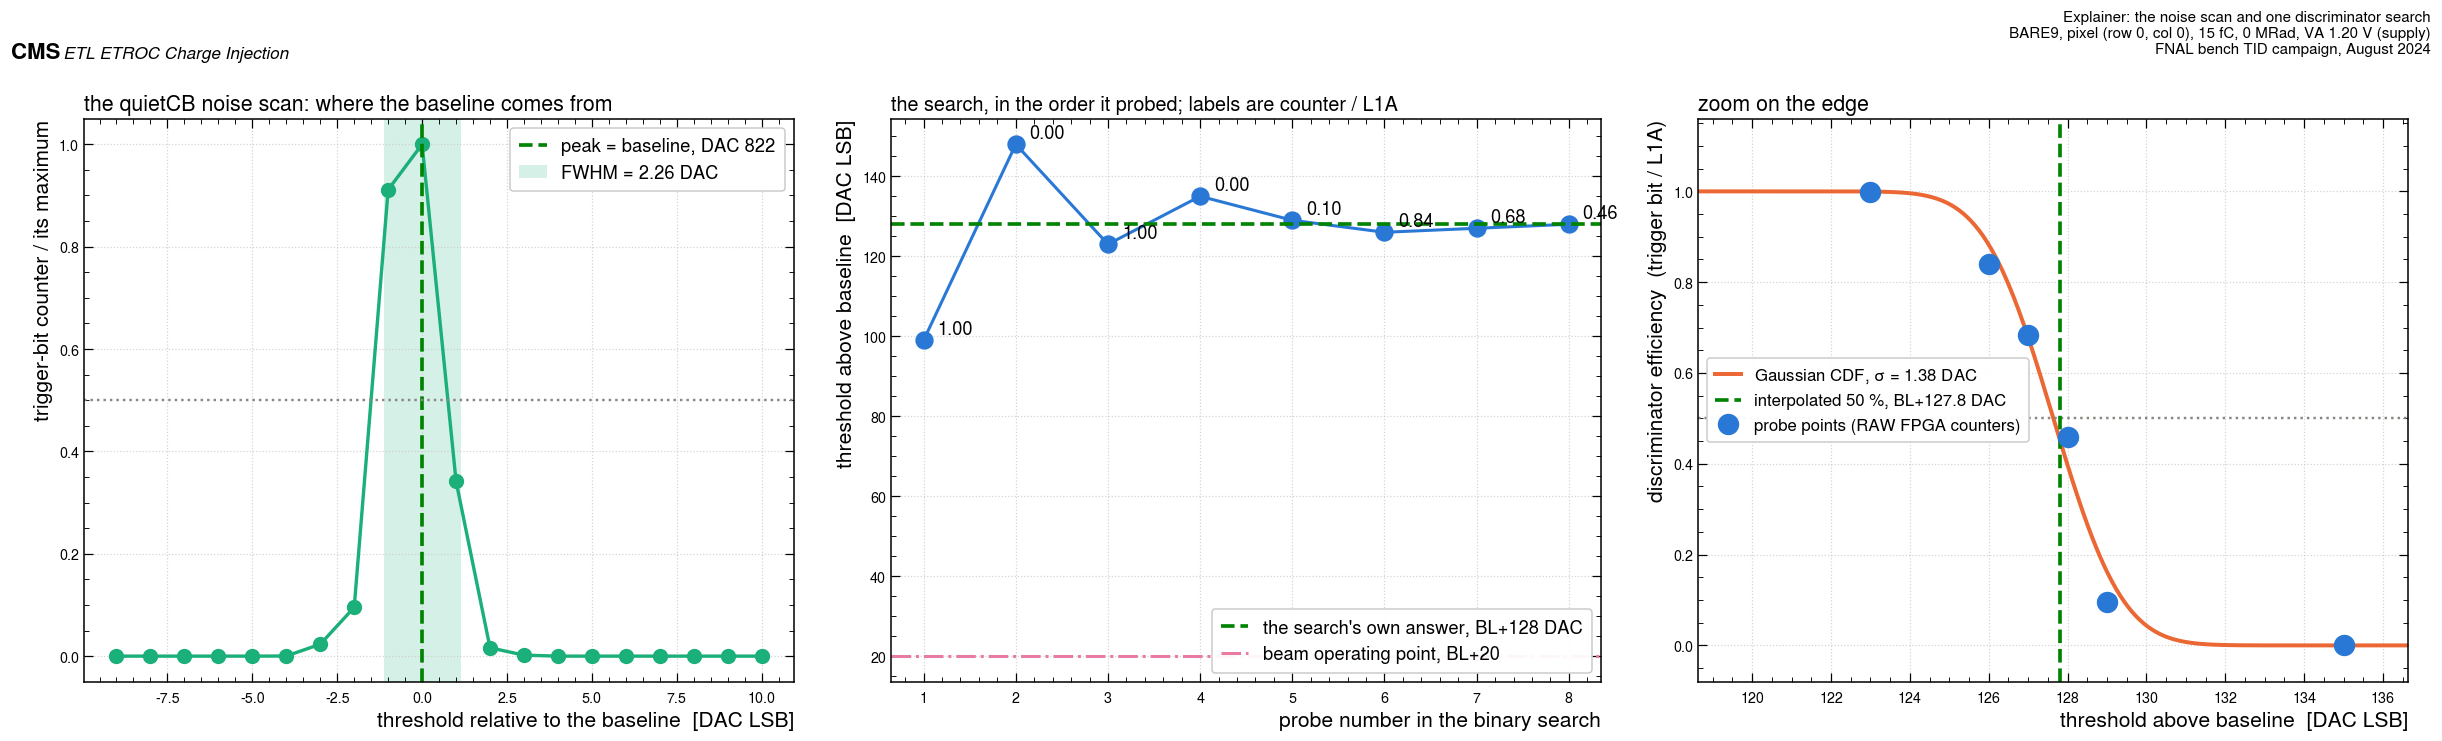

In [10]:
# --- Explainer 1: one discriminator binary search, and the noise scan that sets its baseline.
CFG0 = COND[(COND.chip == "ET2p03_BARE9") & (COND.dose == 0) & (COND.va == 1.20)].config.iloc[0]
PX, QQ = (0, 0), 15.0
ex = TOF[(TOF.config == CFG0) & (TOF.row == PX[0]) & (TOF.col == PX[1]) & (TOF.charge_fC == QQ)].iloc[0]
d_ex, v_ex = Q.parse_trace(ex.search_trace)
f_ex = v_ex / ex.l1a_max
bl_ex = float(BL[(BL.config == CFG0) & (BL.row == PX[0]) & (BL.col == PX[1])].BL.iloc[0])
nx = NOI[(NOI.config == CFG0) & (NOI.row == PX[0]) & (NOI.col == PX[1])].iloc[0]
dn, vn = Q.parse_trace(nx.scan_trace)
to_ex = Q.turnoff_50pct(d_ex, np.clip(f_ex, 0, 1))

fig, axs = plt.subplots(1, 3, figsize=(22, 6.2))
ax = axs[0]
ax.plot(dn - bl_ex, vn / vn.max(), "o-", ms=9, lw=2.2, color=Q.C_AQUA)
pk, _, fw, _ = Q.noise_peak(nx.scan_trace)
ax.axvline(pk - bl_ex, color=Q.C_GREEN, ls="--", lw=2.4, label=f"peak = baseline, DAC {pk:.0f}")
ax.axhline(0.5, color=Q.GREY, ls=":", lw=1.6)
ax.axvspan(pk - bl_ex - fw / 2, pk - bl_ex + fw / 2, color=Q.C_AQUA, alpha=0.18, lw=0,
           label=f"FWHM = {fw:.2f} DAC")
ax.set_xlabel("threshold relative to the baseline  [DAC LSB]")
ax.set_ylabel("trigger-bit counter / its maximum")
ax.legend(fontsize=12, loc="upper right")
ax.set_title("the quietCB noise scan: where the baseline comes from", loc="left", fontsize=14)

ax = axs[1]
ax.plot(np.arange(1, len(ex.search_trace.split(";")) + 1),
        [float(t.split(":")[0]) - bl_ex for t in ex.search_trace.split(";")],
        "o-", ms=11, lw=2.0, color=Q.C_BLUE)
for i, t in enumerate(ex.search_trace.split(";"), start=1):
    dd, vv = t.split(":")
    ax.annotate(f"{float(vv) / ex.l1a_max:.2f}", (i, float(dd) - bl_ex),
                textcoords="offset points", xytext=(9, 4), fontsize=12)
ax.axhline(ex.turnoff_dac - bl_ex, color=Q.C_GREEN, ls="--", lw=2.4,
           label=f"the search's own answer, BL+{ex.turnoff_dac - bl_ex:.0f} DAC")
ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2.0, label="beam operating point, BL+20")
ax.set_xlabel("probe number in the binary search")
ax.set_ylabel("threshold above baseline  [DAC LSB]")
ax.legend(fontsize=12, loc="lower right")
ax.set_title("the search, in the order it probed; labels are counter / L1A", loc="left", fontsize=13)

ax = axs[2]
ax.errorbar(d_ex - bl_ex, np.clip(f_ex, 0, 1),
            yerr=np.sqrt(np.clip(f_ex, 0, 1) * (1 - np.clip(f_ex, 0, 1)) / ex.l1a_max),
            fmt="o", ms=13, color=Q.C_BLUE, zorder=5, label="probe points (RAW FPGA counters)")
cv_ex, _ = Q.curves_from(pd.DataFrame(dict(row=PX[0], col=PX[1], charge_fC=QQ, dac=d_ex,
                                           frac_c=np.clip(f_ex, 0, 1))),
                         keys=("row", "col", "charge_fC"))
sig_ex, _, mu_ex, _ = Q.scurve_sigma(cv_ex, boot=0)
xx = np.linspace(mu_ex[0] - 10, mu_ex[0] + 10, 600)
ax.plot(xx - bl_ex, Q.gauss_cdf(xx, mu_ex[0], sig_ex), "-", color=Q.C_ORANGE, lw=2.6,
        label=f"Gaussian CDF, $\\sigma$ = {sig_ex:.2f} DAC")
ax.axhline(0.5, color=Q.GREY, ls=":", lw=1.6)
ax.axvline(to_ex - bl_ex, color=Q.C_GREEN, ls="--", lw=2.4,
           label=f"interpolated 50 %, BL+{to_ex - bl_ex:.1f} DAC")
ax.set_xlim(mu_ex[0] - 9 - bl_ex, mu_ex[0] + 9 - bl_ex)
ax.set_ylim(-0.08, 1.16)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("discriminator efficiency  (trigger bit / L1A)")
ax.legend(loc="center left", fontsize=11)
ax.set_title("zoom on the edge", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Explainer: the noise scan and one discriminator search",
             tag=f"BARE9, pixel (row {PX[0]}, col {PX[1]}), {QQ:.0f} fC, 0 MRad, VA 1.20 V (supply)",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_expl1_scurve")
plt.show()

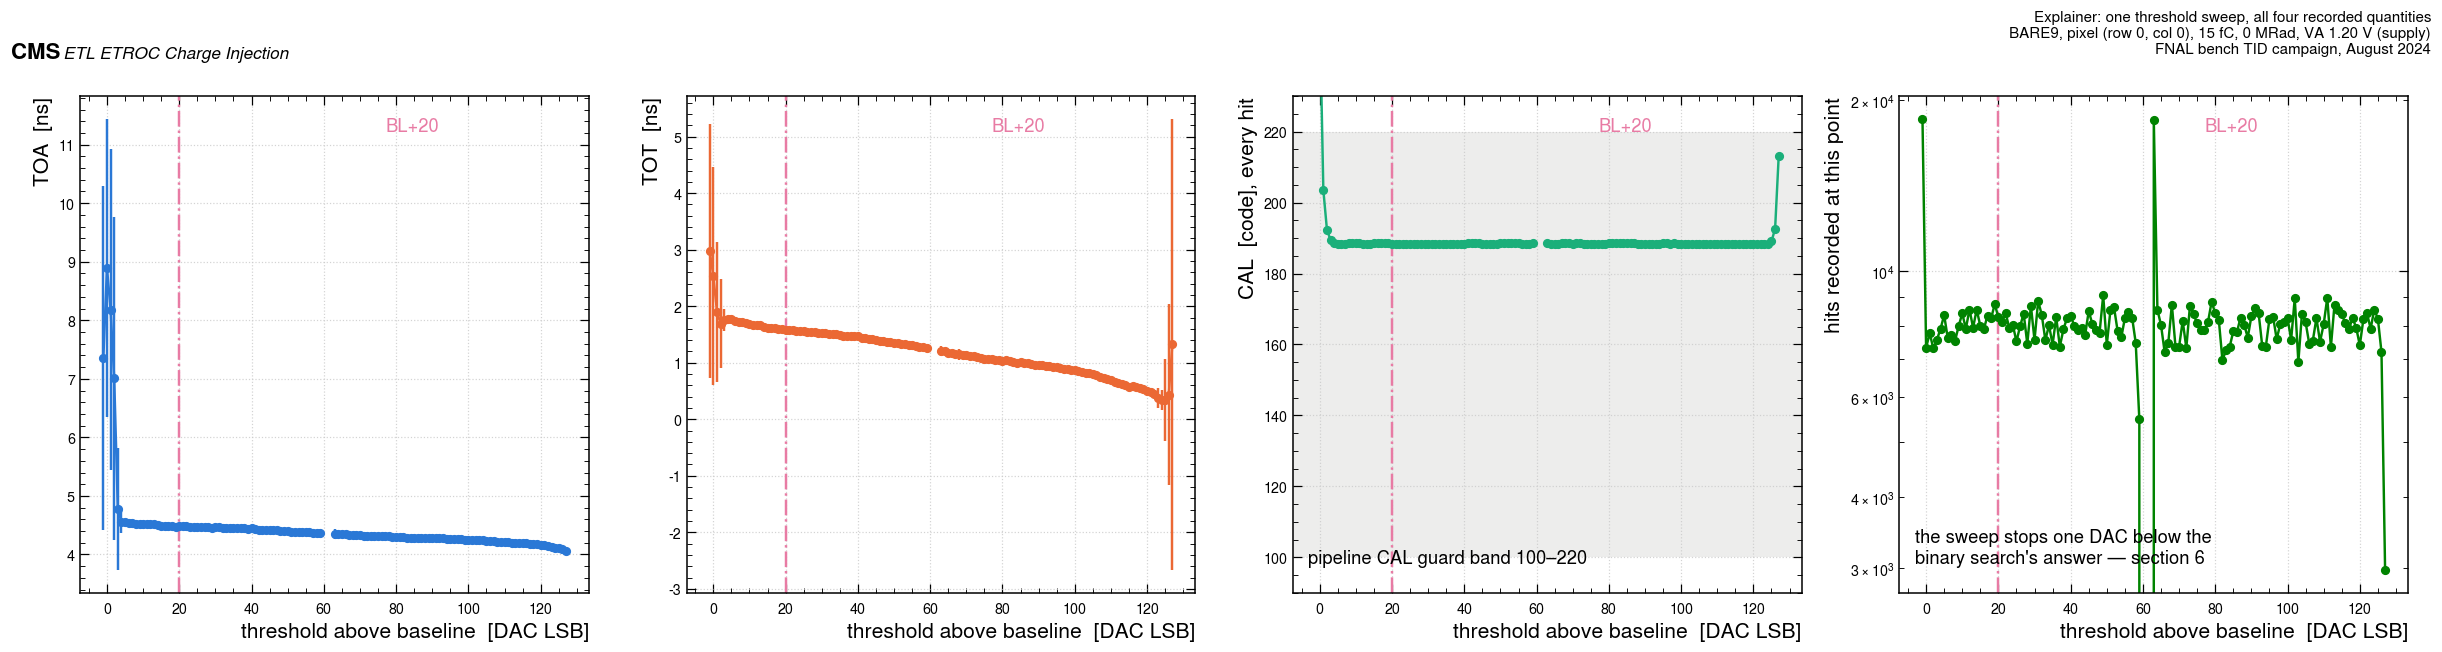

the first few points sit at or below the baseline, where the noise dominates.
Raw moments (every hit) beside the CAL-windowed ones the analysis uses:

 offset  n_hits_raw  n_hits  frac_rejected  cal_mean_raw  cal_std_raw  cal_mode  cal_std  toa_std_raw  toa_std
   -1.0       18555    6922          0.627       389.899      280.492     188.0    0.475      180.118  176.574
    0.0        7329    5472          0.253       254.649      188.415     188.0    0.418      161.192  153.089
    1.0        7776    7274          0.065       203.544       98.011     188.0    0.450      169.330  164.912
    2.0        7307    7153          0.021       192.337       56.873     188.0    0.462      168.832  165.923
    3.0        7570    7547          0.003       189.475       24.115     188.0    0.501       67.836   62.699
    4.0        7919    7915          0.001       188.638       11.754     188.0    0.492       16.748   12.168


In [11]:
# --- Explainer 2: what one threshold sweep records — TOA, TOT, CAL and the hit count.
d = M[(M.config == CFG0) & (M.row == PX[0]) & (M.col == PX[1]) & (M.charge_fC == QQ)].sort_values("offset")
fig, axs = plt.subplots(1, 4, figsize=(22, 5.4))
for ax, (col, lab, cc) in zip(axs, [("toa_ns", "TOA  [ns]", Q.C_BLUE),
                                    ("tot_ns", "TOT  [ns]", Q.C_ORANGE),
                                    ("cal_mean_raw", "CAL  [code], every hit", Q.C_AQUA),
                                    ("n_hits_raw", "hits recorded at this point", Q.C_GREEN)]):
    yerr = d.jitter_ps / 1e3 if col == "toa_ns" else (d.tot_std_ns if col == "tot_ns" else None)
    ax.errorbar(d.offset, d[col], yerr=yerr, fmt="o-", ms=5, lw=1.6, color=cc)
    ax.set_xlabel("threshold above baseline  [DAC LSB]")
    ax.set_ylabel(lab)
    ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.6)
    ax.text(0.60, 0.93, "BL+20", transform=ax.transAxes, color=Q.C_MAG, fontsize=12)
axs[2].axhspan(*Q.CAL_GUARD, color=Q.GREY, alpha=0.15, lw=0)
axs[2].set_ylim(min(Q.CAL_GUARD) - 10, max(Q.CAL_GUARD) + 10)
axs[2].text(0.03, 0.06, "pipeline CAL guard band 100–220", transform=axs[2].transAxes, fontsize=12)
axs[3].set_yscale("log")
axs[3].text(0.03, 0.06, "the sweep stops one DAC below the\nbinary search's answer — section 6",
            transform=axs[3].transAxes, fontsize=12)
fig.tight_layout()
Q.fig_header(fig, "Explainer: one threshold sweep, all four recorded quantities",
             tag=f"BARE9, pixel (row {PX[0]}, col {PX[1]}), {QQ:.0f} fC, 0 MRad, VA 1.20 V (supply)",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_expl2_sweep_quantities")
plt.show()
print("the first few points sit at or below the baseline, where the noise dominates.")
print("Raw moments (every hit) beside the CAL-windowed ones the analysis uses:\n")
print(d[["offset", "n_hits_raw", "n_hits", "frac_rejected", "cal_mean_raw", "cal_std_raw",
         "cal_mode", "cal_std", "toa_std_raw", "toa_std"]].head(6).round(3).to_string(index=False))

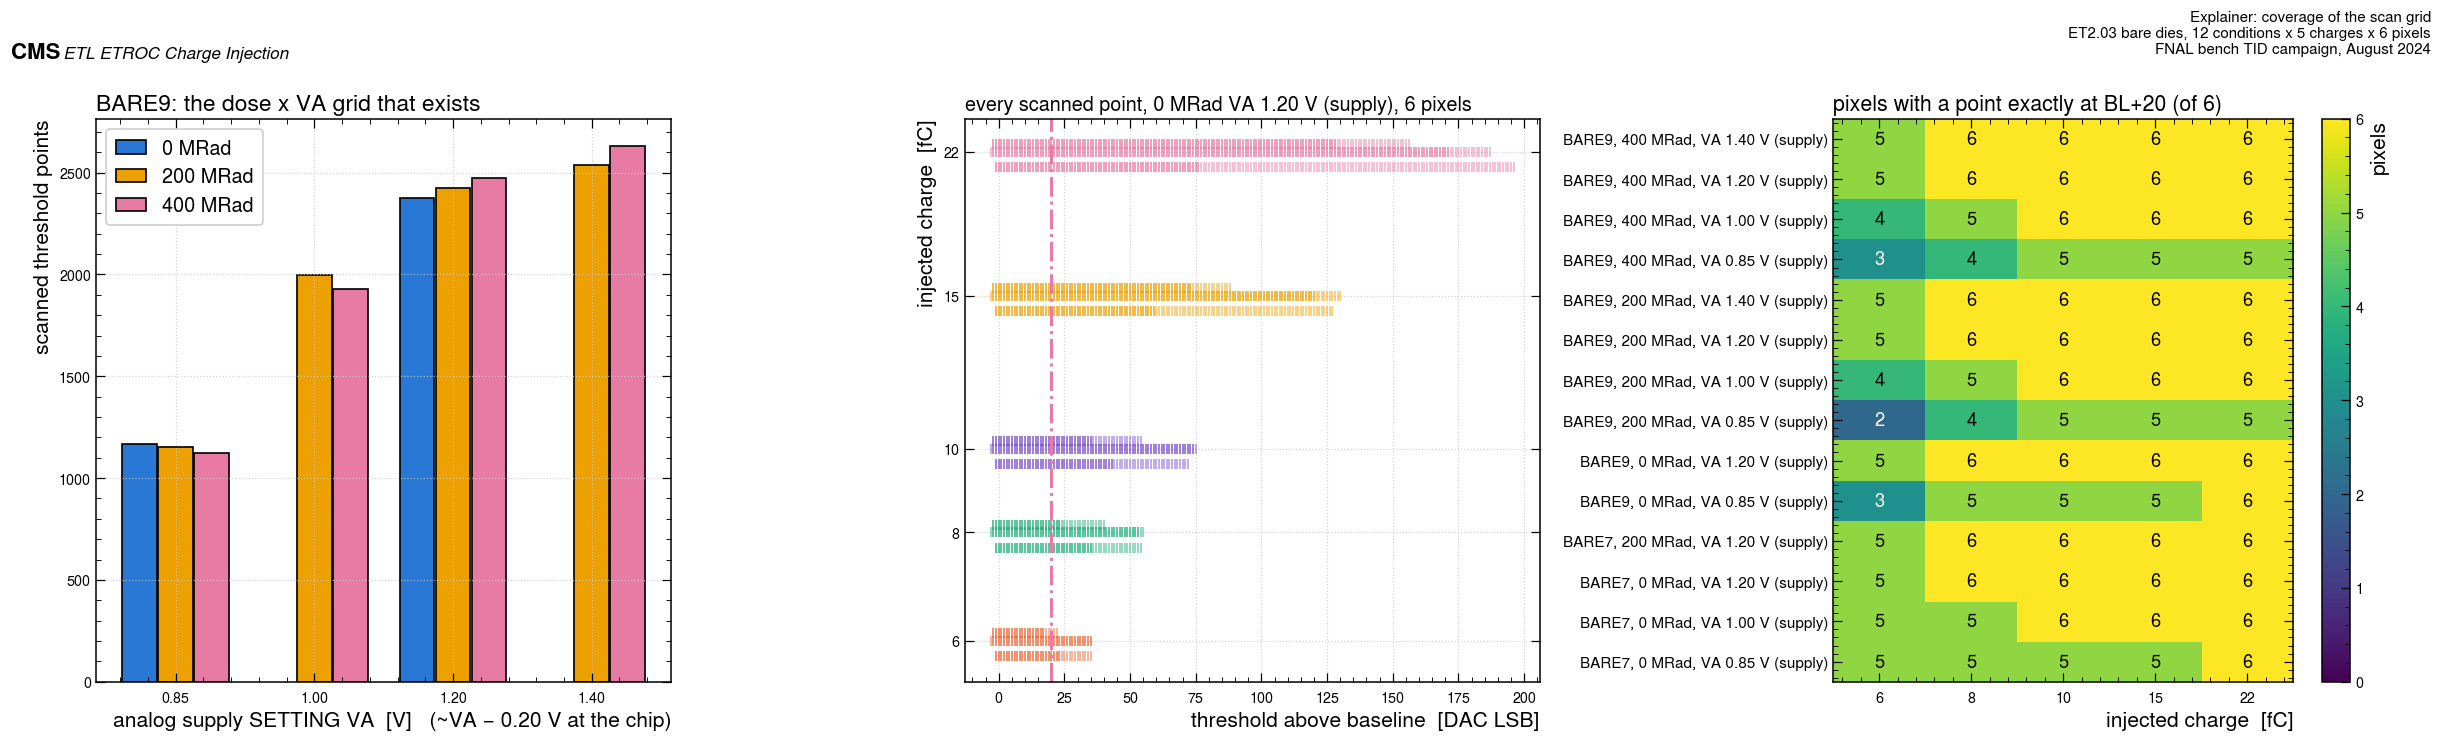

charge_fC                            6.0   8.0   10.0  15.0  22.0
label                                                            
BARE7, 0 MRad, VA 0.85 V (supply)       5     5     5     5     6
BARE7, 0 MRad, VA 1.00 V (supply)       5     5     6     6     6
BARE7, 0 MRad, VA 1.20 V (supply)       5     6     6     6     6
BARE7, 200 MRad, VA 1.20 V (supply)     5     6     6     6     6
BARE9, 0 MRad, VA 0.85 V (supply)       3     5     5     5     6
BARE9, 0 MRad, VA 1.20 V (supply)       5     6     6     6     6
BARE9, 200 MRad, VA 0.85 V (supply)     2     4     5     5     5
BARE9, 200 MRad, VA 1.00 V (supply)     4     5     6     6     6
BARE9, 200 MRad, VA 1.20 V (supply)     5     6     6     6     6
BARE9, 200 MRad, VA 1.40 V (supply)     5     6     6     6     6
BARE9, 400 MRad, VA 0.85 V (supply)     3     4     5     5     5
BARE9, 400 MRad, VA 1.00 V (supply)     4     5     6     6     6
BARE9, 400 MRad, VA 1.20 V (supply)     5     6     6     6     6
BARE9, 400

In [12]:
# --- Explainer 3: coverage of the scan grid — dose x VA x charge x pixel.
B9 = COND[(COND.chip == "ET2p03_BARE9") & COND.points.notna() & COND.dose.notna()]
fig, axs = plt.subplots(1, 3, figsize=(22, 6.2))
ax = axs[0]
cov = (M.merge(COND[["config", "dose", "va"]], on="config")
       .groupby(["chip", "dose", "va", "charge_fC"]).size().rename("n").reset_index())
cov = cov[cov.chip == "ET2p03_BARE9"].dropna(subset=["dose"])
xs = sorted(cov.va.unique())
for j, dose in enumerate(sorted(cov.dose.unique())):
    s = cov[cov.dose == dose].groupby("va").n.sum().reindex(xs)
    ax.bar(np.arange(len(xs)) + (j - 1) * 0.26, s.values, width=0.25,
           color=[Q.C_BLUE, Q.C_YELLOW, Q.C_MAG][j], edgecolor="black", lw=1.1,
           label=f"{int(dose)} MRad")
ax.set_xticks(range(len(xs)))
ax.set_xticklabels([f"{v:.2f}" for v in xs])
ax.set_xlabel("analog supply SETTING VA  [V]   (~VA − 0.20 V at the chip)")
ax.set_ylabel("scanned threshold points")
ax.legend(fontsize=13)
ax.set_title("BARE9: the dose x VA grid that exists", loc="left", fontsize=15)

ax = axs[1]
CFGS_VA12 = COND[(COND.va == 1.20) & COND.points.notna()].config.tolist()
mm = M[M.config == CFG0]
for ch in Q.ET2P03_CHARGES:
    sub = mm[mm.charge_fC == ch]
    for (r, c), gg in sub.groupby(["row", "col"]):
        ax.plot(gg.offset, np.full(len(gg), ch) * (1 + 0.02 * (int(r) % 5 - 2)),
                "|", ms=6, color=Q.CCOL[ch], alpha=0.6)
Q.charge_axis(ax, axis="y", charges=Q.ET2P03_CHARGES)
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("injected charge  [fC]")
ax.set_title("every scanned point, 0 MRad VA 1.20 V (supply), 6 pixels", loc="left", fontsize=13)

ax = axs[2]
n20 = (M[M.offset == Q.OP_OFFSET].merge(COND[["config", "label"]], on="config")
       .groupby(["label", "charge_fC"]).size().unstack()
       .reindex(columns=[float(c) for c in Q.ET2P03_CHARGES]).fillna(0).astype(int))
im = ax.imshow(n20.values, aspect="auto", cmap="viridis", origin="lower", vmin=0, vmax=6)
ax.set_xticks(range(len(Q.ET2P03_CHARGES)))
ax.set_xticklabels([str(int(c)) for c in n20.columns])
ax.set_yticks(range(len(n20.index)))
ax.set_yticklabels(n20.index, fontsize=10)
for i in range(n20.shape[0]):
    for j in range(n20.shape[1]):
        ax.text(j, i, str(n20.values[i, j]), ha="center", va="center", fontsize=12,
                color="white" if n20.values[i, j] < 4 else "black")
ax.grid(False)
ax.set_xlabel("injected charge  [fC]")
ax.set_title("pixels with a point exactly at BL+20 (of 6)", loc="left", fontsize=14)
plt.colorbar(im, ax=ax, label="pixels")
fig.tight_layout()
Q.fig_header(fig, "Explainer: coverage of the scan grid",
             tag="ET2.03 bare dies, 12 conditions x 5 charges x 6 pixels", scale=0.62,
             campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_expl3_scan_grid")
plt.show()
print(n20.to_string())

### 4.4 Why the moments are CAL-windowed — a decode pathology, drawn

One TOA code is `3.125 ns / CAL`, so a hit whose CAL is wrong has a wrong TOA no matter how well
the TDC performed. On this campaign a small fraction of hits carry a grossly wrong CAL, and they
are **not** spread evenly: on each pixel they occupy a contiguous block of four to eight
threshold DAC values at a **fixed absolute DAC**, identical for every injected charge in that
pixel — which is the signature of a decode/acquisition artefact tied to the DAQ's inner loop
(the sweep steps charge at fixed threshold), not of anything the front end did with charge.

The block is invisible in the mean and glaring in the spread: `cal_mean` moves by a few codes
while `cal_std` jumps from below half a code to tens of codes. Notebook 02 already carries this
flag on the hybrid data as `cal_rms_gt2`; notebook 03 now carries it too, and the per-hit CAL
window removes the affected hits rather than the affected points, so no threshold point is lost.

**The window does not remove everything.** A second, smaller artefact class survives it: points
whose CAL is clean *after* windowing and whose TOA is still corrupt. Pixel (3,0) at 22 fC,
0 MRad, VA 1.20 V is the clearest example — at DAC 880–883 the window rejects only 0.5 % of the
hits and leaves `cal_std` at 0.38–0.50 codes, yet the windowed TOA spread is 10.9–16.5 codes,
i.e. 180–273 ps. Those are the isolated spikes still visible in figure 4. They are **flagged,
not cut** (`toa_rms_gt3`, `toa_spike_50ps`), counted in the cell below, and marked on figure 4.
The cell also checks, rather than asserts, whether enough pixels are flagged together to move
the six-pixel median that figure 2 and every BL+20 number are built on.

**The criterion, stated once:** a hit is kept if `|CAL − cal_mode| ≤ 3` codes, where `cal_mode`
is the modal CAL of that pixel at that scanned point. It is the repository test-beam pipeline's
own per-hit window (`core/path_finder.py`, `core/extract_events_by_path.py`); the reduction
applies it and emits both sets of moments, so the raw ones remain available and the effect of
the window is a before/after comparison rather than an assertion. `Q.CAL_GUARD = (100, 220)` is
a different object — an absolute sanity band on CAL — and is **not** what is applied here.

money-plot points at BARE9, 0 MRad, VA 1.20 V (supply): 2376
  all offsets   cal_std_raw > 2 codes:  393 of 2376  ( 16.5 %)
  offset >= 10  cal_std_raw > 2 codes:  191 of 2021  (  9.5 %)

the charge-independent block, per pixel, at BARE9, 0 MRad, VA 1.20 V (supply)
(longest run of consecutive DAC above the baseline flagged at 3+ charges)

  pixel ( 0, 0): DAC 885-885 (1 wide) = offset +63 to +63, flagged at 3 charges;  cal_std  27.7 -> 0.46,  TOA std  33.3 ->  2.1 codes,  0.51 % of hits dropped
  pixel ( 0,14): DAC 861-863 (3 wide) = offset +34 to +36, flagged at 4 charges;  cal_std  28.7 -> 0.42,  TOA std  27.8 ->  1.2 codes,  0.35 % of hits dropped
  pixel ( 3, 0): DAC 879-879 (1 wide) = offset +54 to +54, flagged at 3 charges;  cal_std  33.9 -> 0.40,  TOA std  28.9 ->  0.9 codes,  0.54 % of hits dropped
  pixel ( 3,14): DAC 839-840 (2 wide) = offset +5 to +6, flagged at 5 charges;  cal_std  22.7 -> 0.47,  TOA std  41.2 -> 30.0 codes,  0.35 % of hits dropped
  pixel (12, 0): DAC 891-

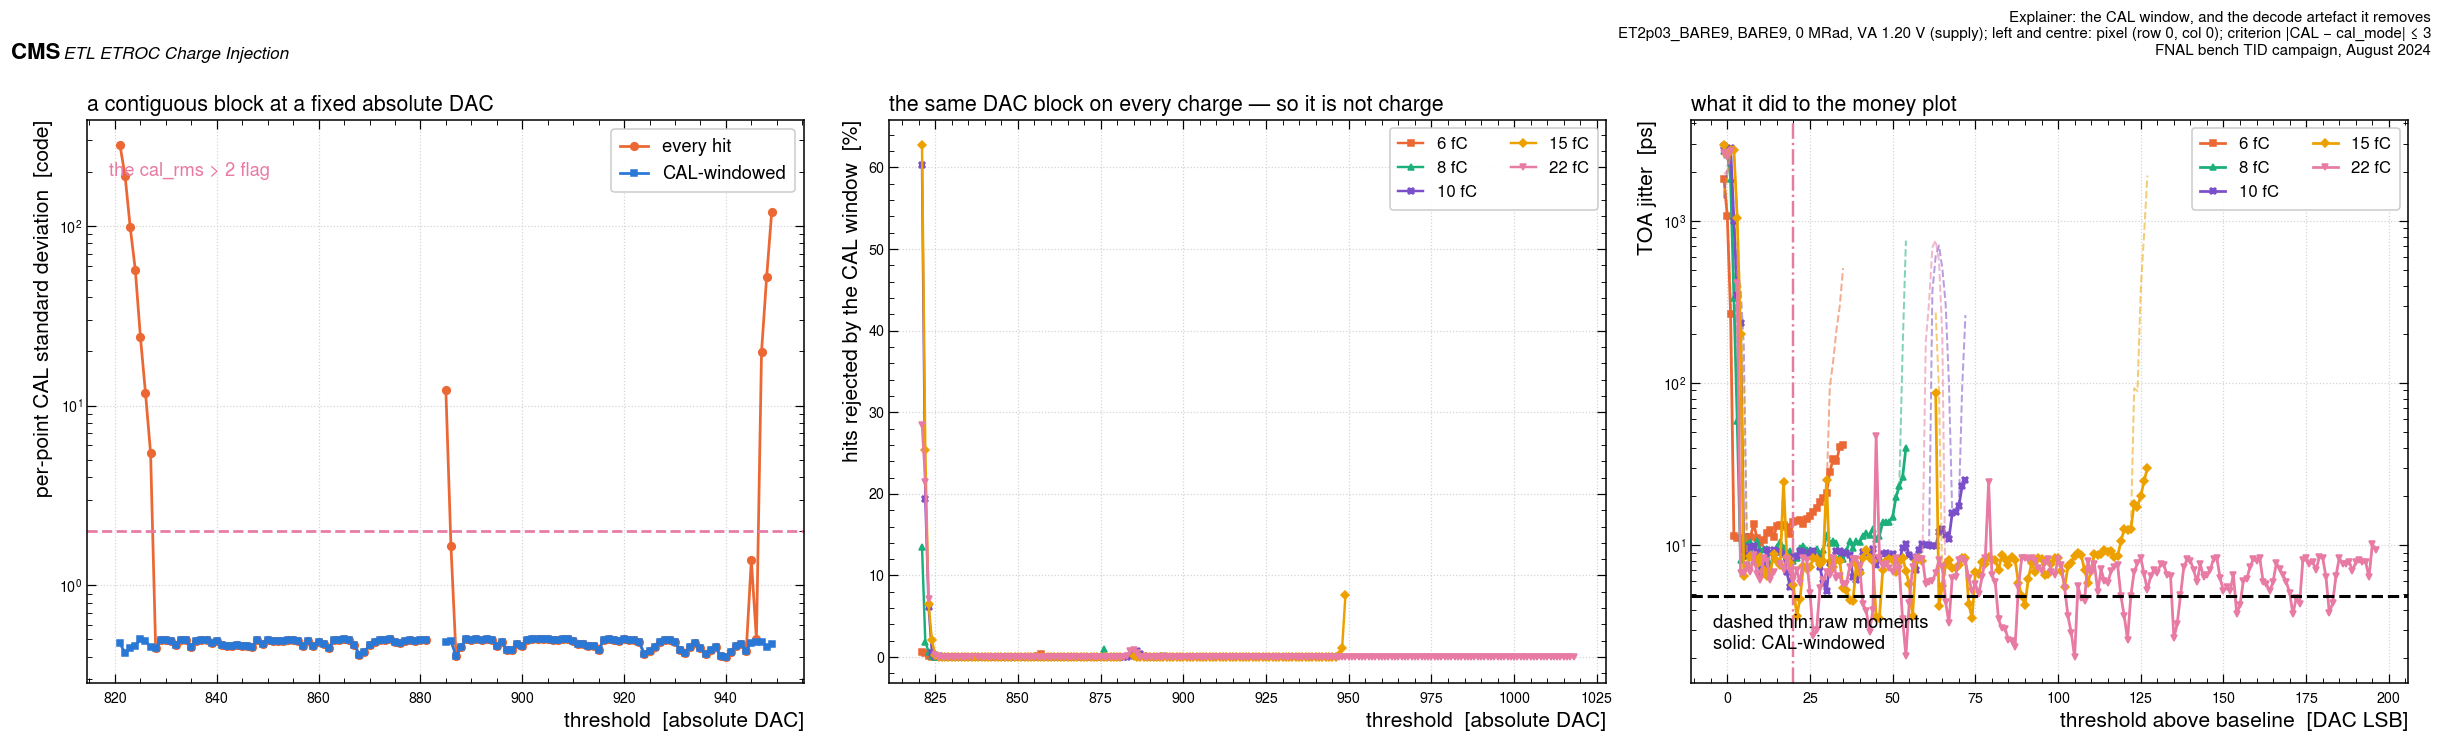


THE RESIDUAL, TOA-ONLY ARTEFACT CLASS (CAL clean after windowing, TOA still corrupt):
  points at offset >= 10 with jitter > 50 ps :  585 of 24882  (2.35 %)
  points at BL+20 with jitter > 50 ps        :   13 of   378  (3.4 %)
  points at BL+20 with windowed TOA std > 3 codes: 11 of 378
  flagged pixels per (condition, charge, offset) group, offset >= 10: {0: 5360, 1: 411, 2: 71, 3: 9, 5: 1}
  groups where enough pixels are flagged to move the 6-pixel median: 64 of 5852 (1.09 %)
  So they are isolated points rather than blocks, and in 98.9 % of groups the median over
  six pixels is taken over a majority of unflagged pixels. Figure 2 and the BL+20 numbers
  are medians and means over six pixels and are safe at that level; figure 4 shows single
  pixels and marks every flagged point.

the CAL window, condition by condition:

                              label  points  flagged  flagged_pct  hits_raw  hits_kept  hits_rejected_pct  median_frac_rejected
  BARE7, 0 MRad, VA 0.85 V (supply)

In [13]:
MP = M[M.scan_family == "money_plot"]
D0X = MP[MP.config == CFG0]
REF_LABEL = COND[COND.config == CFG0].label.iloc[0]   # `REF` itself is not built until section 6
print("money-plot points at %s: %d" % (REF_LABEL, len(D0X)))
for lab, sub in [("all offsets", D0X), ("offset >= 10", D0X[D0X.offset >= 10])]:
    print("  %-12s  cal_std_raw > 2 codes: %4d of %4d  (%5.1f %%)"
          % (lab, int(sub.cal_rms_gt2.sum()), len(sub), 100 * sub.cal_rms_gt2.mean()))
def charge_independent_block(g, min_charges=3):
    """The longest run of consecutive DAC values flagged at three or more injected charges,
    taken **above the baseline** (offset >= BL_OFFSET, where the sweep starts). That is the
    charge-independent core of the artefact, and the same definition DECODE_README.md tabulates.
    Two other things also raise cal_std and are deliberately excluded: points below the baseline,
    where noise fires the discriminator, and points above a pixel's own turn-off, where almost no
    hits are left.
    """
    g = g[g.offset >= Q.BL_OFFSET]
    per = g.groupby("dac").cal_rms_gt2.sum()
    dacs = sorted(per[per >= min_charges].index)
    if not dacs:
        return g, []
    runs, cur = [], [dacs[0]]
    for x in dacs[1:]:
        if x == cur[-1] + 1:
            cur.append(x)
        else:
            runs.append(cur); cur = [x]
    runs.append(cur)
    return g, max(runs, key=len)


print("\nthe charge-independent block, per pixel, at %s" % REF_LABEL)
print("(longest run of consecutive DAC above the baseline flagged at 3+ charges)\n")
for (r, c) in Q.ET2P03_PIXELS:
    g, blk = charge_independent_block(D0X[(D0X.row == r) & (D0X.col == c)])
    if not blk:
        print("  pixel (%2d,%2d): no charge-independent block" % (r, c))
        continue
    sel = g[g.dac.isin(blk)]
    bl = float(g.BL.iloc[0])
    print("  pixel (%2d,%2d): DAC %d-%d (%d wide) = offset %+d to %+d, flagged at %d charges;  "
          "cal_std %5.1f -> %.2f,  TOA std %5.1f -> %4.1f codes,  %.2f %% of hits dropped"
          % (r, c, int(min(blk)), int(max(blk)), len(blk), int(min(blk) - bl), int(max(blk) - bl),
             int(sel[sel.cal_rms_gt2].charge_fC.nunique()),
             sel.cal_std_raw.mean(), sel.cal_std.mean(),
             sel.toa_std_raw.mean(), sel.toa_std.mean(), 100 * sel.frac_rejected.mean()))
print("\nThe blocks land at different absolute DAC on different pixels, so on the median over six")
print("pixels they smear into one broad, charge-independent bump in the middle of the money plot")
print("that no front-end effect could produce.")

PXB, QB = (0, 0), 15.0
dd = D0X[(D0X.row == PXB[0]) & (D0X.col == PXB[1]) & (D0X.charge_fC == QB)].sort_values("dac")
fig, axs = plt.subplots(1, 3, figsize=(22, 6.2))
ax = axs[0]
ax.plot(dd.dac, dd.cal_std_raw, "-o", ms=5, lw=1.8, color=Q.C_ORANGE, label="every hit")
ax.plot(dd.dac, dd.cal_std, "-s", ms=4, lw=1.8, color=Q.C_BLUE, label="CAL-windowed")
ax.axhline(2.0, color=Q.C_MAG, ls="--", lw=1.8)
ax.text(0.03, 0.90, "the cal_rms > 2 flag", transform=ax.transAxes, color=Q.C_MAG, fontsize=12)
ax.set_yscale("log")
ax.set_xlabel("threshold  [absolute DAC]")
ax.set_ylabel("per-point CAL standard deviation  [code]")
ax.legend(fontsize=12)
ax.set_title("a contiguous block at a fixed absolute DAC", loc="left", fontsize=14)

ax = axs[1]
for ch in Q.ET2P03_CHARGES:
    sub = D0X[(D0X.row == PXB[0]) & (D0X.col == PXB[1]) & (D0X.charge_fC == ch)].sort_values("dac")
    ax.plot(sub.dac, 100 * sub.frac_rejected, "-", marker=Q.CMK[ch], ms=4, lw=1.6,
            color=Q.CCOL[ch], label=f"{ch:.0f} fC")
ax.set_xlabel("threshold  [absolute DAC]")
ax.set_ylabel("hits rejected by the CAL window  [%]")
ax.legend(fontsize=11, ncol=2)
ax.set_title("the same DAC block on every charge — so it is not charge", loc="left", fontsize=14)

ax = axs[2]
for ch in Q.ET2P03_CHARGES:
    sub = D0X[(D0X.row == PXB[0]) & (D0X.col == PXB[1]) & (D0X.charge_fC == ch)].sort_values("offset")
    ax.plot(sub.offset, sub.jitter_ps_raw, "--", lw=1.3, color=Q.CCOL[ch], alpha=0.55)
    ax.plot(sub.offset, sub.jitter_ps, "-", marker=Q.CMK[ch], ms=4, lw=1.8, color=Q.CCOL[ch],
            label=f"{ch:.0f} fC")
_, fl_b = Q.quantisation_floor_ps(D0X.cal_mean.median())
ax.axhline(fl_b, color="black", ls="--", lw=2.0)
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.6)
ax.set_yscale("log")
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOA jitter  [ps]")
ax.text(0.03, 0.06, "dashed thin: raw moments\nsolid: CAL-windowed", transform=ax.transAxes,
        fontsize=12)
ax.legend(fontsize=11, ncol=2)
ax.set_title("what it did to the money plot", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Explainer: the CAL window, and the decode artefact it removes",
             tag=f"ET2p03_BARE9, {REF_LABEL}; left and centre: pixel "
                 f"(row {PXB[0]}, col {PXB[1]}); criterion |CAL − cal_mode| ≤ {Q.CAL_WINDOW}",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_expl4_cal_window")
plt.show()

# --- the TOA-only class that the CAL window does not catch
o10 = MP[MP.offset >= 10]
b20 = MP[MP.offset == Q.OP_OFFSET]
print("\nTHE RESIDUAL, TOA-ONLY ARTEFACT CLASS (CAL clean after windowing, TOA still corrupt):")
print("  points at offset >= 10 with jitter > 50 ps : %4d of %5d  (%.2f %%)"
      % (int(o10.toa_spike_50ps.sum()), len(o10), 100 * o10.toa_spike_50ps.mean()))
print("  points at BL+20 with jitter > 50 ps        : %4d of %5d  (%.1f %%)"
      % (int(b20.toa_spike_50ps.sum()), len(b20), 100 * b20.toa_spike_50ps.mean()))
print("  points at BL+20 with windowed TOA std > 3 codes: %d of %d"
      % (int(b20.toa_rms_gt3.sum()), len(b20)))
# Is the pooled median actually robust to them? Count how many of the six pixels are flagged
# together in the same (condition, charge, offset) group -- the group figure 2 takes a median of.
grp = o10.groupby(["config", "charge_fC", "offset"]).toa_spike_50ps.agg(["sum", "size"])
vc = grp["sum"].value_counts().sort_index()
risk = int(((grp["sum"] * 2 > grp["size"]) | ((grp["sum"] >= 3) & (grp["size"] >= 5))).sum())
print("  flagged pixels per (condition, charge, offset) group, offset >= 10: %s"
      % {int(k): int(v) for k, v in vc.items()})
print("  groups where enough pixels are flagged to move the 6-pixel median: %d of %d (%.2f %%)"
      % (risk, len(grp), 100 * risk / len(grp)))
print("  So they are isolated points rather than blocks, and in %.1f %% of groups the median over"
      % (100 * (1 - risk / len(grp))))
print("  six pixels is taken over a majority of unflagged pixels. Figure 2 and the BL+20 numbers")
print("  are medians and means over six pixels and are safe at that level; figure 4 shows single")
print("  pixels and marks every flagged point.")
RESULTS["toa_spike_groups_at_risk"] = risk
RESULTS["toa_spike_groups_total"] = int(len(grp))
RESULTS["toa_spike_50ps_at_off10"] = int(o10.toa_spike_50ps.sum())
RESULTS["toa_spike_50ps_at_off10_of"] = int(len(o10))
RESULTS["toa_spike_50ps_at_off20"] = int(b20.toa_spike_50ps.sum())
RESULTS["toa_spike_50ps_at_off20_of"] = int(len(b20))

CALQ = (MP.groupby(["config"])
        .agg(points=("dac", "size"), flagged=("cal_rms_gt2", "sum"),
             hits_raw=("n_hits_raw", "sum"), hits_kept=("n_hits", "sum"),
             median_frac_rejected=("frac_rejected", "median")).reset_index()
        .merge(COND[["config", "label"]], on="config"))
CALQ["flagged_pct"] = 100 * CALQ.flagged / CALQ.points
CALQ["hits_rejected_pct"] = 100 * (1 - CALQ.hits_kept / CALQ.hits_raw)
CALQ = CALQ[["label", "points", "flagged", "flagged_pct", "hits_raw", "hits_kept",
             "hits_rejected_pct", "median_frac_rejected"]].sort_values("label")
CALQ.to_csv(Q.OUTDIR / "et2p03_cal_window_quality.csv", index=False)
print("\nthe CAL window, condition by condition:\n")
print(CALQ.round(4).to_string(index=False))
RESULTS["cal_window_codes"] = int(Q.CAL_WINDOW)
RESULTS["cal_window_hits_rejected_pct"] = float(100 * (1 - MP.n_hits.sum() / MP.n_hits_raw.sum()))
RESULTS["cal_rms_gt2_points_pct"] = float(100 * MP.cal_rms_gt2.mean())

## 5. The turn-off, and the one place this campaign forces a different path

Notebook 01 takes the turn-off from the binary search's own probe points, by interpolating the
trigger-bit efficiency to 50 %. The same function is available here — the reduction wrote every
search out in full as `search_trace` — and the cell below applies it. It also brings out
something that has to be dealt with rather than ignored.

**The trigger-bit counter is not a plain efficiency.** On both campaigns it plateaus at either
one or two counts per Level-1 accept, and on ET2.03 the two-count shelf sits immediately above
the baseline, where noise as well as the injected charge is firing the discriminator. Notebook
01's estimator clips the fraction at 1 and interpolates to 0.5, which lands on the **outer**
edge, where the counter finally goes to zero. That is the right feature; the difficulty is that
the ET2.03 searches often converged somewhere else and left that outer edge sampled only
across tens of DAC.

So the cell below computes, per search, the **bracket width** — the gap between the last probe
at or above 50 % and the first below it. Where that bracket is one or two DAC the interpolated
estimator is a real sub-LSB measurement; where it is tens of DAC it is an extrapolation across
a gap and must not be used. The campaign's own definition, `turnoff_dac` (RAW — the DAC on the
last line of `FPGA_Data.dat`, which is what produced the reduction's money-plot table), is
compared against it on the subset where the comparison is meaningful.

In [14]:
PR = Q.et2p03_probes(TOF)


def bracket_width(g):
    d = g.dac.values.astype(float)
    f = g.frac_c.values.astype(float)
    o = np.argsort(d)
    d, f = d[o], f[o]
    a = np.where(f >= 0.5)[0]
    if len(a) == 0:
        return np.nan
    i = a[-1]
    hi = np.where((d > d[i]) & (f < 0.5))[0]
    if len(hi) == 0:
        return np.nan
    return float(d[hi[int(np.argmin(d[hi]))]] - d[i])


# An explicit loop rather than `groupby.apply`, so that the cell behaves identically on the
# pandas 1.5 of the repository's LCG view and on a modern pandas.
BRK = pd.DataFrame([dict(zip(["config", "row", "col", "charge_fC"], k), bracket=bracket_width(g))
                    for k, g in PR.groupby(["config", "row", "col", "charge_fC"])])
TO = Q.turnoff_table(PR, ["config", "row", "col", "charge_fC"]).merge(
    BRK, on=["config", "row", "col", "charge_fC"])
TO = TO.merge(TOF[["config", "row", "col", "charge_fC", "turnoff_dac", "dac_max",
                   "l1a_max", "n_search_steps"]],
              on=["config", "row", "col", "charge_fC"])
TO["delta_estimators"] = TO.trig_turnoff_dac - TO.turnoff_dac
tight = TO.bracket <= 2
print("searches whose 50 %% crossing is bracketed to <= 2 DAC : %d of %d" % (tight.sum(), len(TO)))
print("  interpolated 50 %% minus the campaign's own last-probe DAC, on those:")
print("    mean %+.3f, sd %.3f, median %+.3f, range %+.2f to %+.2f DAC"
      % (TO.delta_estimators[tight].mean(), TO.delta_estimators[tight].std(),
         TO.delta_estimators[tight].median(), TO.delta_estimators[tight].min(),
         TO.delta_estimators[tight].max()))
print("  on the remaining %d the bracket is %.0f DAC on average and the two differ by %+.1f DAC:"
      % ((~tight).sum(), TO.bracket[~tight].mean(), TO.delta_estimators[~tight].mean()))
print("    those are concentrated at low charge:",
      TO[~tight].charge_fC.value_counts().sort_index().to_dict(), "of",
      TO.charge_fC.value_counts().sort_index().to_dict())
print("\nSo: on the well-bracketed half the two definitions are the same number to well under one DAC,")
print("and the campaign's own turn-off is what this notebook carries — it is defined at every")
print("(condition, pixel, charge), it is monotonic in charge, and it is the definition the")
print("reduction's own money-plot table was built with.")

searches whose 50 % crossing is bracketed to <= 2 DAC : 247 of 450
  interpolated 50 %% minus the campaign's own last-probe DAC, on those:
    mean +0.023, sd 0.671, median -0.080, range -0.99 to +2.90 DAC
  on the remaining 203 the bracket is 25 DAC on average and the two differ by +18.1 DAC:
    those are concentrated at low charge: {6.0: 86, 8.0: 66, 10.0: 27, 15.0: 6, 22.0: 18} of {6.0: 90, 8.0: 90, 10.0: 90, 15.0: 90, 22.0: 90}

So: on the well-bracketed half the two definitions are the same number to well under one DAC,
and the campaign's own turn-off is what this notebook carries — it is defined at every
(condition, pixel, charge), it is monotonic in charge, and it is the definition the
reduction's own money-plot table was built with.


**The threshold sweep cannot arbitrate.** In notebook 01 the TDC-readout turn-off — the highest
threshold at which the sweep still wrote hits — is a partly independent second estimator. Here
it is not independent at all: the sweep's upper bound was set to the binary search's answer, so
every sweep ends exactly one DAC below `turnoff_dac` with the hit rate still on its plateau.
The cell below shows that, because it is the reason no second estimator is quoted.

In [15]:
last = (M.groupby(["config", "row", "col", "charge_fC"])
        .agg(sweep_dac_max=("dac", "max"), hits_at_last=("n_hits_raw", "last")).reset_index())
TO = TO.merge(last, on=["config", "row", "col", "charge_fC"], how="left")
TO["sweep_gap"] = TO.turnoff_dac - TO.sweep_dac_max
print("turn-off DAC minus the sweep's own last threshold, over %d (condition, pixel, charge) groups:"
      % TO.sweep_gap.notna().sum())
print(TO.sweep_gap.value_counts().sort_index().to_dict())
print("median hits still recorded at the sweep's last point: %.0f"
      % TO.hits_at_last[TO.sweep_gap == 1].median())
print("\nThe sweep is censored by construction. It measures TOA, TOT and CAL up to the turn-off;")
print("it does not measure where the turn-off is.")

turn-off DAC minus the sweep's own last threshold, over 420 (condition, pixel, charge) groups:
{1.0: 420}
median hits still recorded at the sweep's last point: 6949

The sweep is censored by construction. It measures TOA, TOT and CAL up to the turn-off;
it does not measure where the turn-off is.


In [16]:
TO = TO.merge(BL[["config", "row", "col", "BL", "NW_fwhm"]], on=["config", "row", "col"], how="left")
TO = TO.merge(COND[["config", "label", "chip", "dose", "va", "day", "elapsed_h"]], on="config")
TO["turnoff_offset"] = TO.turnoff_dac - TO.BL
TO["at_dac_ceiling"] = TO.turnoff_dac >= 1018
TO.to_csv(Q.OUTDIR / "et2p03_turnoff_all_conditions.csv", index=False)
print("searches whose turn-off is at or above DAC 1018, i.e. against the 10-bit ceiling: %d of %d"
      % (int(TO.at_dac_ceiling.sum()), len(TO)))
print(TO[TO.at_dac_ceiling].groupby(["label", "charge_fC"]).size().to_string())
print("\nThose points are a lower limit on the turn-off, not a measurement of it. They are kept in")
print("every table (no cuts), and the gain fit below is quoted both with and without them.")

searches whose turn-off is at or above DAC 1018, i.e. against the 10-bit ceiling: 21 of 450
label                                     charge_fC
BARE7, 0 MRad, VA 1.20 V (supply)         22.0         1
BARE7, 200 MRad, VA 1.20 V (supply)       22.0         1
BARE9, 0 MRad, VA 1.20 V (supply)         22.0         3
BARE9, 200 MRad, VA 1.40 V (supply)       15.0         2
                                          22.0         5
BARE9, 400 MRad, VA 1.40 V (supply)       15.0         1
                                          22.0         5
BARE9, dose untagged, VA 1.20 V (supply)  22.0         3

Those points are a lower limit on the turn-off, not a measurement of it. They are kept in
every table (no cuts), and the gain fit below is quoted both with and without them.


In [17]:
piv = (TO[TO.va == 1.20].pivot_table(index="charge_fC", columns="label",
                                     values="turnoff_offset", aggfunc="mean"))
print("turn-off above baseline [DAC], mean over the 6 pixels, at VA 1.20 V (supply)\n")
print(piv.round(1).to_string())
print()
piv2 = (TO[TO.chip == "ET2p03_BARE9"].dropna(subset=["dose"])
        .pivot_table(index="charge_fC", columns=["dose", "va"], values="turnoff_offset", aggfunc="mean"))
print("BARE9, every dose and every rail:\n")
print(piv2.round(1).to_string())
ex0 = TO[(TO.config == CFG0) & (TO.row == 0) & (TO.col == 0)].set_index("charge_fC").turnoff_dac
for ch, want in zip([6, 8, 10, 15, 22], [858, 877, 895, 950, 1019]):
    Q.check(f"turn-off DAC, BARE9 0 MRad VA 1.20, pixel (0,0), {ch} fC", float(ex0[ch]), want, 0,
            "DAC", LEDGER)

turn-off above baseline [DAC], mean over the 6 pixels, at VA 1.20 V (supply)

label      BARE7, 0 MRad, VA 1.20 V (supply)  BARE7, 200 MRad, VA 1.20 V (supply)  BARE9, 0 MRad, VA 1.20 V (supply)  BARE9, 200 MRad, VA 1.20 V (supply)  BARE9, 400 MRad, VA 1.20 V (supply)  BARE9, dose untagged, VA 1.20 V (supply)
charge_fC                                                                                                                                                                                                                               
6.0                                     35.8                                 39.5                               28.8                                 30.8                                 30.7                                      29.5
8.0                                     55.0                                 57.0                               44.3                                 46.8                                 46.3                                 

## 6. Preamp gain, against dose and against the analog rail

The gain is the slope of turn-off DAC against injected charge, fitted per pixel by weighted
least squares with a y-error of 0.5 DAC — `qinj_common.gain_fit`, the same function notebooks
01 and 02 use. The fit range is **8 to 22 fC**: 8 fC is the same lower edge as the two earlier
notebooks, and 22 fC is simply the highest charge this campaign injected.

Unlike ET2.01, the ET2.03 turn-off does **not** saturate below 8 fC — the 6 fC point sits on the
same line — so a 6–22 fC fit is also reported as a cross-check. And unlike either January
campaign, the same six pixels were measured at every condition, so a **paired per-pixel ratio**
is available and is a far sharper test of a dose or rail effect than comparing two means whose
pixel-to-pixel spread is 30 %.

**The twenty DAC-ceiling searches of section 5 are lower limits, not measurements**, so the
fit that is quoted is the one over the charges whose turn-off was actually measured. The same
fit with the limits put back in is printed alongside; it is identical wherever nothing is
censored and drags the slope down by up to a third where things are. The paired ratios go
further and refit **both** conditions of each pair over the charges that are uncensored in both,
so a censored point in one of them can never be read as a gain change.

In [18]:
rows = []
for (cfg, r, c), g in TO.groupby(["config", "row", "col"]):
    bl = float(g.BL.iloc[0])
    rec = dict(config=cfg, row=int(r), col=int(c), BL=bl, n_at_ceiling=int(g.at_dac_ceiling.sum()))
    rec.update(Q.gain_fit(g[~g.at_dac_ceiling], bl, q_lo=Q.ET2P03_QLO, q_hi=Q.ET2P03_QHI,
                          turnoff_col="turnoff_dac", charge_col="charge_fC"))
    fall = Q.gain_fit(g, bl, q_lo=Q.ET2P03_QLO, q_hi=Q.ET2P03_QHI,
                      turnoff_col="turnoff_dac", charge_col="charge_fC")
    rec["gain_with_ceiling_dac_per_fc"] = fall.get("gain_dac_per_fc", np.nan)
    f6 = Q.gain_fit(g[~g.at_dac_ceiling], bl, q_lo=6, q_hi=Q.ET2P03_QHI,
                    turnoff_col="turnoff_dac", charge_col="charge_fC")
    rec["gain_6_22_dac_per_fc"] = f6.get("gain_dac_per_fc", np.nan)
    rec["charges_used"] = int(rec.get("npts", 0) or 0)
    rows.append(rec)
GF = pd.DataFrame(rows).merge(COND[["config", "label", "chip", "dose", "va", "day"]], on="config")
GF.to_csv(Q.OUTDIR / "et2p03_gain_fits.csv", index=False)

gb = []
for cfg, g in GF.groupby("config"):
    p = Q.pooled(g.gain_dac_per_fc)
    pn = Q.pooled(g.gain_with_ceiling_dac_per_fc)
    p6 = Q.pooled(g.gain_6_22_dac_per_fc)
    pi = Q.pooled(g.intercept_offset_dac)
    pq = Q.pooled(g.Qmin_at_off_fC)
    pc = Q.pooled(g.chi2_ndf)
    m = COND[COND.config == cfg].iloc[0]
    gb.append(dict(config=cfg, label=m.label, chip=m.chip, dose=m.dose, va=m.va,
                   n_pixels=p["n"], gain_dac_per_fc=p["mean"], gain_sem=p["sem"],
                   gain_pixel_rms=p["rms"], gain_mv_per_fc=p["mean"] * Q.LSB_MV,
                   gain_mv_sem=p["sem"] * Q.LSB_MV, gain_mv_pixel_rms=p["rms"] * Q.LSB_MV,
                   gain_with_ceiling=pn["mean"], gain_6_22=p6["mean"], chi2_ndf=pc["mean"],
                   charges_used_min=int(g.charges_used.min()), charges_used_max=int(g.charges_used.max()),
                   intercept_offset_dac=pi["mean"], Qmin_at_off20_fC=pq["mean"],
                   Qmin_sem=pq["sem"], BL_mean=g.BL.mean(),
                   n_at_ceiling=int(g.n_at_ceiling.sum())))
GB = pd.DataFrame(gb).sort_values(["chip", "dose", "va"], na_position="last").reset_index(drop=True)
GB.to_csv(Q.OUTDIR / "et2p03_gain_by_condition.csv", index=False)
print(GB[["label", "n_pixels", "gain_dac_per_fc", "gain_sem", "gain_pixel_rms", "gain_mv_per_fc",
          "gain_with_ceiling", "gain_6_22", "chi2_ndf", "intercept_offset_dac", "Qmin_at_off20_fC",
          "BL_mean", "n_at_ceiling", "charges_used_min", "charges_used_max"]].round(3).to_string(index=False))
print("\n`gain_dac_per_fc` is the fit over the 8-22 fC charges whose turn-off was actually measured;")
print("`gain_with_ceiling` is the same fit with the DAC-ceiling lower limits put back in, which")
print("drags it down wherever there are any. `charges_used_*` is how many charges each pixel's fit had.")
REF = GB[(GB.chip == "ET2p03_BARE9") & (GB.dose == 0) & (GB.va == 1.20)].iloc[0]
print("\nreference condition: %s" % REF.label)
print("  gain %.2f +- %.2f DAC/fC (pixel RMS %.2f, %.0f %%) = %.2f +- %.2f mV/fC under the assumed LSB"
      % (REF.gain_dac_per_fc, REF.gain_sem, REF.gain_pixel_rms,
         100 * REF.gain_pixel_rms / REF.gain_dac_per_fc, REF.gain_mv_per_fc, REF.gain_mv_sem))

                                   label  n_pixels  gain_dac_per_fc  gain_sem  gain_pixel_rms  gain_mv_per_fc  gain_with_ceiling  gain_6_22  chi2_ndf  intercept_offset_dac  Qmin_at_off20_fC  BL_mean  n_at_ceiling  charges_used_min  charges_used_max
       BARE7, 0 MRad, VA 0.85 V (supply)         6            4.516     0.657           1.609           1.764              4.516      4.455    12.598                -2.049             6.368  612.833             0                 4                 4
       BARE7, 0 MRad, VA 1.00 V (supply)         6            7.019     0.963           2.359           2.742              7.019      7.001    24.832                -9.422             4.888  679.833             0                 4                 4
       BARE7, 0 MRad, VA 1.20 V (supply)         6            9.905     1.368           3.351           3.869             10.074      9.867    34.907               -24.537             4.731  750.000             1                 3                 4
    

### The paired test: the same six pixels at every condition

In [19]:
def paired(cfg_a, cfg_b):
    """Per-pixel gain ratio between two conditions, **charge-matched**.

    For each pixel both conditions are re-fitted over exactly the charges that are uncensored in
    *both* of them, so a DAC-ceiling limit in one condition cannot masquerade as a gain change.
    The six pixels are the same at every condition, which is what makes the pairing possible at
    all — notebooks 01 and 02 have no such handle.
    """
    ratios, ncharges = [], []
    for (r, c) in Q.ET2P03_PIXELS:
        ga = TO[(TO.config == cfg_a) & (TO.row == r) & (TO.col == c)]
        gb = TO[(TO.config == cfg_b) & (TO.row == r) & (TO.col == c)]
        ok = (set(ga.loc[~ga.at_dac_ceiling, "charge_fC"]) & set(gb.loc[~gb.at_dac_ceiling, "charge_fC"]))
        ok = sorted(q for q in ok if Q.ET2P03_QLO <= q <= Q.ET2P03_QHI)
        if len(ok) < 3:
            continue
        fa = Q.gain_fit(ga[ga.charge_fC.isin(ok)], float(ga.BL.iloc[0]), q_lo=min(ok), q_hi=max(ok),
                        turnoff_col="turnoff_dac", charge_col="charge_fC")
        fb = Q.gain_fit(gb[gb.charge_fC.isin(ok)], float(gb.BL.iloc[0]), q_lo=min(ok), q_hi=max(ok),
                        turnoff_col="turnoff_dac", charge_col="charge_fC")
        if not fa or not fb:
            continue
        ratios.append(fb["gain_dac_per_fc"] / fa["gain_dac_per_fc"])
        ncharges.append(len(ok))
    r = pd.Series(ratios)
    return (r.mean(), r.std(ddof=1) / np.sqrt(len(r)), r.std(ddof=1), len(r), min(ncharges))


def cfg_of(chip, dose, va):
    s = COND[(COND.chip == chip) & (COND.va == va) &
             (COND.dose.isna() if dose is None else (COND.dose == dose))]
    return None if not len(s) else s.config.iloc[0]


pair_rows = []
for chip in ["ET2p03_BARE9", "ET2p03_BARE7"]:
  for va in [0.85, 1.00, 1.20, 1.40]:
    for d0, d1 in [(0, 200), (200, 400), (0, 400)]:
        ca, cb = cfg_of(chip, d0, va), cfg_of(chip, d1, va)
        if ca is None or cb is None:
            continue
        m, s, rms, n, nq = paired(ca, cb)
        bl_a = float(GB[GB.config == ca].BL_mean.iloc[0])
        bl_b = float(GB[GB.config == cb].BL_mean.iloc[0])
        # the same shift formed pixel by pixel, so that it carries an error (new columns only;
        # BL_shift_dac itself is unchanged and is still the difference of the two condition means)
        pa = BL[BL.config == ca].set_index(["row", "col"]).BL
        pb = BL[BL.config == cb].set_index(["row", "col"]).BL
        ix = pa.index.intersection(pb.index)
        dbl = (pb[ix] - pa[ix]).astype(float)
        pair_rows.append(dict(chip=chip, va=va, dose_from=d0, dose_to=d1, n_pixels=n, min_charges=nq,
                              gain_ratio=m, gain_ratio_sem=s, gain_ratio_pixel_rms=rms,
                              gain_change_pct=100 * (m - 1), BL_shift_dac=bl_b - bl_a,
                              BL_shift_paired_dac=float(dbl.mean()),
                              BL_shift_sem=float(dbl.std(ddof=1) / np.sqrt(len(dbl))),
                              BL_shift_pixel_rms=float(dbl.std(ddof=1)),
                              BL_shift_n_pixels=int(len(dbl))))
PAIR = pd.DataFrame(pair_rows)
PAIR.to_csv(Q.OUTDIR / "et2p03_paired_dose_ratios.csv", index=False)
print("paired per-pixel gain ratio and baseline shift with dose, at fixed VA and fixed die\n")
print(PAIR.round(3).to_string(index=False))
print("\nBARE7 is the second die of the SAME revision, so its 0 -> 200 MRad step is the one direct")
print("test in this folder of whether the baseline-falls-with-dose behaviour is a property of the")
print("revision or of the single die BARE9. Both dies are read by exactly the same code path above.")
p7 = PAIR[(PAIR.chip == "ET2p03_BARE7") & (PAIR.dose_from == 0) & (PAIR.dose_to == 200)]
p9 = PAIR[(PAIR.chip == "ET2p03_BARE9") & (PAIR.dose_from == 0) & (PAIR.dose_to == 200) & (PAIR.va == 1.20)]
if len(p7) and len(p9):
    r7, r9 = p7.iloc[0], p9.iloc[0]
    print("\n0 -> 200 MRad at VA 1.20 V, the one dose step both dies have:")
    for lab, r in [("BARE9", r9), ("BARE7", r7)]:
        print("  %s: baseline %+7.2f +- %.2f DAC   gain %+6.2f +- %.2f %%   (%d pixels)"
              % (lab, r.BL_shift_paired_dac, r.BL_shift_sem, r.gain_change_pct,
                 100 * r.gain_ratio_sem, int(r.n_pixels)))
    same = "the SAME direction" if r7.BL_shift_paired_dac * r9.BL_shift_paired_dac > 0 else "OPPOSITE directions"
    print("  The two dies' baselines move in %s." % same)
    RESULTS["bare7_bl_shift_0to200_dac"] = float(r7.BL_shift_paired_dac)
    RESULTS["bare7_bl_shift_0to200_sem"] = float(r7.BL_shift_sem)
    RESULTS["bare7_gain_change_0to200_pct"] = float(r7.gain_change_pct)
    RESULTS["bare7_gain_change_0to200_sem_pct"] = float(100 * r7.gain_ratio_sem)

print("\nTHE NOMINAL-CONDITION VERSION OF THE DOSE STEP.")
print("VA 1.40 V (supply) is the ONLY setting that is nominal (~1.20 V) at the chip, and it has")
print("200 and 400 MRad but no 0 MRad money plot, so 200 -> 400 MRad is the only dose step it can")
print("supply. It is quoted here beside the same step at the VA 1.20 V (supply) reference, which")
print("sits ~0.2 V UNDER nominal at the chip:\n")
nom = PAIR[(PAIR.chip == "ET2p03_BARE9") & (PAIR.dose_from == 200) & (PAIR.dose_to == 400)]
print("  %-34s  %-28s  %s" % ("condition", "baseline shift [DAC]", "paired preamp gain change [%]"))
for _, r in nom.sort_values("va").iterrows():
    tag = "  <- NOMINAL at the chip" if r.va == Q.VA_NOMINAL_SUPPLY_V else (
          "  <- the dose-series reference" if r.va == 1.20 else "")
    print("  VA %.2f V (supply, ~%.2f at chip)   %+7.2f +- %-16.2f  %+6.2f +- %.2f%s"
          % (r.va, float(Q.va_at_chip(r.va)), r.BL_shift_paired_dac, r.BL_shift_sem,
             r.gain_change_pct, 100 * r.gain_ratio_sem, tag))
n14 = nom[nom.va == 1.40]
n12 = nom[nom.va == 1.20]
if len(n14) and len(n12):
    a, b = n14.iloc[0], n12.iloc[0]
    print("\n  At the nominal rail the 200 -> 400 MRad step costs %+.2f +- %.2f %% of preamp gain and"
          % (a.gain_change_pct, 100 * a.gain_ratio_sem))
    print("  moves the baseline by %+.1f +- %.1f DAC; ~0.2 V under nominal the same step costs"
          % (a.BL_shift_paired_dac, a.BL_shift_sem))
    print("  %+.2f +- %.2f %% and %+.1f +- %.1f DAC."
          % (b.gain_change_pct, 100 * b.gain_ratio_sem, b.BL_shift_paired_dac, b.BL_shift_sem))
    dg = a.gain_change_pct - b.gain_change_pct
    eg = float(np.hypot(100 * a.gain_ratio_sem, 100 * b.gain_ratio_sem))
    db = a.BL_shift_paired_dac - b.BL_shift_paired_dac
    eb = float(np.hypot(a.BL_shift_sem, b.BL_shift_sem))
    print("  nominal minus reference: gain %+.2f +- %.2f points (%.1f sigma), baseline"
          % (dg, eg, abs(dg / eg)))
    print("  %+.1f +- %.1f DAC (%.1f sigma) -- neither difference is resolved. No 0 MRad money"
          % (db, eb, abs(db / eb)))
    print("  plot exists at the nominal rail, so neither can be extended to the full 400 MRad.")
    RESULTS["nominal_va140_gain_200to400_pct"] = float(a.gain_change_pct)
    RESULTS["nominal_va140_gain_200to400_sem_pct"] = float(100 * a.gain_ratio_sem)
    RESULTS["nominal_va140_bl_200to400_dac"] = float(a.BL_shift_paired_dac)
    RESULTS["nominal_va140_bl_200to400_sem"] = float(a.BL_shift_sem)

c0, c0b = cfg_of("ET2p03_BARE9", 0, 1.20), cfg_of("ET2p03_BARE9", None, 1.20)
m, s, rms, n, _ = paired(c0, c0b)
print("\nrepeatability floor: the two independent 0 MRad / VA 1.20 V acquisitions "
      "(the TID_August run and the untagged 2024-08-03 day)")
print("  paired per-pixel gain ratio %.4f +- %.4f over %d pixels (pixel RMS %.4f)" % (m, s, n, rms))
print("  baseline difference %.1f DAC"
      % (float(GB[GB.config == c0b].BL_mean.iloc[0]) - float(GB[GB.config == c0].BL_mean.iloc[0])))

paired per-pixel gain ratio and baseline shift with dose, at fixed VA and fixed die

        chip   va  dose_from  dose_to  n_pixels  min_charges  gain_ratio  gain_ratio_sem  gain_ratio_pixel_rms  gain_change_pct  BL_shift_dac  BL_shift_paired_dac  BL_shift_sem  BL_shift_pixel_rms  BL_shift_n_pixels
ET2p03_BARE9 0.85          0      200         6            4       0.876           0.037                 0.090          -12.446       -61.500              -61.500         6.249              15.307                  6
ET2p03_BARE9 0.85        200      400         6            4       0.947           0.039                 0.095           -5.255        -3.833               -3.833         4.269              10.458                  6
ET2p03_BARE9 0.85          0      400         6            4       0.829           0.048                 0.119          -17.121       -65.333              -65.333        10.481              25.672                  6
ET2p03_BARE9 1.00        200      400         6    

Three things come out of that table and they are worth separating.

* **Under-voltage matters far more than the dose — and that is what this axis is.** Over
  VA 0.85 → 1.40 V (supply) the preamp gain moves by a factor of about 2.8 at 200 MRad and about
  3.2 at 400 MRad, monotonically. But those supply settings are **~0.65 → ~1.20 V at the chip**,
  so the scan runs from roughly half the nominal analog rail *up to* nominal and never above it:
  it measures **under-voltage sensitivity**, not the behaviour of the chip across a range around
  its operating point. Over 0 → 400 MRad at the fixed VA 1.20 V (supply) reference — itself
  ~0.2 V under nominal — the paired ratio is **0.946 ± 0.043**, i.e. −5.4 % with an uncertainty
  of 4.3 %. On this chip how far below nominal the analog rail sits is the dominant variable,
  not the dose.
* **The paired test has a measured floor and the changes sit just above it.** Repeating the
  0 MRad, VA 1.20 V condition on a different day returns a paired gain ratio of
  **1.006 ± 0.007** and an identical mean baseline, so a real few-per-cent change is
  resolvable. Every 200 → 400 MRad step, at all four rails, comes out between −4.96 % and
  −5.39 % with a per-step standard error of 1.9–3.9 %. Read that as a consistency check and
  nothing more: the four rails are the **same die, the same six pixels and the same two dose
  states** re-read at four supply settings, so they share their pixel sample and their
  irradiation completely and are not four independent measurements of the dose effect. What
  they do show is that the step does not depend on where the rail is set.
* **The low rail is the exception, and it is the largest effect in the notebook.** At
  VA 0.85 V (supply) — ~0.65 V at the chip, roughly half the nominal analog rail — the first
  200 MRad costs **−12.4 ± 3.7 %** of preamp gain and the full 400 MRad costs
  **−17.1 ± 4.8 %**, where at VA 1.20 V (supply) the same dose costs −5.4 ± 4.3 %. The chip degrades
  more, and earlier, when it is run at the bottom of its supply range — which is the same place
  the rail scan of section 12 finds it failing outright.

Two limits on all of that. The intercept of the fit lands about 20 DAC *below* the baseline at
VA 1.20 V, so `turn-off = BL + gain × Q` is the wrong model here exactly as it is on ET2.01, and
a gain estimated by drawing a line from the baseline through one measured point would read low.
And the pixel-to-pixel spread is 35 % on six pixels, so the *absolute* gain of a single chip is
a much weaker statement than any of the paired ratios above.

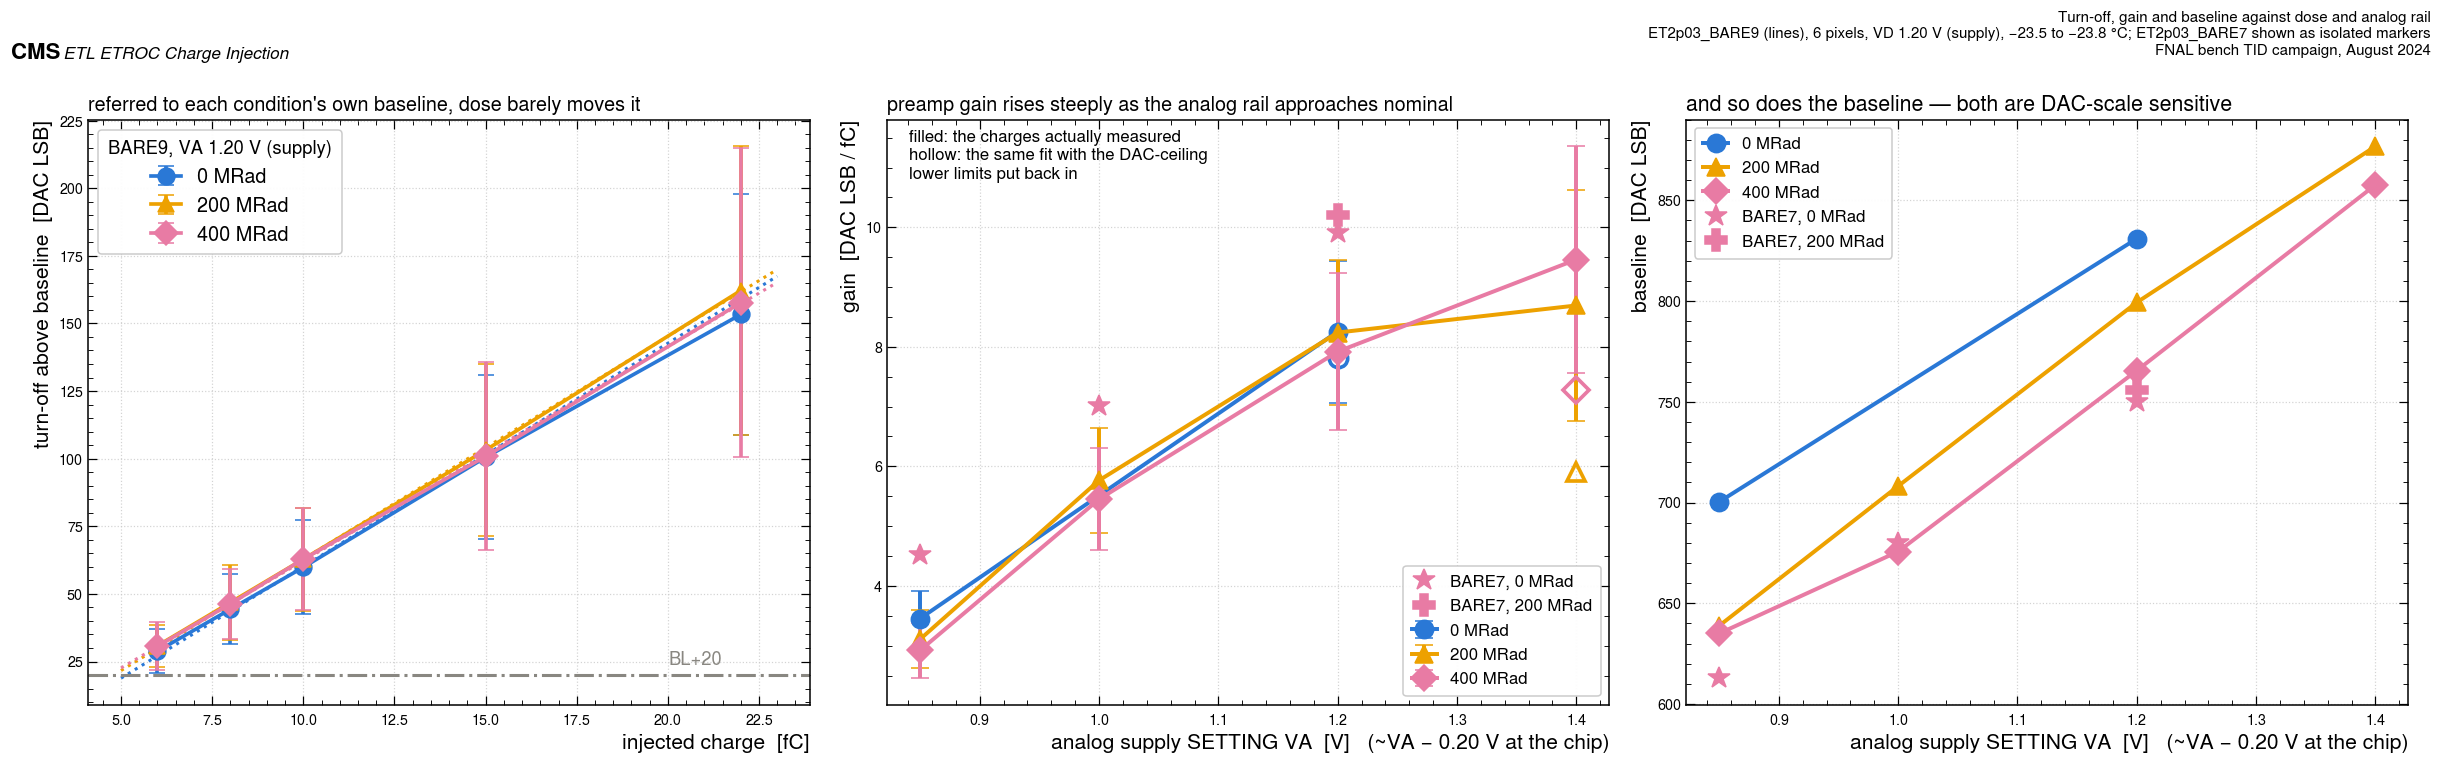

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
DCOL = {0.0: Q.C_BLUE, 200.0: Q.C_YELLOW, 400.0: Q.C_MAG}
DMK = {0.0: "o", 200.0: "^", 400.0: "D"}
ax = axs[0]
for dose in [0.0, 200.0, 400.0]:
    cfg = cfg_of("ET2p03_BARE9", int(dose), 1.20)
    if cfg is None:
        continue
    g = TO[TO.config == cfg]
    p = g.groupby("charge_fC").turnoff_offset.agg(["mean", "std"])
    ax.errorbar(p.index, p["mean"], yerr=p["std"], fmt="-", marker=DMK[dose], ms=11, lw=2.4,
                color=DCOL[dose], capsize=5, label=f"{int(dose)} MRad")
    row = GB[GB.config == cfg].iloc[0]
    xf = np.linspace(5, 23, 40)
    ax.plot(xf, row.gain_dac_per_fc * xf + row.intercept_offset_dac, ":", color=DCOL[dose], lw=2.0)
ax.axhline(Q.OP_OFFSET, color=Q.GREY, ls="-.", lw=2)
ax.text(21.5, Q.OP_OFFSET + 4, "BL+20", fontsize=12, color=Q.GREY, ha="right")
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("turn-off above baseline  [DAC LSB]")
ax.legend(fontsize=13, title="BARE9, VA 1.20 V (supply)", title_fontsize=12)
ax.set_title("referred to each condition's own baseline, dose barely moves it",
             loc="left", fontsize=13)

ax = axs[1]
for dose in [0.0, 200.0, 400.0]:
    s = GB[(GB.chip == "ET2p03_BARE9") & (GB.dose == dose)].sort_values("va")
    if not len(s):
        continue
    ax.errorbar(s.va, s.gain_dac_per_fc, yerr=s.gain_sem, fmt="-", marker=DMK[dose], ms=12,
                lw=2.6, color=DCOL[dose], capsize=6, label=f"{int(dose)} MRad")
    hollow = s[s.n_at_ceiling > 0]
    ax.plot(hollow.va, hollow.gain_with_ceiling, marker=DMK[dose], ms=12, ls="", mfc="none",
            mec=DCOL[dose], mew=2.4)
ax.set_xlabel("analog supply SETTING VA  [V]   (~VA − 0.20 V at the chip)")
ax.set_ylabel("gain  [DAC LSB / fC]")
ax.legend(fontsize=13)
s7g = GB[(GB.chip == "ET2p03_BARE7")].sort_values(["dose", "va"])
for dose, mk in [(0.0, "*"), (200.0, "P")]:
    ss = s7g[s7g.dose == dose]
    if len(ss):
        ax.plot(ss.va, ss.gain_dac_per_fc, ls="", marker=mk, ms=15, color=Q.C_MAG,
                label=f"BARE7, {int(dose)} MRad")
ax.text(0.03, 0.90, "filled: the charges actually measured\nhollow: the same fit with the DAC-ceiling\nlower limits put back in",
        transform=ax.transAxes, fontsize=11)
ax.legend(fontsize=11)
ax.set_title("preamp gain rises steeply as the analog rail approaches nominal",
             loc="left", fontsize=13)

ax = axs[2]
for dose in [0.0, 200.0, 400.0]:
    s = GB[(GB.chip == "ET2p03_BARE9") & (GB.dose == dose)].sort_values("va")
    if not len(s):
        continue
    ax.plot(s.va, s.BL_mean, "-", marker=DMK[dose], ms=12, lw=2.6, color=DCOL[dose],
            label=f"{int(dose)} MRad")
ax.set_xlabel("analog supply SETTING VA  [V]   (~VA − 0.20 V at the chip)")
for dose, mk in [(0.0, "*"), (200.0, "P")]:
    ss = s7g[s7g.dose == dose]
    if len(ss):
        ax.plot(ss.va, ss.BL_mean, ls="", marker=mk, ms=15, color=Q.C_MAG,
                label=f"BARE7, {int(dose)} MRad")
ax.set_ylabel("baseline  [DAC LSB]")
ax.legend(fontsize=11)
ax.set_title("and so does the baseline — both are DAC-scale sensitive", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Turn-off, gain and baseline against dose and analog rail",
             tag="ET2p03_BARE9 (lines), 6 pixels, VD 1.20 V (supply), −23.5 to −23.8 °C; "
                 "ET2p03_BARE7 shown as isolated markers", scale=0.62,
             campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig1_turnoff_and_gain")
plt.show()

## 7. The money plot

TOA jitter against threshold, one curve per injected charge, at each dose. The jitter is the
per-point TOA standard deviation converted to picoseconds through that point's own CAL, and the
quantisation floor `LSB/√12` is drawn on every panel — the same construction as notebook 01,
and the same warning applies twice over here, because the injection is synchronous and there is
no sensor.

Both moments here are the **CAL-windowed** ones of section 4.4. Without that window the decode
artefact puts a charge-independent bump into every one of these curves at whatever threshold
offset the affected absolute-DAC block happens to land on, and the median over six pixels turns
six different DAC blocks into one smooth-looking feature that is not physics. Section 4.4 draws
the before and after.

With six pixels rather than twelve, a single badly behaved pixel moves a mean a long way, so the
pooled curves show the **median over pixels with the inter-quartile band**, and the tabulated
numbers carry both the mean with its pixel RMS and the median.

In [21]:
CAL_MED = M.groupby("config").cal_mean.median()
lsb_ref, floor_ref = Q.quantisation_floor_ps(CAL_MED[CFG0])
print("median CAL, per condition:")
print((M.merge(COND[["config", "label"]], on="config").groupby("label").cal_mean.median()).round(1).to_string())
print("\nreference condition %s: CAL %.1f -> one TOA code %.2f ps, floor LSB/sqrt(12) = %.2f ps"
      % (REF.label, CAL_MED[CFG0], lsb_ref, floor_ref))
RESULTS["quantisation_floor_ps"] = float(floor_ref)
RESULTS["toa_lsb_ps"] = float(lsb_ref)

jit_rows = []
for cfg, g in M.groupby("config"):
    for off in Q.OFFS:
        s = g[g.offset == off]
        for ch, gg in s.groupby("charge_fC"):
            p = Q.pooled(gg.jitter_ps)
            jit_rows.append(dict(config=cfg, offset=off, charge_fC=ch, jitter_mean=p["mean"],
                                 jitter_pixel_rms=p["rms"], jitter_median=gg.jitter_ps.median(),
                                 n_pixels=p["n"]))
JIT = pd.DataFrame(jit_rows).merge(COND[["config", "label", "chip", "dose", "va"]], on="config")
JIT.to_csv(Q.OUTDIR / "et2p03_jitter_by_offset.csv", index=False)
print("\nTOA jitter at BL+20 [ps], mean over pixels (median in brackets), VA 1.20 V (supply)\n")
j20 = JIT[(JIT.offset == 20) & (JIT.va == 1.20)]
print(j20.pivot_table(index="charge_fC", columns="label", values="jitter_mean").round(1).to_string())
print()
print(j20.pivot_table(index="charge_fC", columns="label", values="jitter_median").round(1).to_string())

median CAL, per condition:
label
BARE7, 0 MRad, VA 0.85 V (supply)      190.2
BARE7, 0 MRad, VA 1.00 V (supply)      190.2
BARE7, 0 MRad, VA 1.20 V (supply)      189.9
BARE7, 200 MRad, VA 1.20 V (supply)    189.7
BARE9, 0 MRad, VA 0.85 V (supply)      185.6
BARE9, 0 MRad, VA 1.20 V (supply)      184.9
BARE9, 200 MRad, VA 0.85 V (supply)    185.7
BARE9, 200 MRad, VA 1.00 V (supply)    185.5
BARE9, 200 MRad, VA 1.20 V (supply)    185.3
BARE9, 200 MRad, VA 1.40 V (supply)    185.4
BARE9, 400 MRad, VA 0.85 V (supply)    181.7
BARE9, 400 MRad, VA 1.00 V (supply)    181.3
BARE9, 400 MRad, VA 1.20 V (supply)    181.4
BARE9, 400 MRad, VA 1.40 V (supply)    185.2

reference condition BARE9, 0 MRad, VA 1.20 V (supply): CAL 184.9 -> one TOA code 16.90 ps, floor LSB/sqrt(12) = 4.88 ps

TOA jitter at BL+20 [ps], mean over pixels (median in brackets), VA 1.20 V (supply)

label      BARE7, 0 MRad, VA 1.20 V (supply)  BARE7, 200 MRad, VA 1.20 V (supply)  BARE9, 0 MRad, VA 1.20 V (supply)  BARE9, 200 M

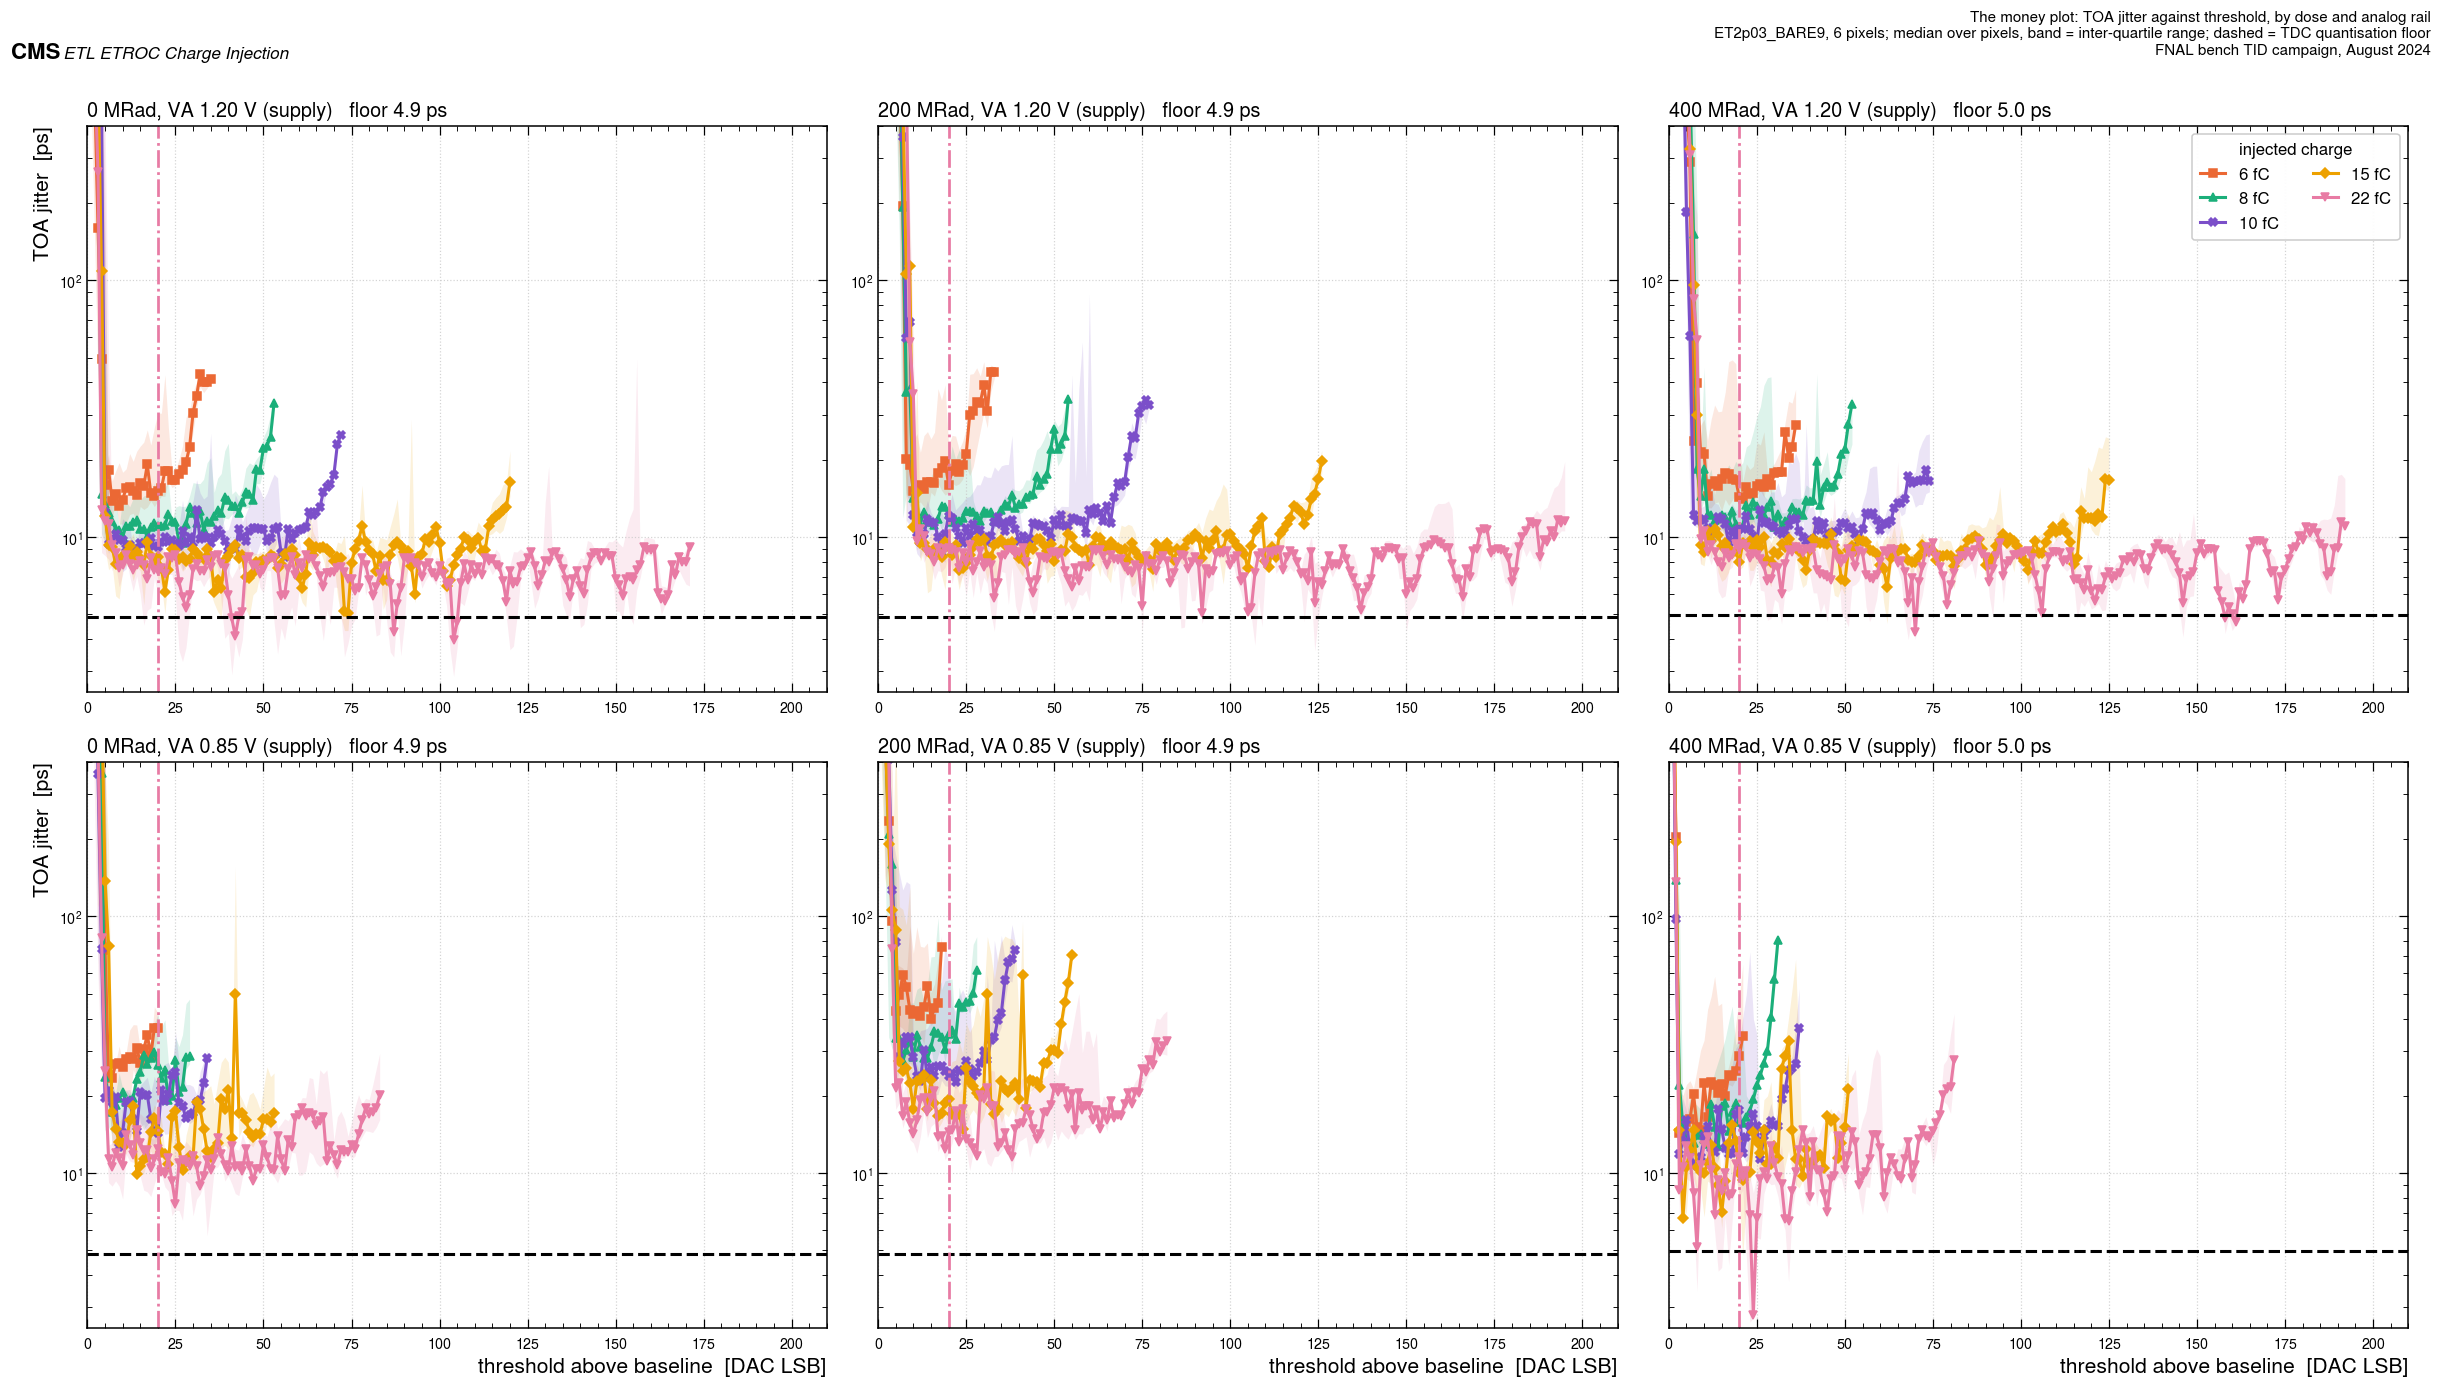

In [22]:
VA_PANELS = [1.20, 0.85]
fig, axs = plt.subplots(2, 3, figsize=(22, 12))
for i, va in enumerate(VA_PANELS):
    for j, dose in enumerate([0.0, 200.0, 400.0]):
        ax = axs[i, j]
        cfg = cfg_of("ET2p03_BARE9", int(dose), va)
        if cfg is None or cfg not in set(M.config):
            ax.text(0.5, 0.5, "not taken", ha="center", va="center", transform=ax.transAxes,
                    fontsize=20, color=Q.GREY)
            ax.set_title(f"{int(dose)} MRad, VA {va:.2f} V (supply)", loc="left", fontsize=13)
            continue
        g = M[M.config == cfg]
        _, fl = Q.quantisation_floor_ps(g.cal_mean.median())
        for ch in Q.ET2P03_CHARGES:
            sub = g[g.charge_fC == ch]
            if not len(sub):
                continue
            grp = sub.groupby("offset").jitter_ps
            med, q1, q3, n = grp.median(), grp.quantile(0.25), grp.quantile(0.75), grp.size()
            keep = n >= 3
            ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=5, lw=2.0,
                    color=Q.CCOL[ch], label=f"{ch:.0f} fC")
            ax.fill_between(med.index[keep], q1[keep], q3[keep], color=Q.CCOL[ch], alpha=0.15, lw=0)
        ax.axhline(fl, color="black", ls="--", lw=2.0)
        ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.8)
        ax.set_yscale("log")
        ax.set_ylim(2.5, 400)
        ax.set_xlim(0, 210)
        ax.set_title(f"{int(dose)} MRad, VA {va:.2f} V (supply)   floor {fl:.1f} ps", loc="left", fontsize=13)
        if i == 1:
            ax.set_xlabel("threshold above baseline  [DAC LSB]")
        if j == 0:
            ax.set_ylabel("TOA jitter  [ps]")
        if i == 0 and j == 2:
            ax.legend(title="injected charge", ncol=2, fontsize=11, title_fontsize=11)
fig.tight_layout()
Q.fig_header(fig, "The money plot: TOA jitter against threshold, by dose and analog rail",
             tag="ET2p03_BARE9, 6 pixels; median over pixels, band = inter-quartile range; "
                 "dashed = TDC quantisation floor", scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig2_money_plot")
plt.show()

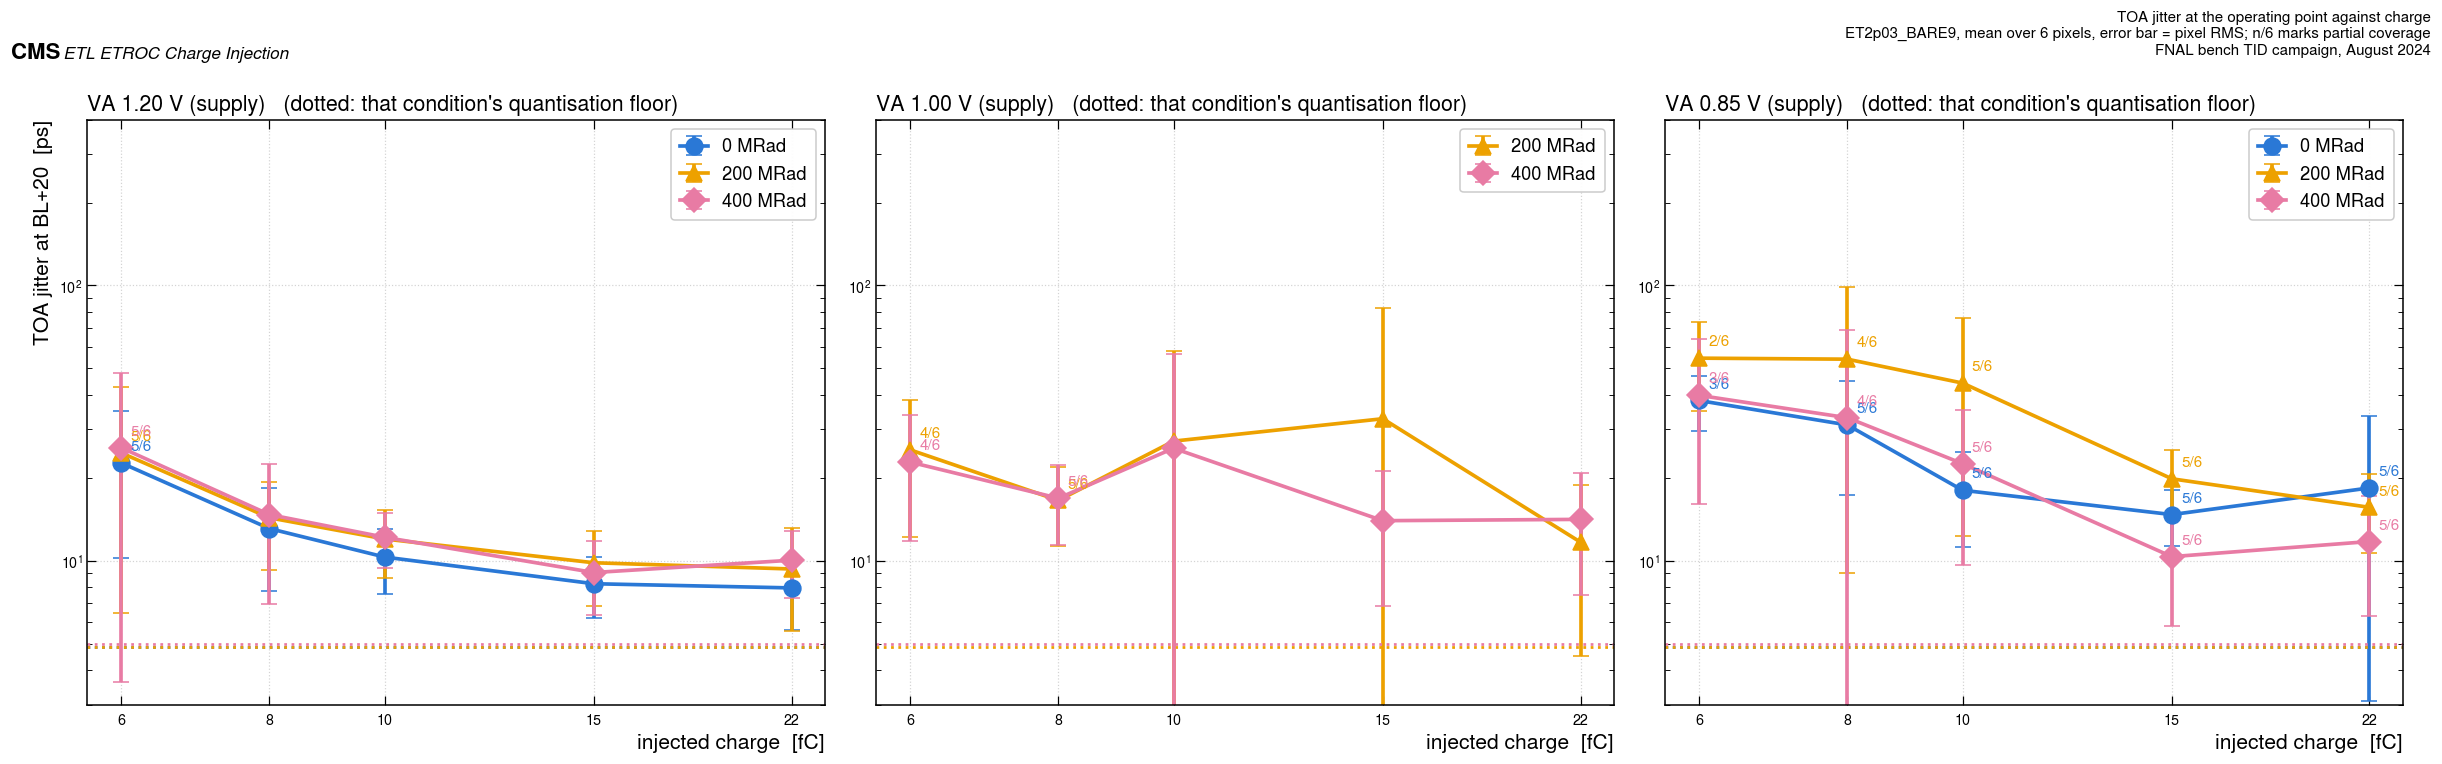

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
for j, va in enumerate([1.20, 1.00, 0.85]):
    ax = axs[j]
    for dose in [0.0, 200.0, 400.0]:
        cfg = cfg_of("ET2p03_BARE9", int(dose), va)
        if cfg is None or cfg not in set(M.config):
            continue
        s = JIT[(JIT.config == cfg) & (JIT.offset == 20)].sort_values("charge_fC")
        ax.errorbar(s.charge_fC, s.jitter_mean, yerr=s.jitter_pixel_rms, fmt="-", marker=DMK[dose],
                    ms=11, lw=2.4, color=DCOL[dose], capsize=5, label=f"{int(dose)} MRad")
        for _, rr in s.iterrows():
            if rr.n_pixels < 6:
                ax.annotate(f"{int(rr.n_pixels)}/6", (rr.charge_fC, rr.jitter_mean),
                            textcoords="offset points", xytext=(6, 8), fontsize=10, color=DCOL[dose])
        _, fl = Q.quantisation_floor_ps(M[M.config == cfg].cal_mean.median())
        ax.axhline(fl, color=DCOL[dose], ls=":", lw=1.8)
    Q.charge_axis(ax, charges=Q.ET2P03_CHARGES)
    ax.set_yscale("log")
    ax.set_ylim(3, 400)
    ax.set_xlabel("injected charge  [fC]")
    if j == 0:
        ax.set_ylabel("TOA jitter at BL+20  [ps]")
    ax.legend(fontsize=12)
    ax.set_title(f"VA {va:.2f} V (supply)   (dotted: that condition's quantisation floor)",
                 loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "TOA jitter at the operating point against charge",
             tag="ET2p03_BARE9, mean over 6 pixels, error bar = pixel RMS; n/6 marks partial coverage",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig3_jitter_vs_charge")
plt.show()

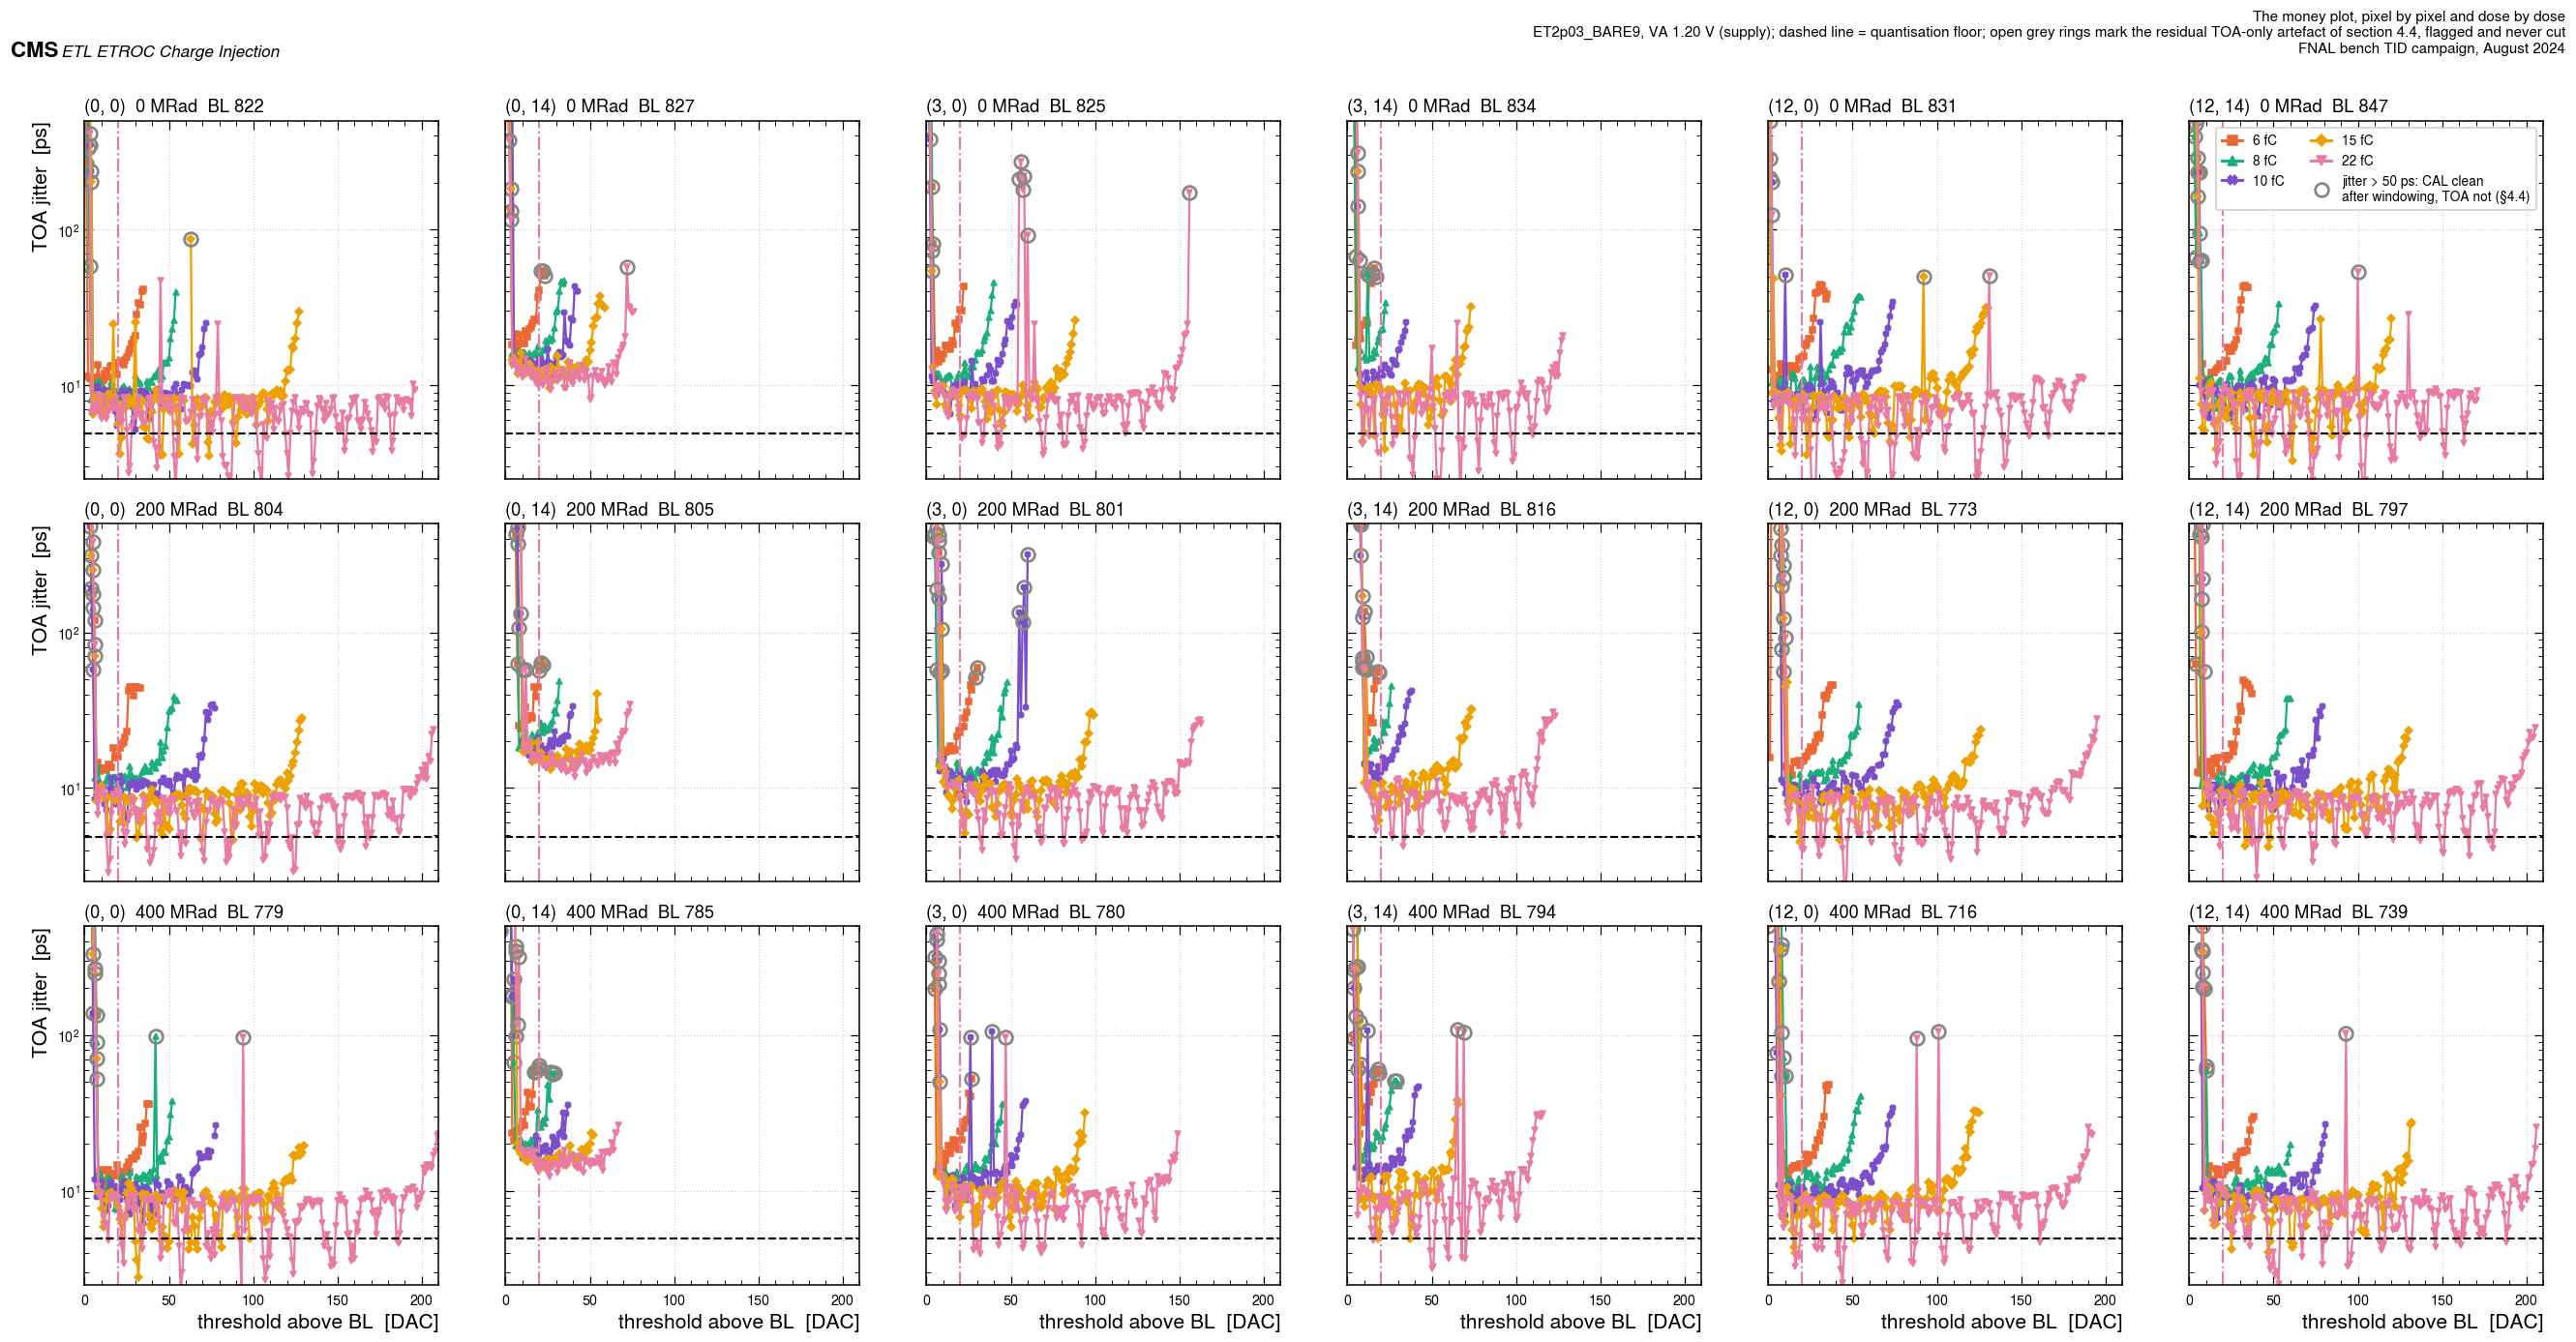

In [24]:
fig, axs = plt.subplots(3, 6, figsize=(24, 12), sharex=True, sharey=True)
for i, dose in enumerate([0.0, 200.0, 400.0]):
    cfg = cfg_of("ET2p03_BARE9", int(dose), 1.20)
    g = M[M.config == cfg]
    _, fl = Q.quantisation_floor_ps(g.cal_mean.median())
    for k, (r, c) in enumerate(Q.ET2P03_PIXELS):
        ax = axs[i, k]
        gg = g[(g.row == r) & (g.col == c)]
        for ch in Q.ET2P03_CHARGES:
            s = gg[gg.charge_fC == ch].sort_values("offset")
            if len(s) < 2:
                continue
            ax.plot(s.offset, s.jitter_ps, "-", marker=Q.CMK[ch], ms=3.5, lw=1.5, color=Q.CCOL[ch])
            bad = s[s.toa_spike_50ps]
            if len(bad):
                ax.plot(bad.offset, bad.jitter_ps, ls="", marker="o", ms=9, mfc="none",
                        mec=Q.GREY, mew=1.8)
        ax.axhline(fl, color="black", ls="--", lw=1.4)
        ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.4)
        ax.set_yscale("log")
        blv = BL[(BL.config == cfg) & (BL.row == r) & (BL.col == c)]
        ax.set_title("(%d, %d)  %d MRad  BL %.0f" % (r, c, dose, blv.BL.iloc[0]),
                     loc="left", fontsize=12)
for ax in axs[-1]:
    ax.set_xlabel("threshold above BL  [DAC]")
for ax in axs[:, 0]:
    ax.set_ylabel("TOA jitter  [ps]")
axs[0, 0].set_xlim(0, 210)
axs[0, 0].set_ylim(2.5, 500)
handles = [plt.Line2D([], [], color=Q.CCOL[c], marker=Q.CMK[c], lw=2, label=f"{c} fC")
           for c in Q.ET2P03_CHARGES]
handles.append(plt.Line2D([], [], ls="", marker="o", ms=9, mfc="none", mec=Q.GREY, mew=1.8,
                          label="jitter > 50 ps: CAL clean\nafter windowing, TOA not (§4.4)"))
axs[0, -1].legend(handles=handles, fontsize=9, ncol=2, loc="upper right")
fig.tight_layout()
Q.fig_header(fig, "The money plot, pixel by pixel and dose by dose",
             tag="ET2p03_BARE9, VA 1.20 V (supply); dashed line = quantisation floor; open grey rings "
                 "mark the residual TOA-only artefact of section 4.4, flagged and never cut",
             scale=0.62,
             campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig4_money_plot_per_pixel")
plt.show()

## 8. The threshold edge: S-curve width, noise width and ENC

The shared-σ fit of `qinj_common.scurve_sigma` is applied here exactly as in notebooks 01 and
02 — one width shared across a stack of curves, each curve's own 50 % point profiled out, the
uncertainty from a bootstrap over curves, with `curves_from` keeping exactly the curves that
straddle the edge. Nothing about the input is changed here.

Section 5 raised the obvious worry: on the searches whose 50 % crossing is bracketed only
coarsely, is the fit describing an edge the search never probed? The cell below answers it by
refitting each condition on the well-bracketed subset alone and printing both widths.

ENC follows as `σ / gain`, in electrons. It is a ratio of two measured quantities and on this
revision **both** of them are in DAC units set by a reference that moves with the analog rail,
so the ENC is quoted per condition and its rail dependence is shown rather than averaged away.

In [25]:
PRB = PR.merge(BRK, on=["config", "row", "col", "charge_fC"])
sig_rows = []
for cfg, g in PRB.groupby("config"):
    cv_all, _ = Q.curves_from(g, keys=("row", "col", "charge_fC"))
    cv_t, _ = Q.curves_from(g[g.bracket <= 2], keys=("row", "col", "charge_fC"))
    if len(cv_t) < 5:
        continue
    s_a, sd_a, _, _ = Q.scurve_sigma(cv_all, boot=120)
    s_t, _, _, _ = Q.scurve_sigma(cv_t, boot=0)
    gv = float(GB[GB.config == cfg].gain_dac_per_fc.iloc[0])
    nw = Q.pooled(BL[BL.config == cfg].NW_fwhm)
    sig_rows.append(dict(config=cfg, n_curves=len(cv_all), n_curves_tight=len(cv_t),
                         sigma_dac=s_a, sigma_sd=sd_a, sigma_tight_only=s_t,
                         sigma_mv=s_a * Q.LSB_MV, gain_dac_per_fc=gv,
                         ENC_e=Q.enc_electrons(s_a, gv), NW_fwhm=nw["mean"], NW_fwhm_rms=nw["rms"]))
SIG = pd.DataFrame(sig_rows).merge(COND[["config", "label", "chip", "dose", "va"]], on="config")
SIG = SIG.sort_values(["chip", "dose", "va"], na_position="last")
SIG.to_csv(Q.OUTDIR / "et2p03_scurve_sigma_by_condition.csv", index=False)
print(SIG[["label", "n_curves", "n_curves_tight", "sigma_dac", "sigma_sd", "sigma_tight_only",
           "sigma_mv", "gain_dac_per_fc", "ENC_e", "NW_fwhm", "NW_fwhm_rms"]]
      .round(3).to_string(index=False))
print("\nsigma from all curves against sigma from the well-bracketed subset alone:")
print("  max |difference| over all conditions = %.3f DAC"
      % (SIG.sigma_dac - SIG.sigma_tight_only).abs().max())
SREF = SIG[SIG.config == CFG0].iloc[0]
print("\nreference condition %s:" % SREF.label)
print("  sigma  %.2f +- %.2f DAC  = %.3f mV under the assumed LSB" % (SREF.sigma_dac, SREF.sigma_sd, SREF.sigma_mv))
print("  ENC    %.0f electrons" % SREF.ENC_e)
print("  noise-peak FWHM %.2f +- %.2f DAC; the 2024-08-03 autocal map gives NW %.2f DAC on the same pixels"
      % (SREF.NW_fwhm, SREF.NW_fwhm_rms, mp.noise_width_DAC.mean()))
RESULTS.update(sigma_dac=float(SREF.sigma_dac), sigma_sd=float(SREF.sigma_sd),
               enc_e=float(SREF.ENC_e), gain_dac_per_fc=float(REF.gain_dac_per_fc),
               nw_fwhm_dac=float(SREF.NW_fwhm), nw_map_dac=float(mp.noise_width_DAC.mean()))

                                   label  n_curves  n_curves_tight  sigma_dac  sigma_sd  sigma_tight_only  sigma_mv  gain_dac_per_fc    ENC_e  NW_fwhm  NW_fwhm_rms
       BARE7, 0 MRad, VA 0.85 V (supply)        30              22       0.70     0.088              0.70     0.273            4.516  967.525    2.033        0.352
       BARE7, 0 MRad, VA 1.00 V (supply)        30              21       0.85     0.055              0.85     0.332            7.019  755.894    2.736        0.571
       BARE7, 0 MRad, VA 1.20 V (supply)        30              19       1.23     0.099              1.27     0.480            9.905  775.091    3.177        1.243
     BARE7, 200 MRad, VA 1.20 V (supply)        29              19       1.19     0.101              1.20     0.465           10.206  727.748    3.313        1.170
       BARE9, 0 MRad, VA 0.85 V (supply)        30              15       1.06     0.130              1.06     0.414            3.455 1915.086    2.678        0.596
       BARE9, 0 

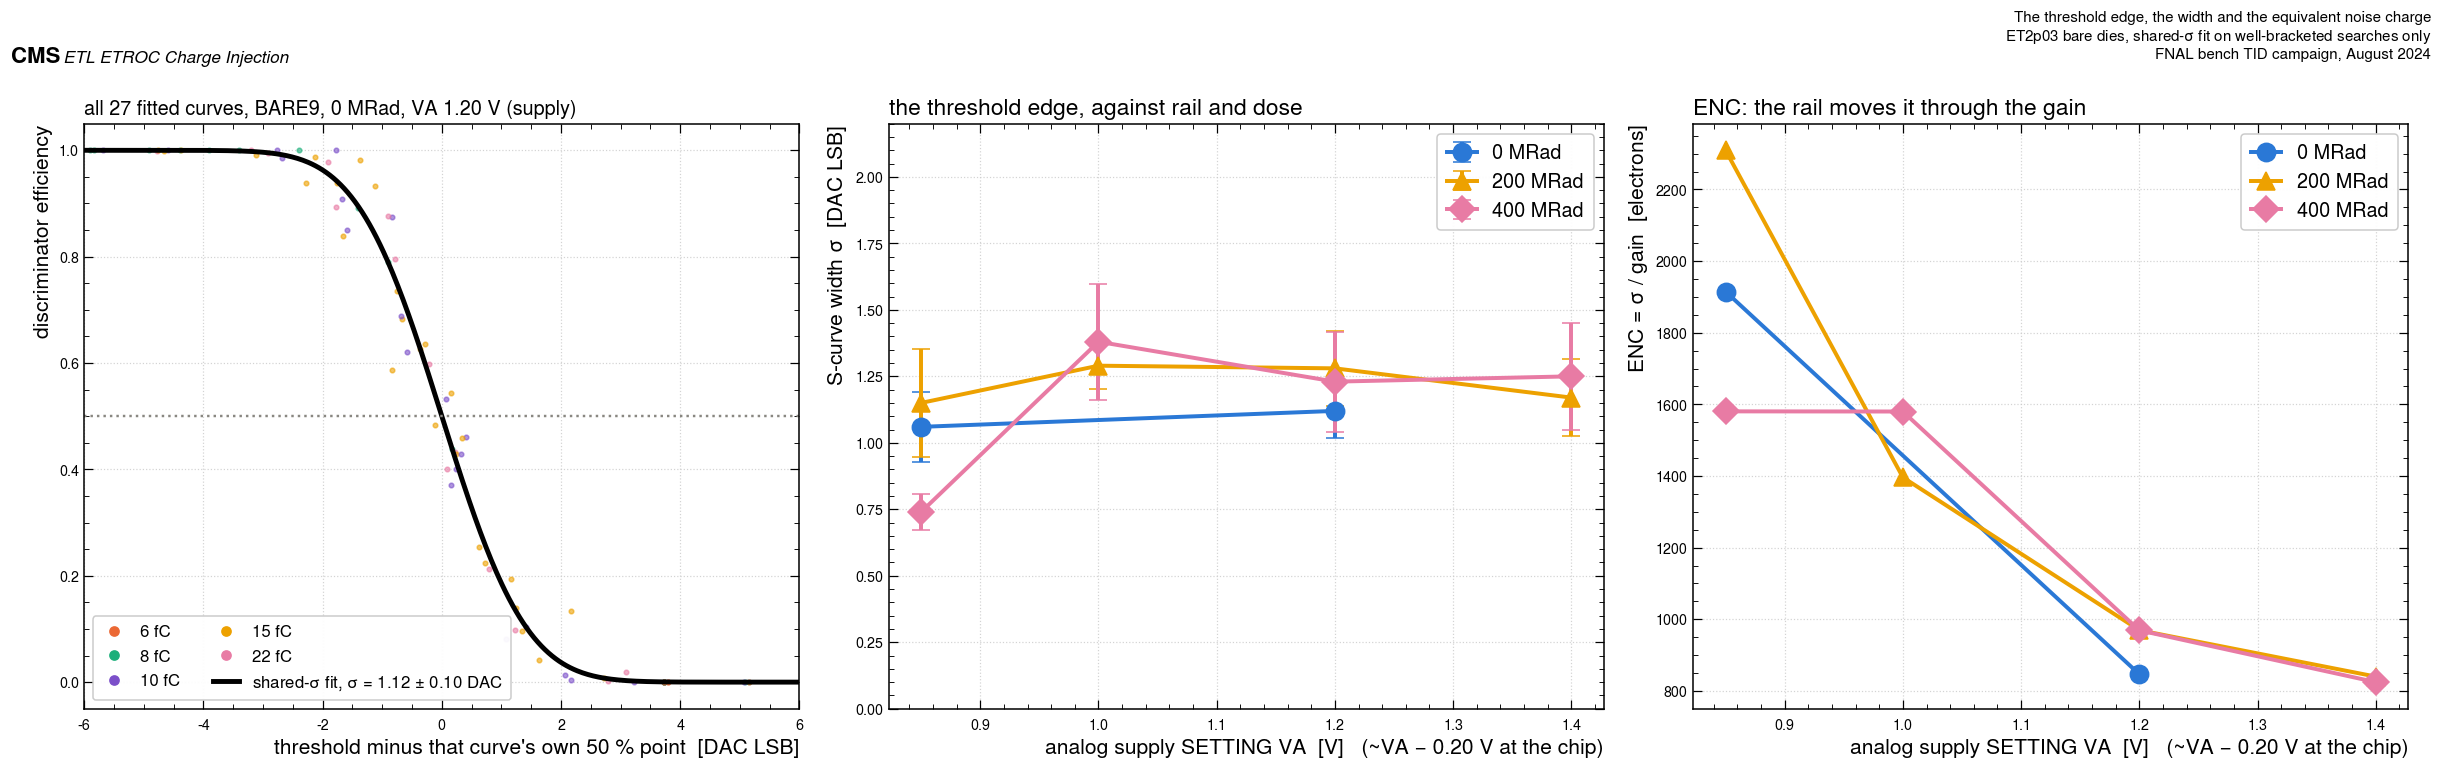

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
g = PRB[PRB.config == CFG0]
cv, meta = Q.curves_from(g, keys=("row", "col", "charge_fC"))
s_, sd_, mus, _ = Q.scurve_sigma(cv, boot=0)
for (dd, ff), mu, k in zip(cv, mus, meta):
    ax.plot(dd - mu, ff, ".", ms=6, color=Q.CCOL[int(k[2])], alpha=0.6)
xx = np.linspace(-6, 6, 400)
ax.plot(xx, Q.gauss_cdf(xx, 0.0, SREF.sigma_dac), "-", color="black", lw=3.2,
        label=f"shared-$\\sigma$ fit, $\\sigma$ = {SREF.sigma_dac:.2f} $\\pm$ {SREF.sigma_sd:.2f} DAC")
ax.axhline(0.5, color=Q.GREY, ls=":", lw=1.6)
ax.set_xlim(-6, 6)
ax.set_xlabel("threshold minus that curve's own 50 % point  [DAC LSB]")
ax.set_ylabel("discriminator efficiency")
hh = [plt.Line2D([], [], color=Q.CCOL[c], marker="o", ls="", label=f"{c} fC") for c in Q.ET2P03_CHARGES]
ax.legend(handles=hh + ax.get_legend_handles_labels()[0], fontsize=11, ncol=2, loc="lower left")
ax.set_title(f"all {len(cv)} fitted curves, {REF.label}", loc="left", fontsize=13)

ax = axs[1]
for dose, mk in [(0.0, "o"), (200.0, "^"), (400.0, "D")]:
    s = SIG[(SIG.chip == "ET2p03_BARE9") & (SIG.dose == dose)].sort_values("va")
    if not len(s):
        continue
    ax.errorbar(s.va, s.sigma_dac, yerr=s.sigma_sd, fmt="-", marker=mk, ms=12, lw=2.6,
                color=DCOL[dose], capsize=6, label=f"{int(dose)} MRad")
nwl = BLS[(BLS.chip == "ET2p03_BARE9") & BLS.dose.notna()]
ax.set_xlabel("analog supply SETTING VA  [V]   (~VA − 0.20 V at the chip)")
ax.set_ylabel("S-curve width $\\sigma$  [DAC LSB]")
ax.set_ylim(0, 2.2)
ax.legend(fontsize=13)
ax.set_title("the threshold edge, against rail and dose", loc="left", fontsize=15)

ax = axs[2]
for dose, mk in [(0.0, "o"), (200.0, "^"), (400.0, "D")]:
    s = SIG[(SIG.chip == "ET2p03_BARE9") & (SIG.dose == dose)].sort_values("va")
    if not len(s):
        continue
    ax.plot(s.va, s.ENC_e, "-", marker=mk, ms=12, lw=2.6, color=DCOL[dose], label=f"{int(dose)} MRad")
ax.set_xlabel("analog supply SETTING VA  [V]   (~VA − 0.20 V at the chip)")
ax.set_ylabel("ENC = $\\sigma$ / gain  [electrons]")
ax.legend(fontsize=13)
ax.set_title("ENC: the rail moves it through the gain", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "The threshold edge, the width and the equivalent noise charge",
             tag="ET2p03 bare dies, shared-$\\sigma$ fit on well-bracketed searches only",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig5_scurves")
plt.show()

The threshold edge on this revision is **wider in DAC than on ET2.01**: 1.12 ± 0.10 DAC at the
reference condition against 0.92 ± 0.05 on the bare ET2.01 die and 0.93 ± 0.07 on the hybrid.
Across every condition it sits between 1.0 and 1.4 DAC with no visible dose trend, and
restricting the fit to the well-bracketed searches alone changes it by at most 0.03 DAC, so the
coarse-bracket worry of section 5 does not propagate into the width.

Whether that wider edge means a noisier front end or a finer DAC step is **not decidable from
this campaign**, and that is the whole difficulty with an internal reference: σ is measured in
DAC, and one DAC on ET2.03 is not demonstrably the same voltage as one DAC on ET2.01. The ENC
ratio σ/gain is the quantity that removes the DAC scale — both numerator and denominator carry
it — and it is what notebook 04 compares across revisions.

**One condition is an outlier and is flagged rather than smoothed over.** BARE9 at 400 MRad,
VA 0.85 V returns σ = 0.74 DAC and a noise-peak FWHM of 1.48 DAC, roughly half of every other
condition, on the same six pixels. Its baseline pixel-to-pixel RMS is also the largest in the
campaign. Nothing in the reduction distinguishes it, and no monitoring exists that could say
what the chip was doing that afternoon; it is the lowest rail at the highest dose, which is
where section 12 shows the chip closest to failing, and that is as far as the evidence goes.

## 9. Time over threshold

TOT against charge at the three tabulated threshold offsets, fitted with the same
`TOT = a + b ln(Q/fC)` law used in notebooks 01 and 02, by the same weighted least squares in
`ln Q`. The fit is exact rather than iterative, so a large χ²/ndf is a statement about the
shape, not about convergence.

In [27]:
TOT = Q.pooled_at_offsets(M, ["config"], ["tot_mean", "tot_ns", "toa_ns", "cal_mean"],
                          bl_col="BL", charge_col="charge_fC")
TOT = TOT.rename(columns={"tot_mean_mean": "tot_code_mean", "tot_mean_rms": "tot_code_pixel_rms",
                          "tot_mean_n": "n_pixels"})
TOT["tot_code_sem"] = TOT.tot_code_pixel_rms / np.sqrt(TOT.n_pixels.clip(lower=1))
TOT = TOT.merge(COND[["config", "label", "chip", "dose", "va"]], on="config")
TOT.to_csv(Q.OUTDIR / "et2p03_tot_vs_charge_offsets.csv", index=False)
print("TOT [code] at the three offsets, %s\n" % REF.label)
print(TOT[TOT.config == CFG0][["offset", "charge_fC", "tot_code_mean", "tot_code_pixel_rms",
                               "tot_ns_mean", "n_pixels"]].round(3).to_string(index=False))

fits = {}
for cfg, g in TOT.groupby("config"):
    for off in Q.OFFS:
        s = g[(g.offset == off) & g.tot_code_mean.notna()].sort_values("charge_fC")
        if len(s) < 3:
            continue
        a, b, ae, be, c2, res = Q.logfit(s.charge_fC, s.tot_code_mean,
                                         s.tot_code_sem.replace(0, np.nan).fillna(0.5))
        fits[(cfg, off)] = dict(a=a, b=b, a_err=ae, b_err=be, chi2_ndf=c2,
                                res={int(q): float(v) for q, v in zip(s.charge_fC, res)})
FIT = pd.DataFrame([dict(config=k[0], offset=k[1], **{kk: vv for kk, vv in v.items() if kk != "res"})
                    for k, v in fits.items()]).merge(COND[["config", "label", "chip", "dose", "va"]],
                                                     on="config")
FIT.to_csv(Q.OUTDIR / "et2p03_tot_logfits.csv", index=False)
print("\nTOT = a + b ln(Q/fC), at BL+20, every condition\n")
print(FIT[FIT.offset == 20][["label", "a", "a_err", "b", "b_err", "chi2_ndf"]]
      .sort_values("label").round(2).to_string(index=False))
f20 = fits[(CFG0, 20)]
print("\n%s, BL+20:  TOT = %.2f + %.2f ln(Q/fC), chi2/ndf %.2f" % (REF.label, f20["a"], f20["b"], f20["chi2_ndf"]))
print("  residuals [code]:", {k: round(v, 2) for k, v in f20["res"].items()})
RESULTS["tot_fit_off20"] = {k: (v if not isinstance(v, dict) else {str(a): float(b) for a, b in v.items()})
                            for k, v in f20.items()}

TOT [code] at the three offsets, BARE9, 0 MRad, VA 1.20 V (supply)

 offset  charge_fC  tot_code_mean  tot_code_pixel_rms  tot_ns_mean  n_pixels
     10        6.0         39.376               4.165        1.331         6
     10        8.0         43.954               3.743        1.484         6
     10       10.0         47.148               2.063        1.593         6
     10       15.0         50.147               1.574        1.695         6
     10       22.0         52.287               1.708        1.768         6
     15        6.0         31.491               8.495        1.067         6
     15        8.0         39.938               4.638        1.349         6
     15       10.0         44.527               3.155        1.504         6
     15       15.0         47.942               1.895        1.619         6
     15       22.0         50.656               2.027        1.721         5
     20        6.0         28.156               7.057        0.950         5
     20 

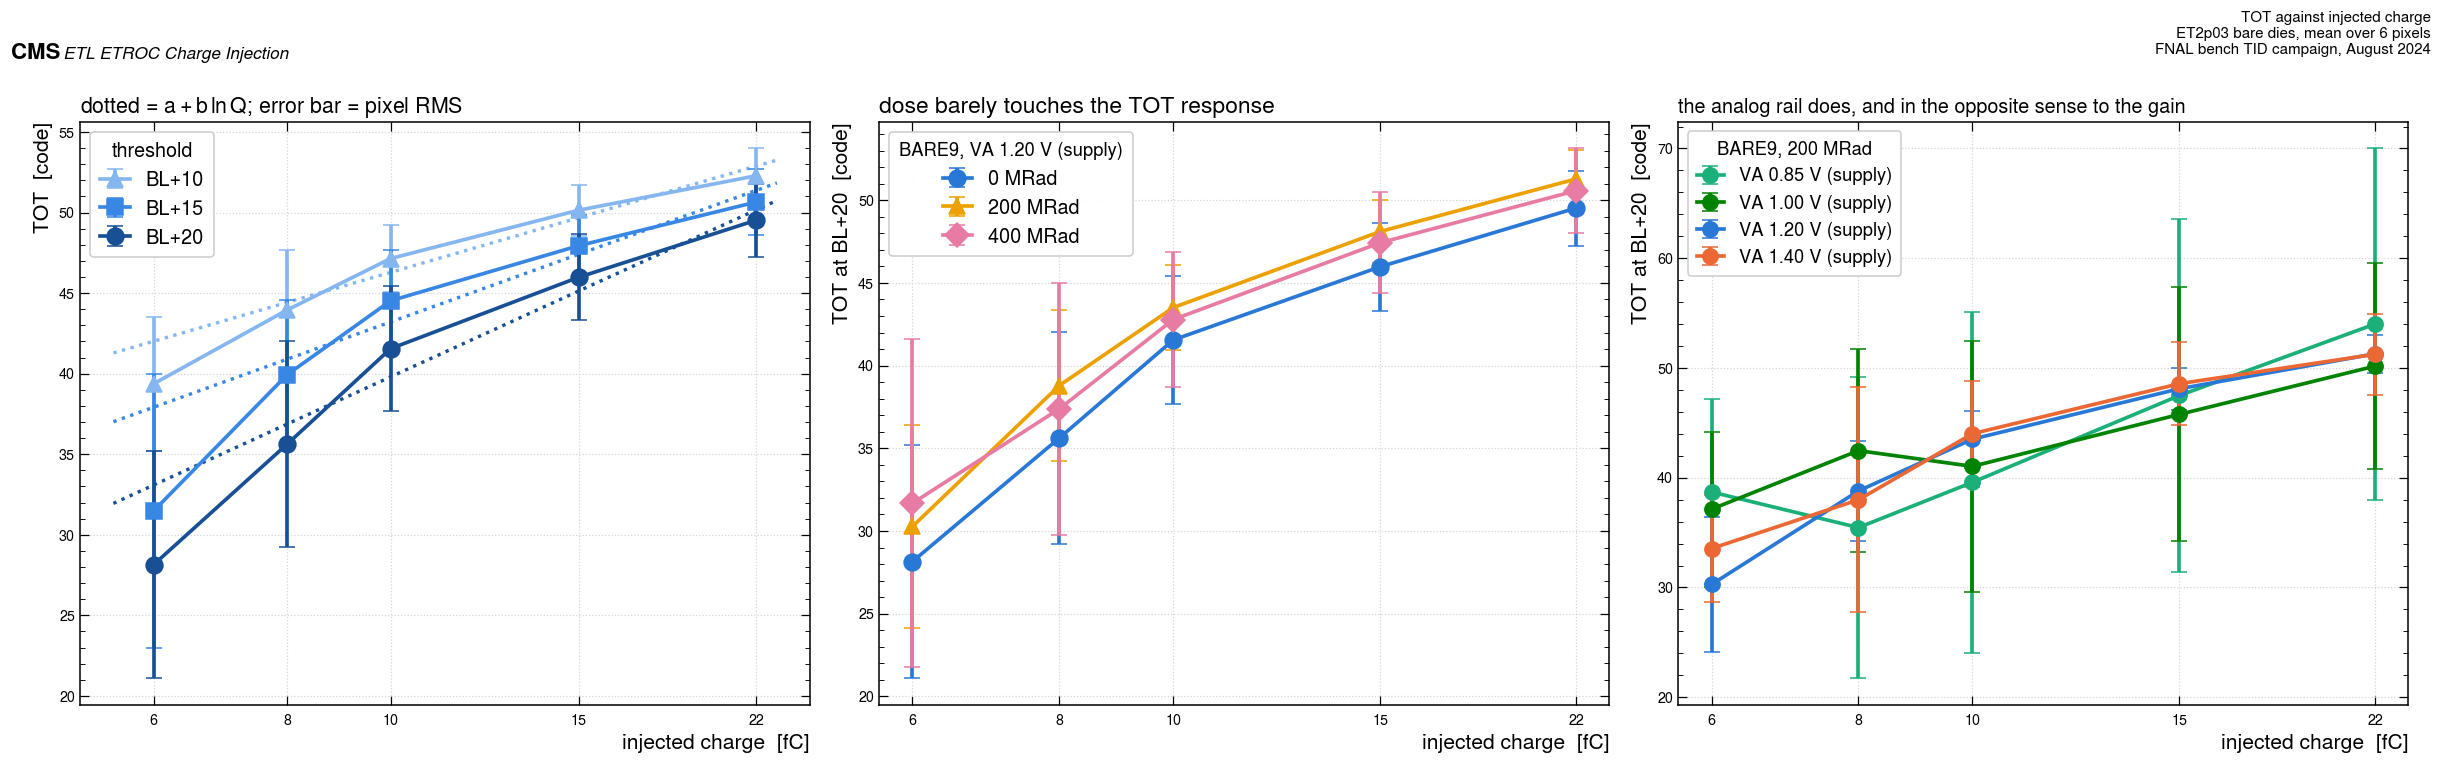

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for off in Q.OFFS:
    s = TOT[(TOT.config == CFG0) & (TOT.offset == off)].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_code_mean, yerr=s.tot_code_pixel_rms, fmt="-", marker=Q.OMK[off],
                ms=11, lw=2.4, color=Q.OCOL[off], capsize=5, label=f"BL+{off}")
    qq = np.linspace(5.5, 23, 200)
    ff = fits.get((CFG0, off))
    if ff:
        ax.plot(qq, ff["a"] + ff["b"] * np.log(qq), ":", color=Q.OCOL[off], lw=2.2)
Q.charge_axis(ax, charges=Q.ET2P03_CHARGES)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT  [code]")
ax.legend(title="threshold", fontsize=13, title_fontsize=13)
ax.set_title("dotted = $a + b\\,\\ln Q$; error bar = pixel RMS", loc="left", fontsize=14)

ax = axs[1]
for dose in [0.0, 200.0, 400.0]:
    cfg = cfg_of("ET2p03_BARE9", int(dose), 1.20)
    if cfg is None or cfg not in set(TOT.config):
        continue
    s = TOT[(TOT.config == cfg) & (TOT.offset == 20)].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_code_mean, yerr=s.tot_code_pixel_rms, fmt="-", marker=DMK[dose],
                ms=11, lw=2.4, color=DCOL[dose], capsize=5, label=f"{int(dose)} MRad")
Q.charge_axis(ax, charges=Q.ET2P03_CHARGES)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [code]")
ax.legend(fontsize=13, title="BARE9, VA 1.20 V (supply)", title_fontsize=12)
ax.set_title("dose barely touches the TOT response", loc="left", fontsize=15)

ax = axs[2]
for va, cc in zip([0.85, 1.00, 1.20, 1.40], [Q.C_AQUA, Q.C_GREEN, Q.C_BLUE, Q.C_ORANGE]):
    cfg = cfg_of("ET2p03_BARE9", 200, va)
    if cfg is None or cfg not in set(TOT.config):
        continue
    s = TOT[(TOT.config == cfg) & (TOT.offset == 20)].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_code_mean, yerr=s.tot_code_pixel_rms, fmt="-", marker="o",
                ms=10, lw=2.4, color=cc, capsize=5, label=f"VA {va:.2f} V (supply)")
Q.charge_axis(ax, charges=Q.ET2P03_CHARGES)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [code]")
ax.legend(fontsize=12, title="BARE9, 200 MRad", title_fontsize=12)
ax.set_title("the analog rail does, and in the opposite sense to the gain",
             loc="left", fontsize=13)
fig.tight_layout()
Q.fig_header(fig, "TOT against injected charge", tag="ET2p03 bare dies, mean over 6 pixels",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig6_tot_vs_charge")
plt.show()

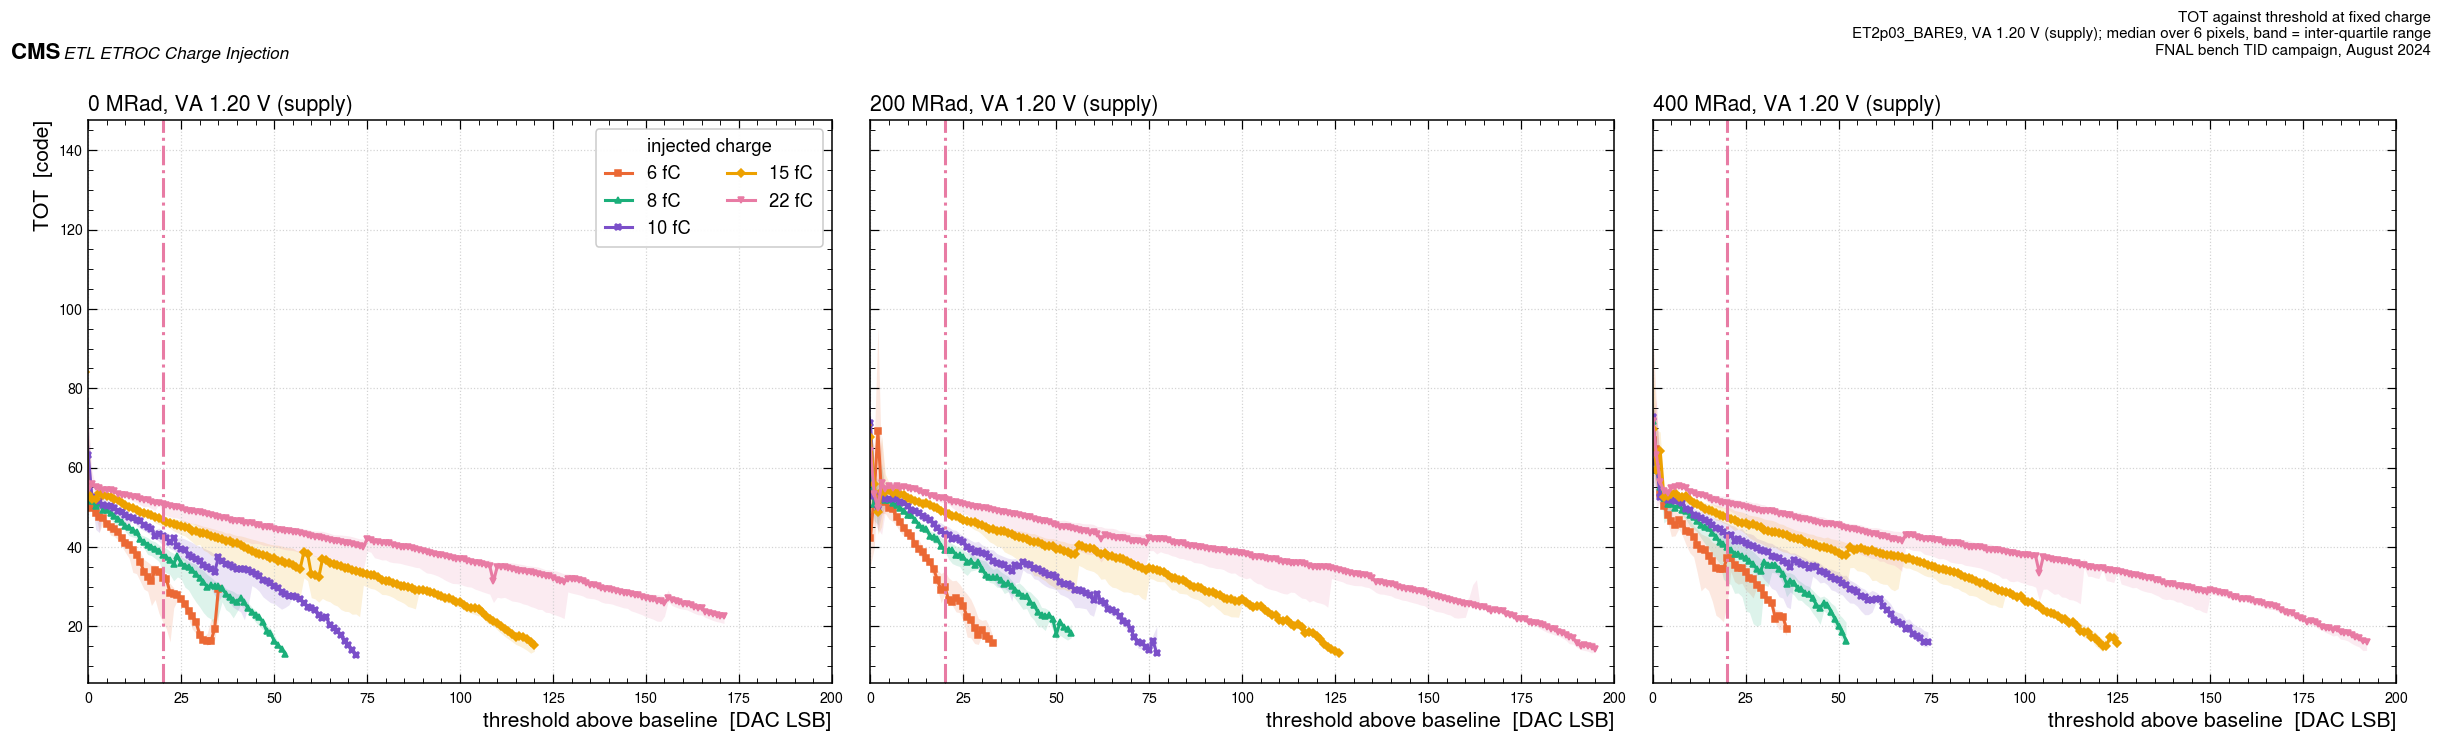

At fixed charge TOT falls with threshold, as it must: a higher threshold is crossed later on
the rising edge and earlier on the falling edge, so the pulse spends less time above it.


In [29]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.2), sharey=True)
for j, dose in enumerate([0.0, 200.0, 400.0]):
    ax = axs[j]
    cfg = cfg_of("ET2p03_BARE9", int(dose), 1.20)
    if cfg is None or cfg not in set(M.config):
        continue
    g = M[M.config == cfg]
    for ch in Q.ET2P03_CHARGES:
        sub = g[g.charge_fC == ch]
        grp = sub.groupby("offset").tot_mean
        med, q1, q3, n = grp.median(), grp.quantile(0.25), grp.quantile(0.75), grp.size()
        keep = n >= 3
        ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=4, lw=2.0, color=Q.CCOL[ch],
                label=f"{ch:.0f} fC")
        ax.fill_between(med.index[keep], q1[keep], q3[keep], color=Q.CCOL[ch], alpha=0.15, lw=0)
    ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
    ax.set_xlim(0, 200)
    ax.set_xlabel("threshold above baseline  [DAC LSB]")
    ax.set_title(f"{int(dose)} MRad, VA 1.20 V (supply)", loc="left", fontsize=14)
    if j == 0:
        ax.set_ylabel("TOT  [code]")
        ax.legend(title="injected charge", ncol=2, fontsize=12, title_fontsize=12)
fig.tight_layout()
Q.fig_header(fig, "TOT against threshold at fixed charge",
             tag="ET2p03_BARE9, VA 1.20 V (supply); median over 6 pixels, band = inter-quartile range",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig7_tot_vs_threshold")
plt.show()
print("At fixed charge TOT falls with threshold, as it must: a higher threshold is crossed later on")
print("the rising edge and earlier on the falling edge, so the pulse spends less time above it.")

## 10. Time walk and CAL stability

In [30]:
walk_rows = []
for cfg, g in M.groupby("config"):
    for ch, gg in g.groupby("charge_fC"):
        m = gg.groupby("offset").toa_ns.median() * 1e3
        walk_rows.append(dict(config=cfg, charge_fC=ch, toa_at_BL10_ps=m.get(10, np.nan),
                              toa_at_BL20_ps=m.get(20, np.nan),
                              walk_10to20_ps=m.get(20, np.nan) - m.get(10, np.nan),
                              off_first=int(m.index[0]), off_last=int(m.index[-1])))
WALK = pd.DataFrame(walk_rows).merge(COND[["config", "label", "chip", "dose", "va"]], on="config")
WALK.to_csv(Q.OUTDIR / "et2p03_walk.csv", index=False)
w20 = WALK[WALK.config == CFG0].set_index("charge_fC").toa_at_BL20_ps
print("%s: median TOA at BL+20 against charge [ps]" % REF.label)
print(w20.round(0).to_dict())
walk_ref = float(w20[22] - w20[6])
print("walk with charge, 6 -> 22 fC at BL+20: %+.0f ps" % walk_ref)
RESULTS["walk_charge_6to22_at_off20_ps"] = walk_ref
print("\nthe same, every condition [ps]:")
wtab = WALK.pivot_table(index="label", columns="charge_fC", values="toa_at_BL20_ps")
wtab["walk 6->22"] = wtab[22.0] - wtab[6.0]
print(wtab.round(0).to_string())

D0 = M[(M.config == CFG0) & (M.scan_family == "money_plot")]
cal_med_rms = D0.cal_std.median()
print("\nCAL over the reference block: min %.1f, max %.1f, median %.1f codes"
      % (D0.cal_mean.min(), D0.cal_mean.max(), D0.cal_mean.median()))
print("median per-point CAL RMS: %.3f codes (%.2f %%), CAL-windowed"
      % (cal_med_rms, 100 * cal_med_rms / D0.cal_mean.median()))
print("the same on the raw moments: %.3f codes -- the difference is section 4.4's artefact"
      % D0.cal_std_raw.median())
print("points outside the pipeline CAL guard band %s (on the mean CAL): %d of %d"
      % (Q.CAL_GUARD, int(((D0.cal_mean < Q.CAL_GUARD[0]) | (D0.cal_mean > Q.CAL_GUARD[1])).sum()), len(D0)))
print("points flagged cal_std_raw > 2 codes, which the guard band does NOT catch: %d of %d (%.1f %%)"
      % (int(D0.cal_rms_gt2.sum()), len(D0), 100 * D0.cal_rms_gt2.mean()))
print("hits rejected by the per-hit CAL window |CAL - cal_mode| <= %d: %.4f %% of %d"
      % (Q.CAL_WINDOW, 100 * (1 - D0.n_hits.sum() / D0.n_hits_raw.sum()), int(D0.n_hits_raw.sum())))
RESULTS["cal_median"] = float(D0.cal_mean.median())
RESULTS["cal_median_point_rms"] = float(cal_med_rms)

BARE9, 0 MRad, VA 1.20 V (supply): median TOA at BL+20 against charge [ps]
{6.0: 3974.0, 8.0: 4161.0, 10.0: 4292.0, 15.0: 4402.0, 22.0: 4492.0}
walk with charge, 6 -> 22 fC at BL+20: +518 ps

the same, every condition [ps]:
charge_fC                               6.0     8.0    10.0    15.0    22.0  walk 6->22
label                                                                                  
BARE7, 0 MRad, VA 0.85 V (supply)    3103.0  3251.0  3323.0  3448.0  3522.0       420.0
BARE7, 0 MRad, VA 1.00 V (supply)    3712.0  3852.0  3912.0  4040.0  4115.0       403.0
BARE7, 0 MRad, VA 1.20 V (supply)    4195.0  4299.0  4372.0  4471.0  4536.0       341.0
BARE7, 200 MRad, VA 1.20 V (supply)  4149.0  4286.0  4360.0  4446.0  4514.0       365.0
BARE9, 0 MRad, VA 0.85 V (supply)    2867.0  3126.0  3246.0  3381.0  3339.0       472.0
BARE9, 0 MRad, VA 1.20 V (supply)    3974.0  4161.0  4292.0  4402.0  4492.0       518.0
BARE9, 200 MRad, VA 0.85 V (supply)  3183.0  3196.0  3264.0  3563.0  370

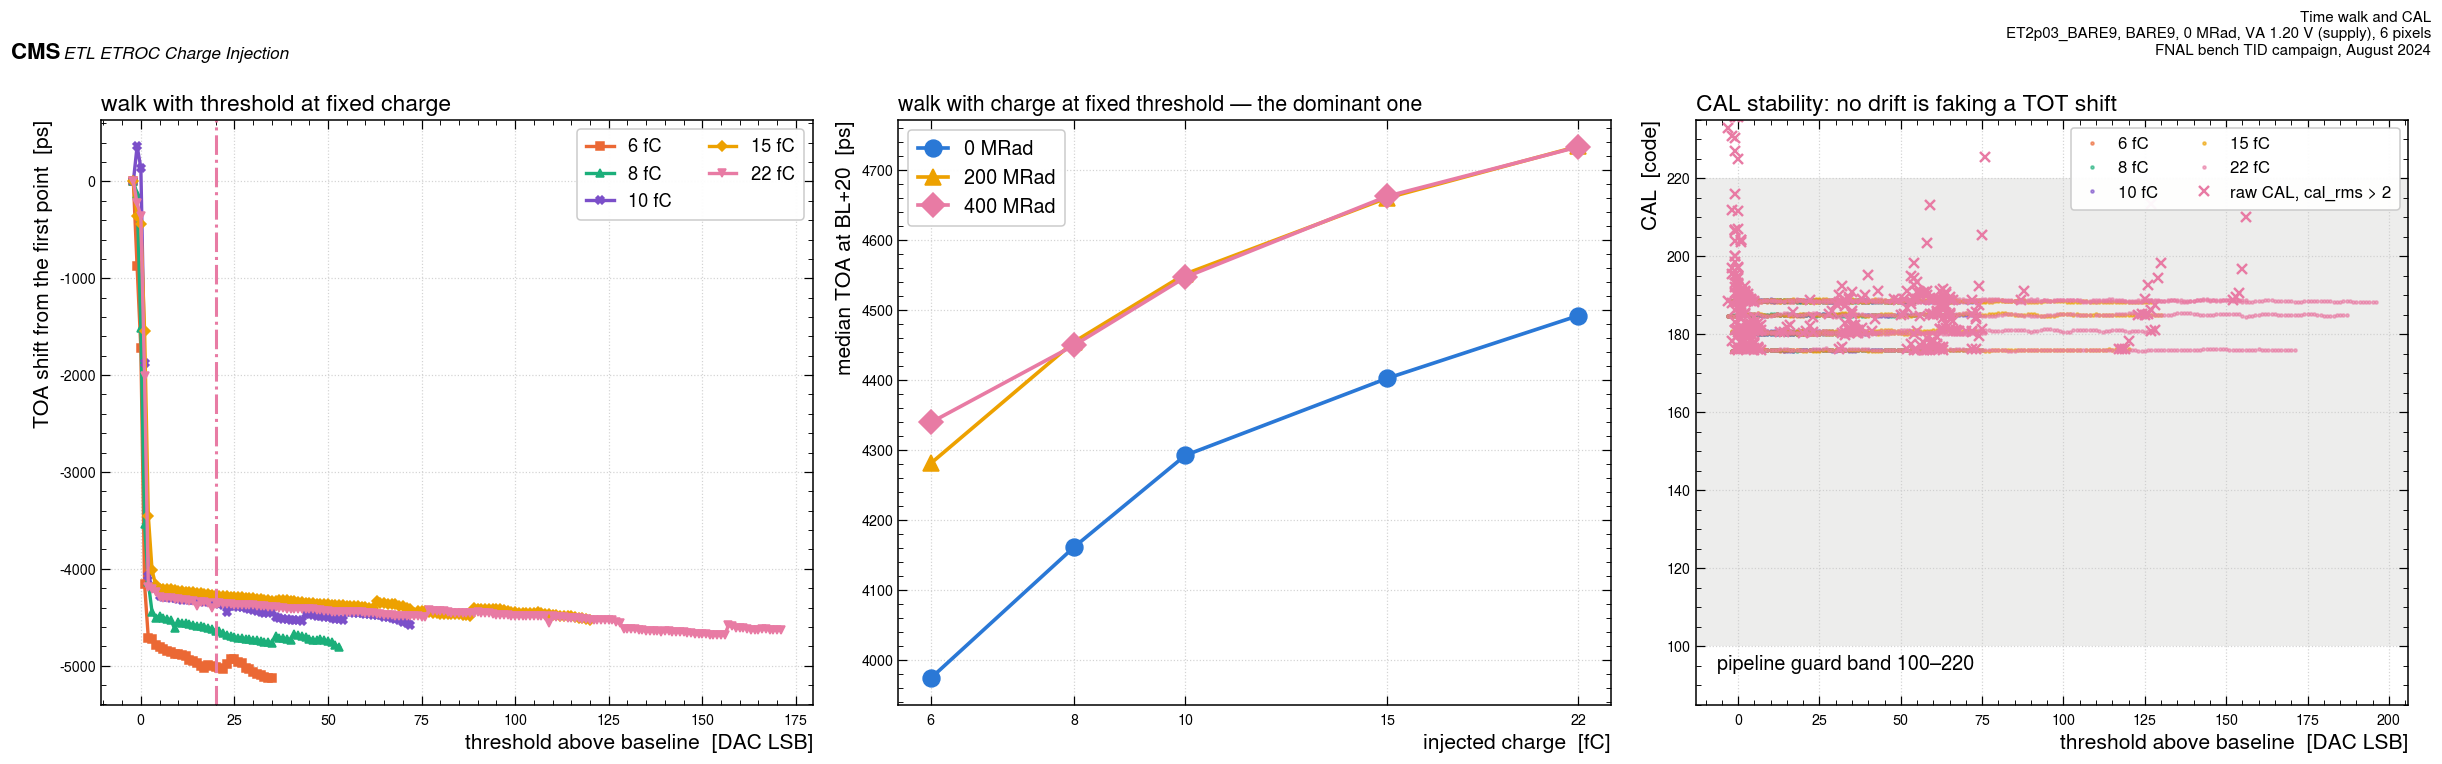

In [31]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for ch in Q.ET2P03_CHARGES:
    sub = D0[D0.charge_fC == ch]
    m = sub.groupby("offset").toa_ns.median() * 1e3
    n = sub.groupby("offset").size()
    keep = n >= 3
    ax.plot(m.index[keep], m[keep] - m[keep].iloc[0], "-", marker=Q.CMK[ch], ms=5, lw=2.2,
            color=Q.CCOL[ch], label=f"{ch:.0f} fC")
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOA shift from the first point  [ps]")
ax.legend(fontsize=12, ncol=2)
ax.set_title("walk with threshold at fixed charge", loc="left", fontsize=15)

ax = axs[1]
for dose in [0.0, 200.0, 400.0]:
    cfg = cfg_of("ET2p03_BARE9", int(dose), 1.20)
    if cfg is None or cfg not in set(M.config):
        continue
    s = WALK[WALK.config == cfg].sort_values("charge_fC")
    ax.plot(s.charge_fC, s.toa_at_BL20_ps, "-", marker=DMK[dose], ms=11, lw=2.4, color=DCOL[dose],
            label=f"{int(dose)} MRad")
Q.charge_axis(ax, charges=Q.ET2P03_CHARGES)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("median TOA at BL+20  [ps]")
ax.legend(fontsize=13)
ax.set_title("walk with charge at fixed threshold — the dominant one", loc="left", fontsize=14)

ax = axs[2]
for ch in Q.ET2P03_CHARGES:
    sub = D0[D0.charge_fC == ch]
    ax.plot(sub.offset, sub.cal_mean, ".", ms=4, color=Q.CCOL[ch], alpha=0.6, label=f"{ch:.0f} fC")
bad = D0[D0.cal_rms_gt2]
ax.plot(bad.offset, bad.cal_mean_raw, "x", ms=7, mew=1.6, color=Q.C_MAG,
        label="raw CAL, cal_rms > 2")
ax.axhspan(*Q.CAL_GUARD, color=Q.GREY, alpha=0.15, lw=0)
ax.set_ylim(min(Q.CAL_GUARD) - 15, max(Q.CAL_GUARD) + 15)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("CAL  [code]")
ax.text(0.03, 0.06, "pipeline guard band 100–220", transform=ax.transAxes, fontsize=13)
ax.legend(fontsize=11, ncol=2, loc="upper right")
ax.set_title("CAL stability: no drift is faking a TOT shift", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Time walk and CAL", tag=f"ET2p03_BARE9, {REF.label}, 6 pixels", scale=0.62,
             campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig8_walk_and_cal")
plt.show()

## 11. Baseline and noise width against dose

This is the measurement the campaign is uniquely able to make, because it carries an
in-configuration noise scan at every condition — and it is the one whose result differs in
**sign** from the ET2.01 campaign of notebook 01.

In [32]:
BD = BLS[(BLS.chip == "ET2p03_BARE9") & BLS.dose.notna()].copy()
BD7 = BLS[(BLS.chip == "ET2p03_BARE7") & BLS.dose.notna()].copy()
print(BD.round(2).to_string(index=False))
print("\nthe second die, BARE7:")
print(BD7.round(2).to_string(index=False))
print("\nbaseline shift with dose at fixed analog rail [DAC]:")
for va in [0.85, 1.00, 1.20, 1.40]:
    s = BD[BD.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    txt = "  VA %.2f V (supply): " % va + "  ".join(
        "%d->%d MRad %+.1f" % (int(a), int(b), y - x)
        for a, b, x, y in zip(s.dose[:-1], s.dose[1:], s.BL_mean[:-1], s.BL_mean[1:]))
    print(txt + "   (total %+.1f)" % (s.BL_mean.iloc[-1] - s.BL_mean.iloc[0]))
s7 = BD7[BD7.va == 1.20].sort_values("dose")
if len(s7) > 1:
    print("  BARE7, VA 1.20 V (supply): 0->200 MRad %+.1f   (2nd die, same revision)"
          % (s7.BL_mean.iloc[-1] - s7.BL_mean.iloc[0]))
print("\nnoise-peak FWHM against dose [DAC]:")
print(BD.pivot_table(index="va", columns="dose", values="NW_fwhm_mean").round(2).to_string())
bl0 = float(BD[(BD.va == 1.20) & (BD.dose == 0)].BL_mean.iloc[0])
bl4 = float(BD[(BD.va == 1.20) & (BD.dose == 400)].BL_mean.iloc[0])
RESULTS["bl_shift_0_to_400_MRad_at_VA120_dac"] = bl4 - bl0
RESULTS["bl_by_dose_va120"] = {int(r.dose): float(r.BL_mean) for _, r in BD[BD.va == 1.20].iterrows()}
RESULTS["nw_fwhm_by_dose_va120"] = {int(r.dose): float(r.NW_fwhm_mean) for _, r in BD[BD.va == 1.20].iterrows()}

                              label         chip  dose   va  BL_mean  BL_rms  NW_fwhm_mean  NW_fwhm_rms  n
  BARE9, 0 MRad, VA 0.85 V (supply) ET2p03_BARE9   0.0 0.85   700.33    7.69          2.68         0.60  6
  BARE9, 0 MRad, VA 1.20 V (supply) ET2p03_BARE9   0.0 1.20   831.00    8.92          2.99         1.11  6
BARE9, 200 MRad, VA 0.85 V (supply) ET2p03_BARE9 200.0 0.85   638.83   15.74          3.25         1.01  6
BARE9, 200 MRad, VA 1.00 V (supply) ET2p03_BARE9 200.0 1.00   708.17   15.37          3.18         0.73  6
BARE9, 200 MRad, VA 1.20 V (supply) ET2p03_BARE9 200.0 1.20   799.33   14.38          4.03         0.47  6
BARE9, 200 MRad, VA 1.40 V (supply) ET2p03_BARE9 200.0 1.40   876.83   14.44          4.30         1.32  6
BARE9, 400 MRad, VA 0.85 V (supply) ET2p03_BARE9 400.0 0.85   635.00   25.37          1.48         0.33  6
BARE9, 400 MRad, VA 1.00 V (supply) ET2p03_BARE9 400.0 1.00   675.67   30.66          3.21         0.57  6
BARE9, 400 MRad, VA 1.20 V (supply) E

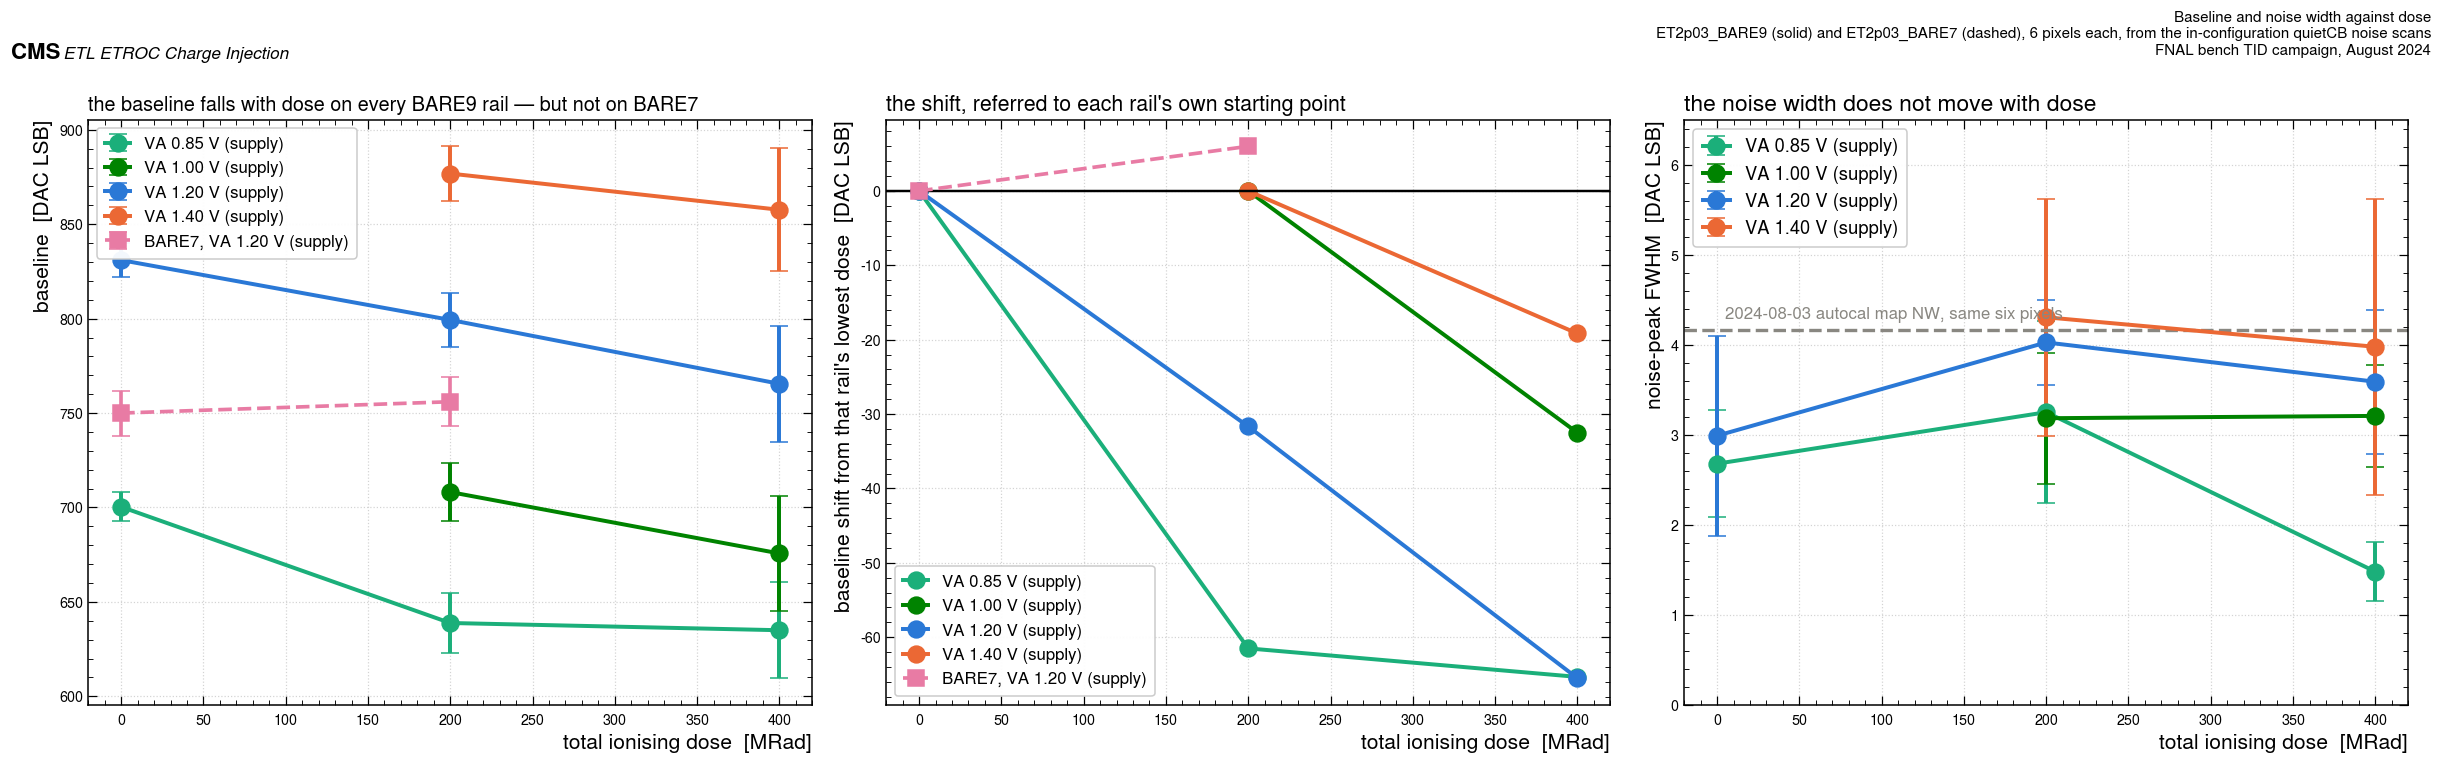

In [33]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
VACOL = {0.85: Q.C_AQUA, 1.00: Q.C_GREEN, 1.20: Q.C_BLUE, 1.40: Q.C_ORANGE}
ax = axs[0]
for va in [0.85, 1.00, 1.20, 1.40]:
    s = BD[BD.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    ax.errorbar(s.dose, s.BL_mean, yerr=s.BL_rms, fmt="-o", ms=11, lw=2.6, color=VACOL[va],
                capsize=6, label=f"VA {va:.2f} V (supply)")
ax.set_xlabel("total ionising dose  [MRad]")
s7p = BD7[BD7.va == 1.20].sort_values("dose")
if len(s7p) > 1:
    ax.errorbar(s7p.dose, s7p.BL_mean, yerr=s7p.BL_rms, fmt="--s", ms=11, lw=2.4, color=Q.C_MAG,
                capsize=6, label="BARE7, VA 1.20 V (supply)")
ax.set_ylabel("baseline  [DAC LSB]")
ax.legend(fontsize=11)
ax.set_title("the baseline falls with dose on every BARE9 rail — but not on BARE7",
             loc="left", fontsize=13)

ax = axs[1]
for va in [0.85, 1.00, 1.20, 1.40]:
    s = BD[BD.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    ax.plot(s.dose, s.BL_mean - s.BL_mean.iloc[0], "-o", ms=11, lw=2.6, color=VACOL[va],
            label=f"VA {va:.2f} V (supply)")
ax.axhline(0, color="black", lw=1.6)
ax.set_xlabel("total ionising dose  [MRad]")
if len(s7p) > 1:
    ax.plot(s7p.dose, s7p.BL_mean - s7p.BL_mean.iloc[0], "--s", ms=11, lw=2.4, color=Q.C_MAG,
            label="BARE7, VA 1.20 V (supply)")
ax.set_ylabel("baseline shift from that rail's lowest dose  [DAC LSB]")
ax.legend(fontsize=11)
ax.set_title("the shift, referred to each rail's own starting point", loc="left", fontsize=14)

ax = axs[2]
for va in [0.85, 1.00, 1.20, 1.40]:
    s = BD[BD.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    ax.errorbar(s.dose, s.NW_fwhm_mean, yerr=s.NW_fwhm_rms, fmt="-o", ms=11, lw=2.6,
                color=VACOL[va], capsize=6, label=f"VA {va:.2f} V (supply)")
ax.axhline(mp.noise_width_DAC.mean(), color=Q.GREY, ls="--", lw=2.2)
ax.text(5, mp.noise_width_DAC.mean() + 0.12, "2024-08-03 autocal map NW, same six pixels",
        fontsize=11, color=Q.GREY)
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("noise-peak FWHM  [DAC LSB]")
ax.set_ylim(0, 6.5)
ax.legend(fontsize=12)
ax.set_title("the noise width does not move with dose", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Baseline and noise width against dose",
             tag="ET2p03_BARE9 (solid) and ET2p03_BARE7 (dashed), 6 pixels each, "
                 "from the in-configuration quietCB noise scans",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig9_baseline_nw_vs_dose")
plt.show()

### The sign, stated plainly

**On `BARE9` the baseline falls with dose, by −65 DAC over 400 MRad at VA 1.20 V, and it falls on
every rail of that die that has two dose points.** On the bare ET2.01 die of notebook 01 the same
quantity *rose*, by +25 and +21 DAC over the same two dose steps at a fixed −25 °C. That
disagreement is much larger than either campaign's repeatability: the repeat 0 MRad acquisition
here reproduces the mean baseline to 0.0 DAC.

**But it is a one-die result, and the second die does not confirm it.** `BARE7`, the other
ET2.03 die, now carries its own 0 → 200 MRad step at VA 1.20 V (section 14.1). Over that step
BARE9's baseline falls by −31.7 ± 7.2 DAC and BARE7's moves by **+6.0 ± 7.3 DAC** — consistent
with no shift at all, and 3.7 σ away from BARE9. The two dies agree on the paired *gain* change
over the same step (−0.83 ± 2.08 % against −0.45 ± 2.73 %) and disagree on the baseline. So what
this campaign establishes is that **BARE9's baseline fell**; that the ET2.03 *revision's*
baseline falls with dose is **not** established, because the only other die of that revision
with a dose step does not show it. Section 14.1 is the number; every statement about the sign
elsewhere in this notebook should be read with it.

What the ET2.01-against-ET2.03 comparison cannot do, separately, is attribute the difference. The two chips are different
revisions with different voltage references, which is the interesting hypothesis; they are also
different dies, at different temperatures (−23.6 °C against −25 °C), on different rails, dosed
at different rates in different facilities. Notebook 04 lays those differences out in one table
before it draws any conclusion. What is worth carrying is the narrower operational statement,
and it is the same one notebook 01 reaches from the opposite sign: **referred to each
condition's own baseline the turn-off curves coincide**, so re-running autocalibration and
working at a fixed offset above the new baseline recovers the response either way.

The noise width does not move with dose on either die. The noise-peak FWHM is flat at 3–4 DAC across
0 → 400 MRad at every rail except the VA 0.85 V, 400 MRad outlier noted in section 8, and it
tracks the one autocalibration `NW` map the campaign left behind to within about one DAC — two
different definitions of the same thing agreeing about as well as they can be expected to.

## 12. The VA × VD rail scan

Ninety-four single acquisitions at a fixed 10 fC, over VA 0.85–1.40 V × VD 0.90–1.45 V **on the
power supply** (~0.65–1.20 V and ~0.85–1.40 V at the chip), at all three doses. Three things have
to be said before any of it is read.

* **Every voltage in this section is a supply setting.** Nominal at the chip is VA 1.40 V and
  VD 1.25 V on the supply. So the VD failures below are at ~0.85 and ~0.90 V at the chip, and
  the VA axis is again an under-voltage axis.

* **The threshold is not recorded.** Each sub-run is one acquisition at one fixed DAC that no
  directory name and no file in the tree carries, so `dac` is `NaN` for all 94 rows. They are
  not threshold-scan points and cannot be put on the offset axis.
* **Sixteen pixels are pooled.** No directory name identifies a pixel there, so the reduction
  applies no pixel selection and the moments are over all sixteen enabled pixels. That matters
  for CAL in particular: the ETROC2 power domains split the pixel matrix by column half, with
  one half's TDCs on the analog supply and the other's on the digital supply, so a pooled CAL
  responds to **both** rails and the two contributions cannot be separated in these rows.

What the scan does establish, cleanly, is where the chip stops working.

In [34]:
V2 = V.copy()
V2["dose_lab"] = V2.dose_MRad.map(lambda x: "dose untagged" if pd.isna(x) else f"{int(x)} MRad")
V2["chip_s"] = V2.chip.str.replace("ET2p03_", "", regex=False)
V2["dead"] = V2.n_hits == 0
V2.to_csv(Q.OUTDIR / "et2p03_rail_scan.csv", index=False)
print("rail sub-runs with zero decoded hits, by chip / dose / rails\n")
print(V2[V2.dead][["chip_s", "dose_lab", "va_V", "vd_V", "charge_fC", "repeat", "elapsed_h"]]
      .sort_values(["chip_s", "dose_lab", "vd_V", "va_V"]).to_string(index=False))
print("\nevery one of them is at VD <= 1.00 V except:")
print(V2[V2.dead & (V2.vd_V > 1.00)][["chip_s", "dose_lab", "va_V", "vd_V", "repeat"]].to_string(index=False))
print("\nThe campaign's own info.txt (staged here) records, independently of any decoding, that")
print("pixel auto-calibration failed at VD = 0.90 V ON THE SUPPLY (~%.2f V at the chip) after"
      % float(Q.vd_at_chip(0.90)))
print("200 MRad, and that at VD = 0.95 V supply (~%.2f V at the chip) the links and the injector"
      % float(Q.vd_at_chip(0.95)))
print("fail 'even though pixels calibrate', with 'QInj events ... empty but at right BCIDs'.")
print("Decoding those sub-runs blind returns exactly zero hits. The two agree.")
print("Nominal on the digital rail is VD = 1.25 V on the supply, so those failures are ~0.30 and")
print("~0.35 V below the nominal chip voltage, not ~0.25 and ~0.30 V as the supply labels suggest.")
print("\ncharge tag missing on %d sub-runs (the name carries no _10fC token, so the column does not"
      % int(V2.charge_fC.isna().sum()))
print("claim one, although the campaign almost certainly ran them at 10 fC like the rest).")

rail sub-runs with zero decoded hits, by chip / dose / rails

chip_s dose_lab  va_V  vd_V  charge_fC  repeat  elapsed_h
 BARE7   0 MRad   1.2  0.90       10.0       1        NaN
 BARE7   0 MRad   1.2  0.95       10.0       1        NaN
 BARE9   0 MRad   1.2  0.90        NaN       1        NaN
 BARE9 200 MRad   1.2  0.95       10.0       1   7.550000
 BARE9 200 MRad   1.2  0.95       10.0       2   7.550000
 BARE9 200 MRad   1.2  0.95       10.0       1  15.000000
 BARE9 200 MRad   1.2  1.00       10.0       2   7.783333
 BARE9 400 MRad   1.2  0.95       10.0       1  44.000000
 BARE9 400 MRad   1.2  1.30       10.0       2  42.000000

every one of them is at VD <= 1.00 V except:
chip_s dose_lab  va_V  vd_V  repeat
 BARE9 400 MRad   1.2   1.3       2

The campaign's own info.txt (staged here) records, independently of any decoding, that
pixel auto-calibration failed at VD = 0.90 V ON THE SUPPLY (~0.85 V at the chip) after
200 MRad, and that at VD = 0.95 V supply (~0.90 V at the chip) th

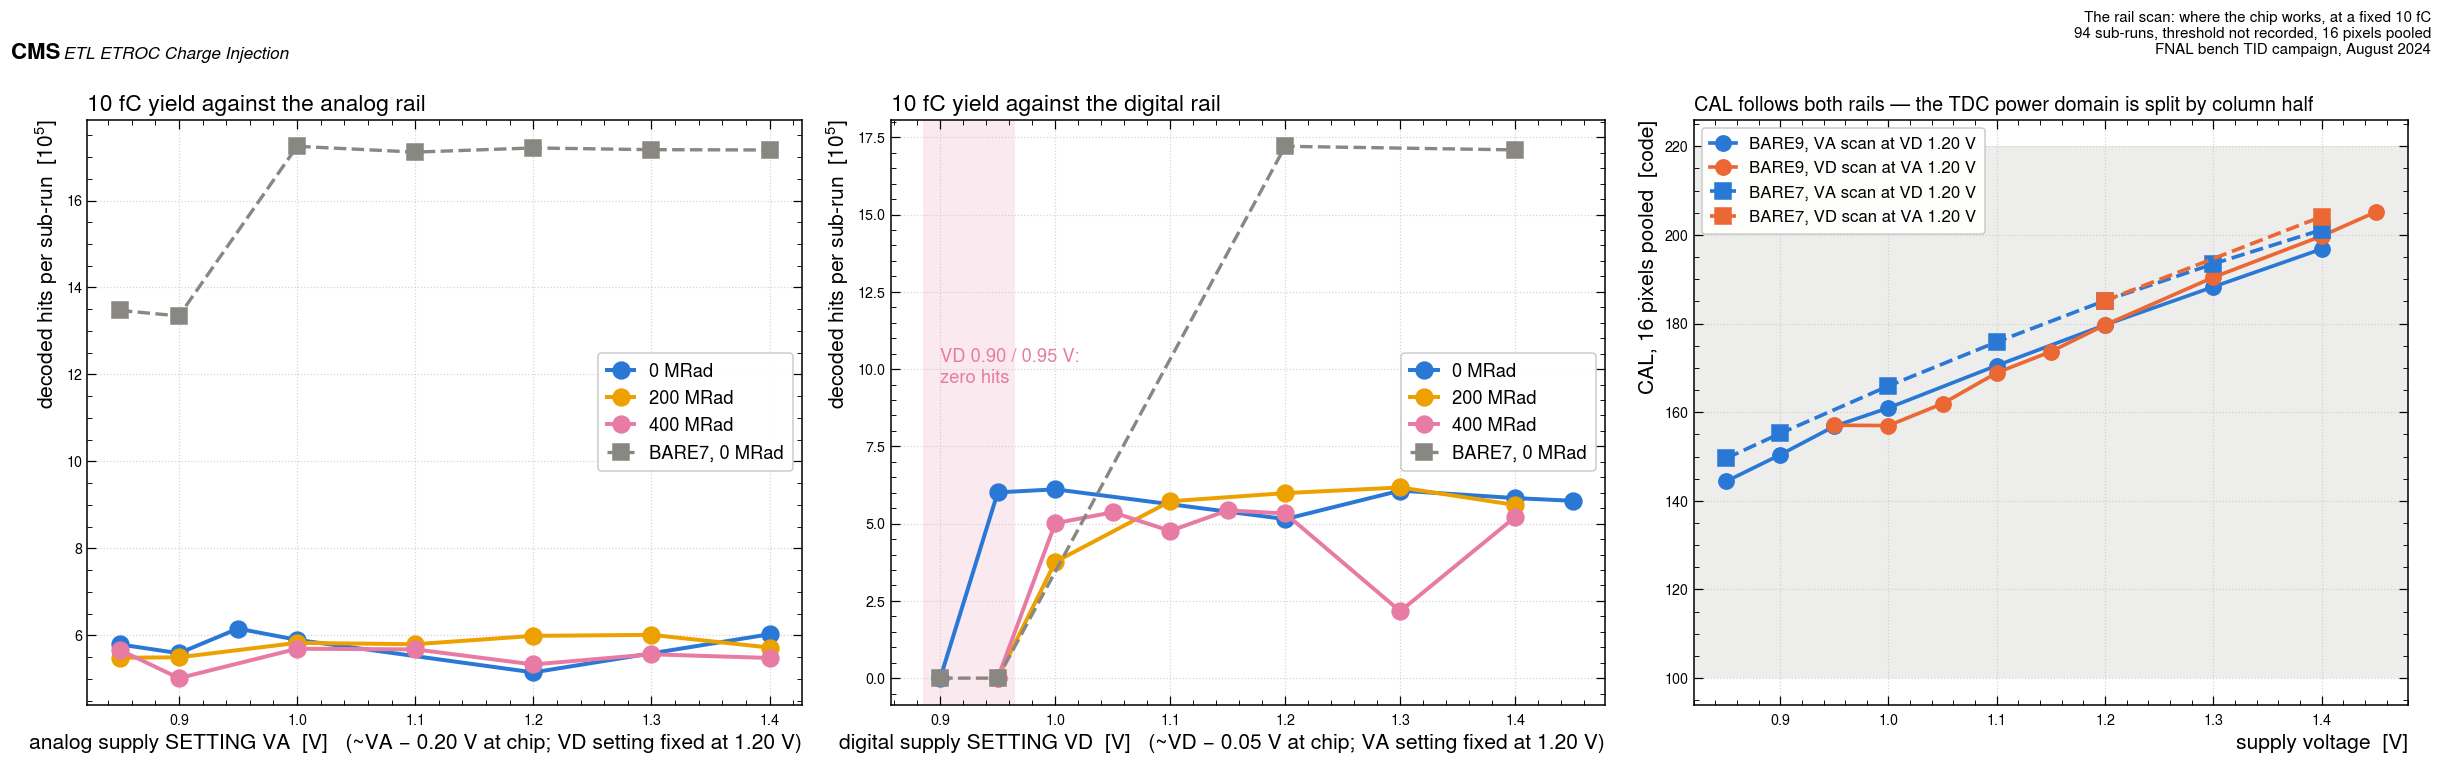

In [35]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
s = V2[(V2.chip_s == "BARE9") & (V2.vd_V == 1.20)]
for dose, lab in [(0.0, "0 MRad"), (200.0, "200 MRad"), (400.0, "400 MRad")]:
    g = s[s.dose_MRad == dose].groupby("va_V").n_hits.mean()
    if not len(g):
        continue
    ax.plot(g.index, g.values / 1e5, "-o", ms=11, lw=2.6, color=DCOL[dose], label=lab)
g7 = V2[(V2.chip_s == "BARE7") & (V2.vd_V == 1.20)].groupby("va_V").n_hits.mean()
ax.plot(g7.index, g7.values / 1e5, "--s", ms=10, lw=2.2, color=Q.GREY, label="BARE7, 0 MRad")
ax.set_xlabel("analog supply SETTING VA  [V]   (~VA − 0.20 V at chip; VD setting fixed at 1.20 V)")
ax.set_ylabel("decoded hits per sub-run  [$10^5$]")
ax.legend(fontsize=12)
ax.set_title("10 fC yield against the analog rail", loc="left", fontsize=15)

ax = axs[1]
s = V2[(V2.chip_s == "BARE9") & (V2.va_V == 1.20)]
for dose, lab in [(0.0, "0 MRad"), (200.0, "200 MRad"), (400.0, "400 MRad")]:
    g = s[s.dose_MRad == dose].groupby("vd_V").n_hits.mean()
    if not len(g):
        continue
    ax.plot(g.index, g.values / 1e5, "-o", ms=11, lw=2.6, color=DCOL[dose], label=lab)
g7 = V2[(V2.chip_s == "BARE7") & (V2.va_V == 1.20)].groupby("vd_V").n_hits.mean()
ax.plot(g7.index, g7.values / 1e5, "--s", ms=10, lw=2.2, color=Q.GREY, label="BARE7, 0 MRad")
ax.axvspan(0.885, 0.965, color=Q.C_MAG, alpha=0.16, lw=0)
ax.text(0.90, 0.55, "VD 0.90 / 0.95 V:\nzero hits", fontsize=12, color=Q.C_MAG,
        transform=ax.get_xaxis_transform())
ax.set_xlabel("digital supply SETTING VD  [V]   (~VD − 0.05 V at chip; VA setting fixed at 1.20 V)")
ax.set_ylabel("decoded hits per sub-run  [$10^5$]")
ax.legend(fontsize=12)
ax.set_title("10 fC yield against the digital rail", loc="left", fontsize=15)

ax = axs[2]
for chip, mk, ls in [("BARE9", "o", "-"), ("BARE7", "s", "--")]:
    s = V2[(V2.chip_s == chip) & (V2.vd_V == 1.20) & (~V2.dead)]
    g = s.groupby("va_V").cal_mean.mean()
    if len(g):
        ax.plot(g.index, g.values, ls, marker=mk, ms=10, lw=2.4, color=Q.C_BLUE,
                label=f"{chip}, VA scan at VD 1.20 V")
    s = V2[(V2.chip_s == chip) & (V2.va_V == 1.20) & (~V2.dead)]
    g = s.groupby("vd_V").cal_mean.mean()
    if len(g):
        ax.plot(g.index, g.values, ls, marker=mk, ms=10, lw=2.4, color=Q.C_ORANGE,
                label=f"{chip}, VD scan at VA 1.20 V")
ax.axhspan(*Q.CAL_GUARD, color=Q.GREY, alpha=0.15, lw=0)
ax.set_xlabel("supply voltage  [V]")
ax.set_ylabel("CAL, 16 pixels pooled  [code]")
ax.legend(fontsize=11)
ax.set_title("CAL follows both rails — the TDC power domain is split by column half",
             loc="left", fontsize=13)
fig.tight_layout()
Q.fig_header(fig, "The rail scan: where the chip works, at a fixed 10 fC",
             tag="94 sub-runs, threshold not recorded, 16 pixels pooled", scale=0.62,
             campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig10_rail_scan")
plt.show()

## 13. What the rail axis says about the DAC scale

Both the baseline and the gain, in DAC units, move strongly with the analog rail. That is
exactly what a reference generator powered from that rail would do, and it is why no absolute
millivolt number in this notebook should be trusted at the few-per-cent level.

The cell below states the two dependences side by side. It does **not** attempt to separate a
DAC-scale change from a real front-end change, because this campaign has no measurement that
can: there is no reference read-back, no VTemp, and no external voltage calibration anywhere in
the tree. What it can say is that the two move together and by different amounts, so it is not
a pure scale change either.

In [36]:
SC = GB[(GB.chip == "ET2p03_BARE9") & GB.dose.notna()].copy()
SC["gain_rel"] = SC.gain_dac_per_fc / SC.groupby("dose").gain_dac_per_fc.transform(
    lambda s: s.iloc[0] if len(s) else np.nan)
tab = SC.pivot_table(index="va", columns="dose", values=["gain_dac_per_fc", "BL_mean"])
print("gain [DAC/fC] and baseline [DAC] against the analog rail, per dose\n")
print(tab.round(2).to_string())
b200 = SC[SC.dose == 200].sort_values("va")
sl, ic, sle, ice, _, _ = Q.wls(b200.va.values, b200.BL_mean.values, np.full(len(b200), 1.0))
print("\nbaseline against VA at 200 MRad: %.0f +- %.0f DAC/V = %.0f mV/V under the assumed LSB"
      % (sl, sle, sl * Q.LSB_MV))
print("gain against VA at 200 MRad: %.2f -> %.2f DAC/fC over 0.85 -> 1.40 V, a factor %.2f"
      % (b200.gain_dac_per_fc.iloc[0], b200.gain_dac_per_fc.iloc[-1],
         b200.gain_dac_per_fc.iloc[-1] / b200.gain_dac_per_fc.iloc[0]))
print("baseline over the same range: %.0f -> %.0f DAC, a factor %.2f"
      % (b200.BL_mean.iloc[0], b200.BL_mean.iloc[-1], b200.BL_mean.iloc[-1] / b200.BL_mean.iloc[0]))
print("\nA pure DAC-scale change would move the two by the same factor. They do not, so part of the")
print("rail dependence is the front end and part is the reference — and nothing here separates them.")
RESULTS["gain_by_va_200MRad"] = {float(v): float(g) for v, g in zip(b200.va, b200.gain_dac_per_fc)}
RESULTS["bl_by_va_200MRad"] = {float(v): float(g) for v, g in zip(b200.va, b200.BL_mean)}
RESULTS["bl_per_volt_va_dac"] = float(sl)

gain [DAC/fC] and baseline [DAC] against the analog rail, per dose

     BL_mean                 gain_dac_per_fc            
dose   0.0     200.0   400.0           0.0   200.0 400.0
va                                                      
0.85  700.33  638.83  635.00            3.45  3.11  2.92
1.00     NaN  708.17  675.67             NaN  5.77  5.45
1.20  831.00  799.33  765.50            8.26  8.24  7.92
1.40     NaN  876.83  857.67             NaN  8.69  9.46

baseline against VA at 200 MRad: 434 +- 2 DAC/V = 170 mV/V under the assumed LSB
gain against VA at 200 MRad: 3.11 -> 8.69 DAC/fC over 0.85 -> 1.40 V, a factor 2.80
baseline over the same range: 639 -> 877 DAC, a factor 1.37

A pure DAC-scale change would move the two by the same factor. They do not, so part of the
rail dependence is the front end and part is the reference — and nothing here separates them.


## 14. BARE7 against BARE9, and BARE7's own dose step

The second die is now measured at **both ends of a dose step**: 0 MRad (VA 0.85, 1.00 and
1.20 V, from the `2024-08-14` day recovered from the removable disk `X9`) and 200 MRad
(VA 1.20 V). It does not reach 400 MRad. That gives this section two jobs rather than one:

1. **Chip against chip at matched conditions** — the same quantities on two dies of the same
   revision at the same dose and rail, which puts a number on the chip-to-chip spread. That is
   the systematic limiting every single-die dose statement in this notebook and in notebook 01,
   and it can now be done at **two** doses instead of one.
2. **BARE7's own 0 → 200 MRad step**, formed by exactly the same paired per-pixel code path as
   BARE9's in section 6. This is the one direct test in the folder of whether the ET2.03
   baseline-falls-with-dose result is a property of the **revision** or of the single die
   `BARE9` — and section 14.1 shows it does not come out the tidy way.

**The BARE7 0 MRad point really is pre-irradiation, and not only because its directory says
`0MRad`.** Notebook 00 section 7.7 carries the campaign's irradiation timeline, transcribed from
its own analysis notebook: **step 3 starts at 2024-08-14 21:27**, while that day's BARE7 register
dump — the read-back that closes the session — is stamped **2024-08-14 21:21:53**. The whole
`2024-08-14_Array_Test_Results` session therefore ended five minutes before the third
irradiation step began, and its three money-plot run directories precede that dump. That is an
independent record agreeing with the `0MRad` directory tag, and it is what lets the BARE7 dose
step be formed at all.

In [37]:
C7 = cfg_of("ET2p03_BARE7", 200, 1.20)
C7_0 = cfg_of("ET2p03_BARE7", 0, 1.20)
C9_0 = cfg_of("ET2p03_BARE9", 0, 1.20)
C9 = cfg_of("ET2p03_BARE9", 200, 1.20)
cmp_rows = []


def two(name, unit, a, b, note):
    cmp_rows.append(dict(quantity=name, unit=unit, BARE9=a, BARE7=b,
                         ratio=(b / a) if (a and a == a) else np.nan, note=note))


g9, g7 = GB[GB.config == C9].iloc[0], GB[GB.config == C7].iloc[0]
s9, s7 = SIG[SIG.config == C9].iloc[0], SIG[SIG.config == C7].iloc[0]
t9 = TOT[(TOT.config == C9) & (TOT.offset == 20)].set_index("charge_fC")
t7 = TOT[(TOT.config == C7) & (TOT.offset == 20)].set_index("charge_fC")
j9 = JIT[(JIT.config == C9) & (JIT.offset == 20)].set_index("charge_fC")
j7 = JIT[(JIT.config == C7) & (JIT.offset == 20)].set_index("charge_fC")
to9 = TO[TO.config == C9].groupby("charge_fC").turnoff_offset.mean()
to7 = TO[TO.config == C7].groupby("charge_fC").turnoff_offset.mean()
two("Preamp gain, 8-22 fC", "DAC/fC", g9.gain_dac_per_fc, g7.gain_dac_per_fc,
    "both at VA 1.20 V, VD 1.20 V, 200 MRad; different dies, different dose history")
two("Baseline", "DAC", g9.BL_mean, g7.BL_mean, "absolute DAC, so reference-scale sensitive")
two("Turn-off above baseline at 15 fC", "DAC", to9[15], to7[15], "tracks the gain")
two("S-curve width sigma", "DAC", s9.sigma_dac, s7.sigma_dac, "shared-sigma fit, same function as notebooks 01 and 02")
two("ENC = sigma / gain", "electrons", s9.ENC_e, s7.ENC_e, "ratio of the two above")
two("Noise-peak FWHM", "DAC", s9.NW_fwhm, s7.NW_fwhm, "in-configuration noise scan")
two("TOT at BL+20, 15 fC", "code", float(t9.loc[15, "tot_code_mean"]), float(t7.loc[15, "tot_code_mean"]),
    "RFSel is not recorded on either die")
two("TOA jitter at BL+20, 15 fC", "ps", float(j9.loc[15, "jitter_mean"]), float(j7.loc[15, "jitter_mean"]),
    "both close to the quantisation floor")
two("Median CAL", "code", float(M[M.config == C9].cal_mean.median()),
    float(M[M.config == C7].cal_mean.median()), "sets the ps-per-code conversion")
CMP7 = pd.DataFrame(cmp_rows)
CMP7.to_csv(Q.OUTDIR / "et2p03_bare7_vs_bare9.csv", index=False)
print("BARE7 against BARE9, both at 200 MRad, VA 1.20 V, VD 1.20 V\n")
print(CMP7.round(3).to_string(index=False))
print("\nBARE9 pixel-to-pixel gain RMS at this condition: %.2f DAC/fC (%.0f %% of the mean)"
      % (g9.gain_pixel_rms, 100 * g9.gain_pixel_rms / g9.gain_dac_per_fc))
print("BARE7 pixel-to-pixel gain RMS:                    %.2f DAC/fC (%.0f %%)"
      % (g7.gain_pixel_rms, 100 * g7.gain_pixel_rms / g7.gain_dac_per_fc))
print("chip-to-chip gain difference:                     %+.0f %%, i.e. %.2f of one pixel RMS"
      % (100 * (g7.gain_dac_per_fc / g9.gain_dac_per_fc - 1),
         abs(g7.gain_dac_per_fc - g9.gain_dac_per_fc) / g9.gain_pixel_rms))

# The same chip-against-chip comparison at the OTHER dose the two dies now share.
if C7_0 is not None and C9_0 is not None:
    g70, g90 = GB[GB.config == C7_0].iloc[0], GB[GB.config == C9_0].iloc[0]
    print("\nthe same two dies at 0 MRad, VA 1.20 V (BARE7's recovered 2024-08-14 day):")
    print("  gain     BARE9 %.2f   BARE7 %.2f   ratio %.3f" %
          (g90.gain_dac_per_fc, g70.gain_dac_per_fc, g70.gain_dac_per_fc / g90.gain_dac_per_fc))
    print("  baseline BARE9 %.1f   BARE7 %.1f   difference %+.1f DAC" %
          (g90.BL_mean, g70.BL_mean, g70.BL_mean - g90.BL_mean))
    print("  So the chip-to-chip gain ratio is %.3f at 0 MRad and %.3f at 200 MRad: the two dies"
          % (g70.gain_dac_per_fc / g90.gain_dac_per_fc, g7.gain_dac_per_fc / g9.gain_dac_per_fc))
    print("  differ by a similar factor at both doses, so the chip-to-chip term is a scale")
    print("  offset between the dies rather than something the dose creates.")

BARE7 against BARE9, both at 200 MRad, VA 1.20 V, VD 1.20 V

                        quantity      unit   BARE9   BARE7  ratio                                                                           note
            Preamp gain, 8-22 fC    DAC/fC   8.239  10.206  1.239 both at VA 1.20 V, VD 1.20 V, 200 MRad; different dies, different dose history
                        Baseline       DAC 799.333 756.000  0.946                                     absolute DAC, so reference-scale sensitive
Turn-off above baseline at 15 fC       DAC 103.167 125.000  1.212                                                                tracks the gain
             S-curve width sigma       DAC   1.280   1.190  0.930                         shared-sigma fit, same function as notebooks 01 and 02
              ENC = sigma / gain electrons 969.659 727.748  0.751                                                         ratio of the two above
                 Noise-peak FWHM       DAC   4.025   3.313  0.823    

### 14.1 BARE7's own dose step, 0 → 200 MRad at VA 1.20 V

Same six pixels, same estimator, same code path as BARE9's paired test in section 6. The three
quantities are the baseline (from the in-configuration noise scans), the paired per-pixel gain
ratio (from the binary searches), and the turn-off referred to each condition's own baseline —
the operational quantity, which on BARE9 barely moved with dose.

In [38]:
b7 = PAIR[(PAIR.chip == "ET2p03_BARE7") & (PAIR.dose_from == 0) & (PAIR.dose_to == 200)]
b9 = PAIR[(PAIR.chip == "ET2p03_BARE9") & (PAIR.dose_from == 0) & (PAIR.dose_to == 200)
          & (PAIR.va == 1.20)]
d7rows = []
for lab, r in [("ET2p03_BARE9", b9), ("ET2p03_BARE7", b7)]:
    if not len(r):
        continue
    r = r.iloc[0]
    d7rows.append(dict(chip=lab, dose_from=0, dose_to=200, va=1.20,
                       BL_shift_dac=r.BL_shift_paired_dac, BL_shift_sem=r.BL_shift_sem,
                       BL_shift_pixel_rms=r.BL_shift_pixel_rms,
                       gain_change_pct=r.gain_change_pct,
                       gain_change_sem_pct=100 * r.gain_ratio_sem,
                       n_pixels=int(r.n_pixels)))
# turn-off referred to each condition's own baseline, per charge, on both dies at both doses
to_rows = []
for lab, ca, cb in [("ET2p03_BARE9", C9_0, C9), ("ET2p03_BARE7", C7_0, C7)]:
    if ca is None or cb is None:
        continue
    a = TO[TO.config == ca].groupby("charge_fC").turnoff_offset.mean()
    b = TO[TO.config == cb].groupby("charge_fC").turnoff_offset.mean()
    for ch in sorted(set(a.index) & set(b.index)):
        to_rows.append(dict(chip=lab, charge_fC=ch, turnoff_off_0MRad=a[ch],
                            turnoff_off_200MRad=b[ch], shift_dac=b[ch] - a[ch]))
D7 = pd.DataFrame(d7rows)
TO7 = pd.DataFrame(to_rows)
D7.to_csv(Q.OUTDIR / "et2p03_bare7_dose.csv", index=False)
TO7.to_csv(Q.OUTDIR / "et2p03_turnoff_shift_by_die.csv", index=False)
print("0 -> 200 MRad at VA 1.20 V, the dose step both dies have\n")
print(D7.round(3).to_string(index=False))
print("\nturn-off above each condition's OWN baseline, 0 -> 200 MRad [DAC]\n")
print(TO7.round(2).to_string(index=False))
if len(D7) == 2:
    r9 = D7[D7.chip.str.endswith("BARE9")].iloc[0]
    r7 = D7[D7.chip.str.endswith("BARE7")].iloc[0]
    dbl = r9.BL_shift_dac - r7.BL_shift_dac
    ebl = np.hypot(r9.BL_shift_sem, r7.BL_shift_sem)
    dg = r9.gain_change_pct - r7.gain_change_pct
    eg = np.hypot(r9.gain_change_sem_pct, r7.gain_change_sem_pct)
    print("\nTHE ANSWER, and it is not the tidy one:")
    print("  baseline shift 0 -> 200 MRad:  BARE9 %+.1f +- %.1f DAC,  BARE7 %+.1f +- %.1f DAC"
          % (r9.BL_shift_dac, r9.BL_shift_sem, r7.BL_shift_dac, r7.BL_shift_sem))
    print("    BARE7's shift is %.1f sigma from zero -- consistent with NO baseline shift at all --"
          % abs(r7.BL_shift_dac / r7.BL_shift_sem))
    print("    and the two dies differ by %.1f +- %.1f DAC, i.e. %.1f sigma. The second die does"
          % (dbl, ebl, abs(dbl / ebl)))
    print("    NOT reproduce BARE9's falling baseline over the dose step they share.")
    print("  paired gain change:            BARE9 %+.2f +- %.2f %%,  BARE7 %+.2f +- %.2f %%"
          % (r9.gain_change_pct, r9.gain_change_sem_pct, r7.gain_change_pct, r7.gain_change_sem_pct))
    print("    the two agree to %.2f +- %.2f points, i.e. %.1f sigma." % (dg, eg, abs(dg / eg)))
    print("\n  So the two ET2.03 dies agree on the CHARGE response with dose and disagree on the")
    print("  THRESHOLD reference with dose. Read against section 11, that means the falling")
    print("  baseline is NOT established as a property of the revision: on the one dose step where")
    print("  a second die of the same revision can check it, the second die does not show it.")
    print("  The chip-to-chip term, which section 14 already measures as large on absolute gain, is")
    print("  large on this too. BARE9's own 0 -> 400 MRad fall (-65.5 +- 14.6 DAC) remains a")
    print("  measurement on ONE die, and BARE7 cannot test the 200 -> 400 half of it at all.")
    RESULTS["bare7_vs_bare9_bl_shift_diff_dac"] = float(dbl)
    RESULTS["bare7_vs_bare9_bl_shift_diff_sem"] = float(ebl)
    RESULTS["bare7_bl_shift_sigma_from_zero"] = float(abs(r7.BL_shift_dac / r7.BL_shift_sem))

0 -> 200 MRad at VA 1.20 V, the dose step both dies have

        chip  dose_from  dose_to  va  BL_shift_dac  BL_shift_sem  BL_shift_pixel_rms  gain_change_pct  gain_change_sem_pct  n_pixels
ET2p03_BARE9          0      200 1.2       -31.667         7.200              17.637           -0.828                2.081         6
ET2p03_BARE7          0      200 1.2         6.000         7.303              17.889           -0.447                2.725         6

turn-off above each condition's OWN baseline, 0 -> 200 MRad [DAC]

        chip  charge_fC  turnoff_off_0MRad  turnoff_off_200MRad  shift_dac
ET2p03_BARE9        6.0              28.83                30.83       2.00
ET2p03_BARE9        8.0              44.33                46.83       2.50
ET2p03_BARE9       10.0              59.83                62.83       3.00
ET2p03_BARE9       15.0             100.50               103.17       2.67
ET2p03_BARE9       22.0             153.33               162.17       8.83
ET2p03_BARE7        6.0  

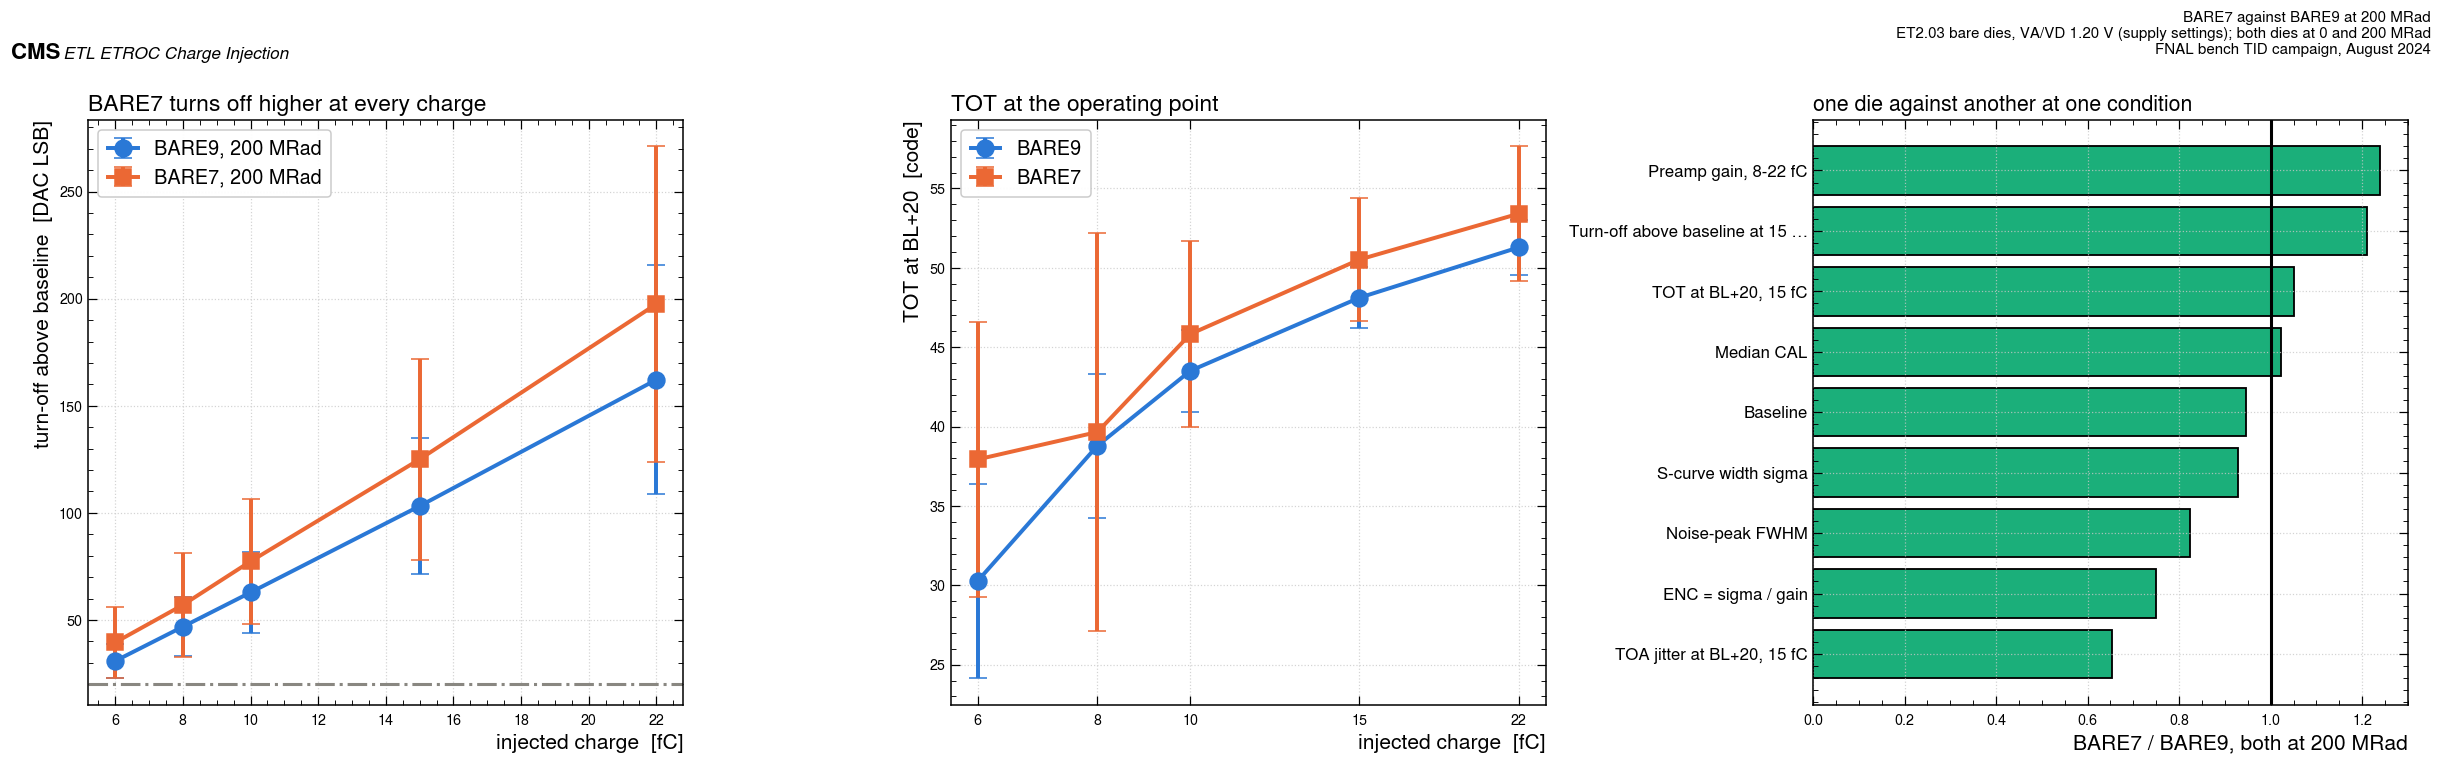

In [39]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for cfg, lab, cc, mk in [(C9, "BARE9, 200 MRad", Q.C_BLUE, "o"), (C7, "BARE7, 200 MRad", Q.C_ORANGE, "s")]:
    g = TO[TO.config == cfg].groupby("charge_fC").turnoff_offset.agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], fmt="-", marker=mk, ms=11, lw=2.6, color=cc,
                capsize=6, label=lab)
ax.axhline(Q.OP_OFFSET, color=Q.GREY, ls="-.", lw=2)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("turn-off above baseline  [DAC LSB]")
ax.legend(fontsize=13)
ax.set_title("BARE7 turns off higher at every charge", loc="left", fontsize=15)

ax = axs[1]
for cfg, lab, cc, mk in [(C9, "BARE9", Q.C_BLUE, "o"), (C7, "BARE7", Q.C_ORANGE, "s")]:
    s = TOT[(TOT.config == cfg) & (TOT.offset == 20)].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_code_mean, yerr=s.tot_code_pixel_rms, fmt="-", marker=mk,
                ms=11, lw=2.6, color=cc, capsize=6, label=lab)
Q.charge_axis(ax, charges=Q.ET2P03_CHARGES)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [code]")
ax.legend(fontsize=13)
ax.set_title("TOT at the operating point", loc="left", fontsize=15)

ax = axs[2]
r = CMP7.dropna(subset=["ratio"]).sort_values("ratio")
ax.barh(range(len(r)), r.ratio, color=Q.C_AQUA, edgecolor="black", lw=1.2)
ax.axvline(1.0, color="black", lw=2)
ax.set_yticks(range(len(r)))
ax.set_yticklabels([q if len(q) < 32 else q[:30] + "…" for q in r.quantity], fontsize=11)
ax.set_xlabel("BARE7 / BARE9, both at 200 MRad")
ax.set_title("one die against another at one condition", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "BARE7 against BARE9 at 200 MRad",
             tag="ET2.03 bare dies, VA/VD 1.20 V (supply settings); both dies at 0 and 200 MRad",
             scale=0.62, campaign=Q.ET2P03_CAMPAIGN)
Q.save_fig(fig, "et2p03_fig11_bare7_vs_bare9")
plt.show()

## 15. Summary

**Read every VA and VD in this table as a power-supply setting.** The reference condition below
is VA 1.20 V (supply) ≈ **1.00 V at the chip, about 0.2 V under the nominal 1.2 V**; it is the
reference only because it is the sole analog setting with a 0 MRad money plot. The one nominal
setting, VA 1.40 V (supply) ≈ 1.20 V at the chip, has 200 and 400 MRad only, and its
200 → 400 MRad step is quoted in section 6.

In [40]:
t20r = TOT[(TOT.config == CFG0) & (TOT.offset == 20)].set_index("charge_fC")
j20r = JIT[(JIT.config == CFG0) & (JIT.offset == 20)].set_index("charge_fC")
to_r = TO[TO.config == CFG0].groupby("charge_fC").turnoff_offset.agg(["mean", "std"])
p400 = PAIR[(PAIR.va == 1.20) & (PAIR.dose_from == 0) & (PAIR.dose_to == 400)]
p400 = p400.iloc[0] if len(p400) else None
SUMMARY = pd.DataFrame([
    dict(n=1, quantity="Preamp gain (charge-to-threshold), 8–22 fC, VA 1.20 V (supply), 0 MRad",
         value=f"{REF.gain_dac_per_fc:.2f} ± {REF.gain_sem:.2f}", unit="DAC/fC",
         pixel_rms=f"{REF.gain_pixel_rms:.2f}", label="DERIVED"),
    dict(n=2, quantity="the same in volts, under the assumed LSB",
         value=f"{REF.gain_mv_per_fc:.2f} ± {REF.gain_mv_sem:.2f}", unit="mV/fC",
         pixel_rms=f"{REF.gain_mv_pixel_rms:.2f}", label="DERIVED — LSB assumed, section 13"),
    dict(n=3, quantity="Preamp gain over the analog rail, supply 0.85 → 1.40 V (~0.65 → ~1.20 V at chip), 200 MRad",
         value="%.2f → %.2f" % (b200.gain_dac_per_fc.iloc[0], b200.gain_dac_per_fc.iloc[-1]),
         unit="DAC/fC", pixel_rms="—", label="DERIVED"),
    dict(n=4, quantity="Turn-off above baseline at 15 fC, VA 1.20 V, 0 MRad",
         value=f"{to_r.loc[15, 'mean']:.1f}", unit="DAC", pixel_rms=f"{to_r.loc[15, 'std']:.1f}",
         label="RAW (the search's own converged DAC), referred to the noise-peak baseline"),
    dict(n=5, quantity="TOT at BL+20, 15 fC, VA 1.20 V, 0 MRad",
         value=f"{t20r.loc[15, 'tot_code_mean']:.1f}",
         unit=f"code = {t20r.loc[15, 'tot_ns_mean']:.2f} ns",
         pixel_rms=f"{t20r.loc[15, 'tot_code_pixel_rms']:.1f}", label="DERIVED"),
    dict(n=6, quantity="TOA jitter at BL+20, 15 fC, VA 1.20 V, 0 MRad",
         value=f"{j20r.loc[15, 'jitter_mean']:.1f}  (median {j20r.loc[15, 'jitter_median']:.1f})",
         unit="ps", pixel_rms=f"{j20r.loc[15, 'jitter_pixel_rms']:.1f}",
         label="DERIVED — near the quantisation floor"),
    dict(n=7, quantity="TOA jitter at BL+20, 6 fC, VA 1.20 V, 0 MRad",
         value=f"{j20r.loc[6, 'jitter_mean']:.1f}  (median {j20r.loc[6, 'jitter_median']:.1f})",
         unit="ps", pixel_rms=f"{j20r.loc[6, 'jitter_pixel_rms']:.1f}",
         label="DERIVED — above the floor; the mean is pulled by the widest pixel, hence the median"),
    dict(n=8, quantity=f"S-curve width σ ({int(SREF.n_curves)} curves, shared σ)",
         value=f"{SREF.sigma_dac:.2f} ± {SREF.sigma_sd:.2f}",
         unit=f"DAC = {SREF.sigma_mv:.3f} mV", pixel_rms="—", label="DERIVED"),
    dict(n=9, quantity="ENC = σ / gain, VA 1.20 V, 0 MRad", value=f"{SREF.ENC_e:.0f}",
         unit="electrons", pixel_rms="—", label="DERIVED — bare die, no input load"),
    dict(n=10, quantity="Noise-peak FWHM, VA 1.20 V, 0 MRad",
         value=f"{SREF.NW_fwhm:.2f} ± {SREF.NW_fwhm_rms / np.sqrt(6):.2f}", unit="DAC",
         pixel_rms=f"{SREF.NW_fwhm_rms:.2f}",
         label=f"DERIVED; the autocal map gives NW {mp.noise_width_DAC.mean():.2f} DAC"),
    dict(n=11, quantity="Minimum charge reaching BL+20, VA 1.20 V, 0 MRad",
         value=f"{REF.Qmin_at_off20_fC:.1f} ± {REF.Qmin_sem:.1f}", unit="fC", pixel_rms="—",
         label="DERIVED, extrapolated"),
    dict(n=12, quantity="TOT-to-charge law at BL+20, VA 1.20 V, 0 MRad",
         value=f"TOT = {f20['a']:.1f} + {f20['b']:.1f} ln(Q/fC)",
         unit=f"χ²/ndf {f20['chi2_ndf']:.1f}", pixel_rms="—", label="DERIVED, valid 6–22 fC"),
    dict(n=13, quantity="TDC quantisation floor, LSB/√12", value=f"{floor_ref:.2f}", unit="ps",
         pixel_rms="—", label=f"DERIVED, TOA LSB {lsb_ref:.1f} ps at CAL {CAL_MED[CFG0]:.0f}"),
    dict(n=14, quantity="Walk with charge, 6→22 fC at BL+20", value=f"{walk_ref:+.0f}", unit="ps",
         pixel_rms="—", label="DERIVED, median over pixels"),
    dict(n=15, quantity="Baseline shift, 0 → 400 MRad at VA 1.20 V, BARE9",
         value=f"{bl4 - bl0:+.1f}", unit="DAC", pixel_rms="—",
         label="DERIVED — sign opposite to ET2.01, but see row 17: the second die does not repeat it"),
    dict(n=17, quantity="Baseline shift, 0 → 200 MRad at VA 1.20 V, BARE9 vs BARE7",
         value=(f"{float(D7[D7.chip.str.endswith('BARE9')].BL_shift_dac.iloc[0]):+.1f} ± "
                f"{float(D7[D7.chip.str.endswith('BARE9')].BL_shift_sem.iloc[0]):.1f}   vs   "
                f"{float(D7[D7.chip.str.endswith('BARE7')].BL_shift_dac.iloc[0]):+.1f} ± "
                f"{float(D7[D7.chip.str.endswith('BARE7')].BL_shift_sem.iloc[0]):.1f}")
               if len(D7) == 2 else "not available",
         unit="DAC", pixel_rms="—",
         label="DERIVED — the two ET2.03 dies DISAGREE on the baseline shift (section 14.1)"),
    dict(n=16, quantity="Paired gain change, 0 → 400 MRad at VA 1.20 V",
         value=("%+.1f ± %.1f" % (p400.gain_change_pct, 100 * p400.gain_ratio_sem)) if p400 is not None else "—",
         unit="%", pixel_rms=f"{100 * p400.gain_ratio_pixel_rms:.1f}" if p400 is not None else "—",
         label="DERIVED — same six pixels, paired ratio"),
])
SUMMARY.to_csv(Q.OUTDIR / "et2p03_summary_numbers.csv", index=False)
print(SUMMARY.to_string(index=False))

 n                                                                                   quantity                         value           unit pixel_rms                                                                                label
 1                     Preamp gain (charge-to-threshold), 8–22 fC, VA 1.20 V (supply), 0 MRad                   8.26 ± 1.19         DAC/fC      2.91                                                                              DERIVED
 2                                                   the same in volts, under the assumed LSB                   3.22 ± 0.46          mV/fC      1.14                                                    DERIVED — LSB assumed, section 13
 3 Preamp gain over the analog rail, supply 0.85 → 1.40 V (~0.65 → ~1.20 V at chip), 200 MRad                   3.11 → 8.69         DAC/fC         —                                                                              DERIVED
 4                                        Turn-off above baselin

In [41]:
RESULTS.update(
    chip="ET2p03_BARE9", second_chip="ET2p03_BARE7", revision="ET2.03",
    kind="bare die, no sensor", campaign="FNAL bench TID, August 2024",
    vref="internal (VrefGen_PD = 0; board wiring not recorded)",
    condition=REF.label, temperature_C_range=[float(PTS.temperature_C.min()), float(PTS.temperature_C.max())],
    n_pixels=int(REF.n_pixels), pixels=[f"({r},{c})" for r, c in Q.ET2P03_PIXELS],
    charges_fC=[float(c) for c in Q.ET2P03_CHARGES], vd_V=1.20, va_V=1.20,
    gain_sem=float(REF.gain_sem), gain_pixel_rms=float(REF.gain_pixel_rms),
    gain_mv_per_fc=float(REF.gain_mv_per_fc), gain_fit_range_fC=[Q.ET2P03_QLO, Q.ET2P03_QHI],
    Qmin_at_off20_fC=float(REF.Qmin_at_off20_fC), Qmin_sem=float(REF.Qmin_sem),
    intercept_offset_dac=float(REF.intercept_offset_dac), BL_mean=float(REF.BL_mean),
    gain_by_dose_va120={int(r.dose): float(r.gain_dac_per_fc)
                        for _, r in GB[(GB.chip == "ET2p03_BARE9") & (GB.va == 1.20) & GB.dose.notna()].iterrows()},
    sigma_by_dose_va120={int(r.dose): float(r.sigma_dac)
                         for _, r in SIG[(SIG.chip == "ET2p03_BARE9") & (SIG.va == 1.20) & SIG.dose.notna()].iterrows()},
    enc_by_dose_va120={int(r.dose): float(r.ENC_e)
                       for _, r in SIG[(SIG.chip == "ET2p03_BARE9") & (SIG.va == 1.20) & SIG.dose.notna()].iterrows()},
    jitter_off20_by_charge={int(c): float(j20r.loc[c, "jitter_mean"]) for c in j20r.index},
    jitter_off20_rms_by_charge={int(c): float(j20r.loc[c, "jitter_pixel_rms"]) for c in j20r.index},
    jitter_off20_n_by_charge={int(c): int(j20r.loc[c, "n_pixels"]) for c in j20r.index},
    jitter_off20_median_by_charge={int(c): float(j20r.loc[c, "jitter_median"]) for c in j20r.index},
    tot_off20_by_charge={int(c): float(t20r.loc[c, "tot_code_mean"]) for c in t20r.index},
    tot_off20_rms_by_charge={int(c): float(t20r.loc[c, "tot_code_pixel_rms"]) for c in t20r.index},
    turnoff_off_by_charge={int(c): float(to_r.loc[c, "mean"]) for c in to_r.index},
    turnoff_off_rms_by_charge={int(c): float(to_r.loc[c, "std"]) for c in to_r.index},
    paired_gain_change_0_to_400_pct=float(p400.gain_change_pct) if p400 is not None else None,
    paired_gain_change_sem_pct=float(100 * p400.gain_ratio_sem) if p400 is not None else None,
)
with open(Q.OUTDIR / "et2p03_results.json", "w") as fh:
    json.dump(RESULTS, fh, indent=1)
print("written to outputs/ for notebook 04:")
for p in sorted(Q.OUTDIR.glob("et2p03_*")):
    print("  %-46s %8d B" % (p.name, p.stat().st_size))

written to outputs/ for notebook 04:
  et2p03_bare7_dose.csv                               340 B
  et2p03_bare7_vs_bare9.csv                          1083 B
  et2p03_baseline_by_condition.csv                   2021 B
  et2p03_baseline_by_condition_pixel.csv            13839 B
  et2p03_cal_window_quality.csv                      1558 B
  et2p03_gain_by_condition.csv                       5489 B
  et2p03_gain_fits.csv                              31978 B
  et2p03_jitter_by_offset.csv                       35991 B
  et2p03_paired_dose_ratios.csv                      1751 B
  et2p03_rail_scan.csv                              59367 B
  et2p03_reproduction_ledger.csv                      900 B
  et2p03_results.json                                4721 B
  et2p03_scurve_sigma_by_condition.csv               4038 B
  et2p03_summary_numbers.csv                         2021 B
  et2p03_tot_logfits.csv                             8544 B
  et2p03_tot_vs_charge_offsets.csv                  61084 B
  e

## 16. Reproduction ledger

The reduction that produced these tables documents a handful of its own numbers — point counts,
hit counts, the autocalibration baselines, and the money-plot turn-off DACs of one pixel at one
rail. Every one of them is recomputed above from the staged files and compared here, so that a
reader can see the notebook and the reduction agree rather than take it on trust.

In [42]:
LED = pd.DataFrame(LEDGER)
LED["|diff|"] = LED["diff"].abs()
print(LED[["quantity", "recomputed", "published", "|diff|", "tol", "unit", "agrees"]]
      .round(4).to_string(index=False))
LED.to_csv(Q.OUTDIR / "et2p03_reproduction_ledger.csv", index=False)
n_ok = int(LED.agrees.sum())
print("\n%d of %d checks agree within tolerance." % (n_ok, len(LED)))
if n_ok < len(LED):
    print("\nDisagreements:")
    print(LED[~LED.agrees][["quantity", "recomputed", "published", "|diff|", "unit"]]
          .round(4).to_string(index=False))

                                              quantity  recomputed  published  |diff|  tol unit  agrees
                  money-plot points in the union table     29828.0      29828     0.0    0         True
          hits behind them, before the pixel selection 239969849.0  239969849     0.0    0         True
                   hits removed by the pixel selection     49194.0      49194     0.0    0         True
                                       binary searches       450.0        450     0.0    0         True
                                           noise scans        90.0         90     0.0    0         True
                             map baseline, pixel (0,0)       822.0        822     0.0    0  DAC    True
                           map baseline, pixel (12,14)       849.0        849     0.0    0  DAC    True
 turn-off DAC, BARE9 0 MRad VA 1.20, pixel (0,0), 6 fC       858.0        858     0.0    0  DAC    True
 turn-off DAC, BARE9 0 MRad VA 1.20, pixel (0,0), 8 fC       877

---

## 17. Caveats

These limit what any number above can be used for, and none of them is removed by care in the
analysis.

1. **BARE7 reaches 200 MRad, not 400.** Its 0 MRad day (`2024-08-14`, 8.88 GB) was recovered
   from the removable disk `X9` and decoded, so the second die does now carry a real dose
   difference — but only 0 → 200 MRad, and only at VA 1.20 V (its 0 MRad day also covers
   VA 0.85 and 1.00 V, its 200 MRad day does not). Every 400 MRad statement in this notebook
   still rests on the single die `BARE9`.
2. **The `2024-08-03` acquisition carries no dose or temperature token.** Its run directory is
   simply `1p2VD_1p2VA`. It is treated here as an independent repeat of the 0 MRad, VA 1.20 V
   condition — which is what its position in the campaign says it is — and it is used to set a
   repeatability floor rather than as a dose point.
3. **No monitoring data of any kind.** No power-supply or LV-current log, no temperature log, no
   `PowerHistory` sqlite, no baseline history — none of the auxiliary streams that notebooks 00
   and 02 plot for the January campaigns exists for August 2024. The only current measurement
   anywhere is one sentence of prose in `info.txt`. `TS_PD = 0` says the on-chip temperature
   sensor had power; no VTemp value was stored.
4. **Temperature is name-parsed only**, to 0.1 °C, is a plate reading rather than a die reading,
   and was **not scanned**: every condition sits between −23.2 and −23.9 °C. So this campaign
   cannot say anything about the temperature coefficient of anything, and the ET2.01 campaigns'
   disagreement about the sign of that coefficient is untouched by it.
5. **Six pixels, two dies.** All six are in columns 0 and 14, i.e. one in each power half of the
   matrix, but the sample is half the size of notebook 01's and a third of the array's corner
   behaviour is unsampled. A single outlying pixel moves a mean visibly, which is why the money
   plots are shown as medians with an inter-quartile band.
6. **RFSel is not recorded** — not in a directory name, not in the reduction, and the register
   dumps that survive are peripheral configuration, not per-pixel. RFSel sets the preamplifier
   feedback resistance and therefore both gain and TOT, so it remains the single largest
   unquantified systematic here, exactly as in notebooks 01 and 02.
7. **The DAC-to-millivolt scale is assumed, and section 13 shows it moves.** Both the baseline
   and the gain in DAC units depend strongly on the analog rail, which is what a reference
   generator powered from that rail would do. No reference read-back and no external voltage
   calibration exists in this campaign, so no millivolt number here is better than indicative.
8. **The internal-reference statement is an inference from wiring, not a register read.**
   `VrefGen_PD = 0` proves the generator was powered up. Which reference the DAC actually used
   is board wiring and has no register bit.
9. **The binary search does not resolve the efficiency turn-off on about half the searches**
   (section 5), and the threshold sweep cannot help because its upper bound was set to the
   search's own answer. The turn-off carried here is the campaign's own definition, which agrees
   with notebook 01's estimator to well under one DAC wherever the comparison is possible.
10. **Twenty searches ran into the 10-bit DAC ceiling** and are lower limits rather than
    measurements. They are kept in every table and the gain fit is quoted both with and without
    them.
11. **The 94 rail sub-runs have no recorded threshold and pool sixteen pixels**, so they are a
    yield-and-CAL measurement, never a threshold-scan point, and the two families are never
    mixed in one fit.
12. **TOA, TOT and CAL are raw TDC codes** with no time-walk correction applied. The reduction
    writes two sets of per-point moments: plain means and standard deviations over every hit at
    the pixel, and the same over the hits inside the per-hit CAL window
    `|CAL − cal_mode| ≤ 3` (section 4.4). This notebook quotes the **CAL-windowed** ones,
    because a hit with a wrong CAL has a wrong TOA by construction; the raw ones are kept in
    every table under a `_raw` suffix and both are plotted side by side in section 4.4.
    That window is the one and only per-hit selection anywhere in this folder, and it is a
    data-integrity criterion, not a physics cut. It does **not** catch everything: a smaller,
    TOA-only class survives it (§4.4) and is flagged rather than cut. **no threshold point, pixel, charge or
    condition is dropped anywhere in this notebook**; what varies is coverage, and every pooled
    quantity reports its own `n`.